# Analysis of uoe5 pipeline run
Reran antibody panel 1 with new updates within the pipeline, resutling in run uoe5.

Major pipeline changes include more quality control mesasures focused on organelle channels (lysosome, endosome, and mitochondria) - I added the contrast check that we run for the nuclues channel to script 3 to check each channel before segmentation is preformed. The organelle channels are generally more dim than the nuclues channel, so the threshold for QC is quite a bit lower than that of the nucleus channel.

The goals here are to preform the prior PCA analyses (plus additional analysis on the genotype level, manual focused analsysis, and structure level analysis) and assess whether we reduced the number of poor quality images that make it to this analysis stage. 

In [1]:
import pathlib as Path
import pandas as pd
import os

import glob

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
import io
import matplotlib.pyplot as plt

# pip install python-pptx  (if not already installed)
from pptx import Presentation
from pptx.util import Inches, Pt

# ===========================================================================
# Figure capture: wrap plt.show so EVERY plot is grabbed, no per-call edits.
# ===========================================================================
_CAPTURED = []            # list of (title, png_bytes)
_CAPTURE_ON = True        # flip to False to pause capture for a cell


def _best_title(fig):
    """Pull a slide title from the figure: suptitle first, else first axes title."""
    # suptitle (used by scree / variant_pca)
    if getattr(fig, "_suptitle", None) is not None and fig._suptitle.get_text():
        return fig._suptitle.get_text()
    for ax in fig.axes:
        if ax.get_title():
            return ax.get_title()
    return None


_orig_show = plt.show

def _capturing_show(*args, **kwargs):
    if _CAPTURE_ON:
        fig = plt.gcf()
        # skip empty figures (no axes / nothing drawn)
        if fig.axes:
            buf = io.BytesIO()
            fig.savefig(buf, format="png", dpi=150, bbox_inches="tight")
            buf.seek(0)
            _CAPTURED.append((_best_title(fig), buf.getvalue()))
    return _orig_show(*args, **kwargs)

plt.show = _capturing_show
print("Figure capture ON — every plt.show() will be collected.")


# ===========================================================================
# Build the deck (call once at the very end of the notebook).
# ===========================================================================
def build_pptx(path, captured=None, widescreen=True):
    captured = _CAPTURED if captured is None else captured
    prs = Presentation()
    if widescreen:
        prs.slide_width = Inches(13.333)
        prs.slide_height = Inches(7.5)
    blank = prs.slide_layouts[6]   # fully blank

    sw = prs.slide_width
    sh = prs.slide_height
    for title, png in captured:
        slide = prs.slides.add_slide(blank)
        top = Inches(0.1)
        if title:
            tb = slide.shapes.add_textbox(Inches(0.3), Inches(0.1),
                                          sw - Inches(0.6), Inches(0.6))
            tf = tb.text_frame
            tf.text = title
            tf.paragraphs[0].font.size = Pt(18)
            top = Inches(0.8)

        pic = slide.shapes.add_picture(io.BytesIO(png), Inches(0), top)
        # scale to fit the slide while preserving aspect ratio
        avail_w = sw
        avail_h = sh - top - Inches(0.1)
        scale = min(avail_w / pic.width, avail_h / pic.height)
        pic.width = int(pic.width * scale)
        pic.height = int(pic.height * scale)
        pic.left = int((sw - pic.width) / 2)   # center horizontally

    prs.save(path)
    print(f"wrote {len(captured)} slides -> {path}")


def restore_show():
    """Undo the monkeypatch (optional, e.g. before re-running interactively)."""
    plt.show = _orig_show
    print("Figure capture OFF — plt.show restored.")

Figure capture ON — every plt.show() will be collected.


## Load nucleus feature data
Load in nuclei feature data merged with metadata

In [3]:
uoe5_nucleus_output_fn = "/data/kelpschdj/iNDI/Production/notebooks/analysis_uoe5/uoe5_nucleus_output.parquet"
df = pd.read_parquet(uoe5_nucleus_output_fn)

df["Batch"] = df["Batch"].astype("Int64").astype(str)  # Int64 first handles any NaN

print(df.head())
print(df.columns.tolist())

   label     area  intensity_mean  intensity_max  intensity_min  \
0      1   4939.0     3642.956266         6248.0         1735.0   
1      2   9671.0     6493.838693        27547.0         1174.0   
2      3   6054.0     4234.435580        10726.0          883.0   
3      4   8794.0      960.669093         1456.0          608.0   
4      5  12435.0     4042.183353        13133.0         1411.0   

   intensity_std   centroid-0   centroid-1  eccentricity  solidity  ...  \
0     891.057838    24.399069  1195.013768      0.842756  0.983277  ...   
1    3302.626429   409.897839  1343.616379      0.729209  0.970302  ...   
2    1676.650264   796.202346   620.880410      0.661181  0.967247  ...   
3     197.895244   964.316579    67.486354      0.575190  0.969036  ...   
4    1584.921888  1000.838118   721.246321      0.713834  0.961122  ...   

   Variant  Genotype  Gene_Var_Type  Cell_Line_Info  Source Asp PosID AbPanel  \
0     None      None       KOLF2.1J            None  manual      

In [4]:
print(f"Total number of images: {df[['filename', 'Plate_ID']].drop_duplicates().shape[0]}")
print(f"Total number of nuclei (before QC): {len(df)}")
print(f"Total number of nuclei (after QC): {len(df[df['selected'] == True])}")

Total number of images: 204887
Total number of nuclei (before QC): 2071389
Total number of nuclei (after QC): 1046112


## Nucleus summary data

In [5]:
group_cols = ["iNDI_Plate_ID", "Source", "Gene_Var_Type"]

before = (
    df.groupby(group_cols)
      .agg(images_before=("image_name", "nunique"),
           wells_before=("Well_ID", "nunique"),
           nuclei_before=("image_name", "size"))
)

after = (
    df[df["selected"]]
      .groupby(group_cols)
      .agg(images_after=("image_name", "nunique"),
           wells_after=("Well_ID", "nunique"),
           nuclei_after=("image_name", "size"))
)

summary = (
    before.join(after, how="left")
          .fillna({"images_after": 0, "wells_after": 0, "nuclei_after": 0})
          .astype({"images_after": int, "wells_after": int, "nuclei_after": int})
          .reset_index()
)

# reorder for readability
summary = summary[[
    "iNDI_Plate_ID", "Source", "Gene_Var_Type",
    "wells_before", "wells_after",
    "images_before", "images_after",
    "nuclei_before", "nuclei_after",
]]

# print grouped by plate + source
for (plate, source), grp in summary.groupby(["iNDI_Plate_ID", "Source"]):
    print(f"\n=== iNDI_Plate_ID: {plate} ({source}) ===")
    print(grp.drop(columns=["iNDI_Plate_ID", "Source"]).to_string(index=False))

# summary.to_csv(
#     "/data/kelpschdj/iNDI/Production/outputs/filtering_summary.csv",
#     index=False,
# )
print("Wrote filtering_summary.csv")


=== iNDI_Plate_ID: INDI00002D (automated) ===
    Gene_Var_Type  wells_before  wells_after  images_before  images_after  nuclei_before  nuclei_after
 FUS_R495X_REV/WT            48           48           1644          1605          13039          7622
FUS_R495X_SNV/SNV            48           48           1643          1605          14567          7740
 FUS_R495X_SNV/WT            48           48           1666          1644          16749          9176
         KOLF2.1J            96           96           3335          3307          36582         20098
 VCP_R159H_REV/WT            48           48           1367          1250           4540          3134
VCP_R159H_SNV/SNV            48           48           1665          1658          18279         10294
 VCP_R159H_SNV/WT            48           48           1626          1619          20371         10820

=== iNDI_Plate_ID: INDI00007D (automated) ===
       Gene_Var_Type  wells_before  wells_after  images_before  images_after  nucl

In [6]:
df = df[df["selected"]]

# Primary analysis
## ROI level data
### Feature assessment and PCA loadings
Broad assessment of nuclei features before PCA

#### Helper functions

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# candidate regionprops features (from script 1)
CANDIDATE_FEATURES = [
    # size
    "area", "perimeter", "feret_diameter_max",
    "axis_major_length", "axis_minor_length",
    # intensity (DAPI)
    "intensity_mean", "intensity_max", "intensity_min", "intensity_std",
    # shape
    "eccentricity", "solidity",
]
# pruned set fed to PCA (after the |r|>0.9 review)
PCA_FEATURES = [
    "area", "intensity_mean", "intensity_std",
    "eccentricity", "solidity", "aspect_ratio",
]


def feature_correlation(data, features=CANDIDATE_FEATURES,
                        title="Nuclear feature cross-correlation (raw)", show=True):
    """Pearson corr heatmap + list of |r|>0.9 pairs. Returns the corr matrix."""
    features = [c for c in features if c in data.columns]
    X = data[features].replace([np.inf, -np.inf], np.nan)
    corr = X.corr(method="pearson")

    if show:
        plt.figure(figsize=(9, 7))
        im = plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
        plt.xticks(range(len(features)), features, rotation=90, fontsize=8)
        plt.yticks(range(len(features)), features, fontsize=8)
        plt.colorbar(im, label="Pearson r")
        plt.title(title)
        plt.tight_layout(); plt.show()

    hi = (corr.abs() > 0.9) & (corr.abs() < 1.0)
    pairs = [(a, b, round(corr.loc[a, b], 3))
             for i, a in enumerate(features)
             for b in features[i + 1:] if hi.loc[a, b]]
    print("Highly correlated pairs (|r| > 0.9):")
    for a, b, r in sorted(pairs, key=lambda t: -abs(t[2])):
        print(f"  {r:+.3f}  {a:22s} {b}")
    return corr


def fit_pca(data, features=PCA_FEATURES, add_aspect_ratio=True,
            show_scree=True, show_loadings=True, label=""):
    """Add aspect_ratio, drop NaN/inf, scale, and fit PCA.

    Operates on a COPY -- does not mutate the input or any global. Returns
    (scored_df, pca, features_used) where scored_df has PC1..PCn columns.
    """
    data = data.copy()
    if add_aspect_ratio and {"axis_minor_length", "axis_major_length"} <= set(data.columns):
        data["aspect_ratio"] = data["axis_minor_length"] / data["axis_major_length"]

    features = [c for c in features if c in data.columns]
    print(f"[{label}] using FEATURES:", features)

    before = len(data)
    X_df = data[features].replace([np.inf, -np.inf], np.nan)
    keep = X_df.notna().all(axis=1)
    data = data[keep].reset_index(drop=True)
    X_df = X_df[keep].reset_index(drop=True)
    print(f"[{label}] dropped {before - len(data)} rows with NaN/inf; {len(data)} remain")

    X = StandardScaler().fit_transform(X_df.values)
    pca = PCA(n_components=len(features))
    scores = pca.fit_transform(X)
    for i in range(scores.shape[1]):
        data[f"PC{i+1}"] = scores[:, i]

    ev = pca.explained_variance_ratio_
    print(f"[{label}] EVR:", ev.round(3))
    print(f"[{label}] cumulative:", np.cumsum(ev).round(3))

    if show_scree:
        fig, ax = plt.subplots(1, 2, figsize=(11, 4))
        ax[0].bar(range(1, len(ev) + 1), ev)
        ax[0].set_xlabel("PC"); ax[0].set_ylabel("explained variance ratio")
        ax[1].plot(range(1, len(ev) + 1), np.cumsum(ev), marker="o")
        ax[1].axhline(0.9, ls="--", c="gray"); ax[1].set_xlabel("PC")
        ax[1].set_ylabel("cumulative EVR"); ax[1].set_ylim(0, 1.02)
        if label:
            fig.suptitle(f"{label} — scree")
        plt.tight_layout(); plt.show()

    if show_loadings:
        loadings = pd.DataFrame(
            pca.components_.T, index=features,
            columns=[f"PC{i+1}" for i in range(len(features))],
        )
        print(loadings.round(3))
        n_show = min(6, len(features))
        plt.figure(figsize=(1.6 * n_show, 0.4 * len(features) + 1))
        im = plt.imshow(loadings.iloc[:, :n_show], cmap="RdBu_r",
                        vmin=-1, vmax=1, aspect="auto")
        plt.xticks(range(n_show), [f"PC{i+1}" for i in range(n_show)])
        plt.yticks(range(len(features)), features, fontsize=9)
        plt.colorbar(im, label="Loading")
        plt.title(f"{label} — Nuclear PCA loadings" if label else "Nuclear PCA loadings")
        plt.tight_layout(); plt.show()

    return data, pca, features


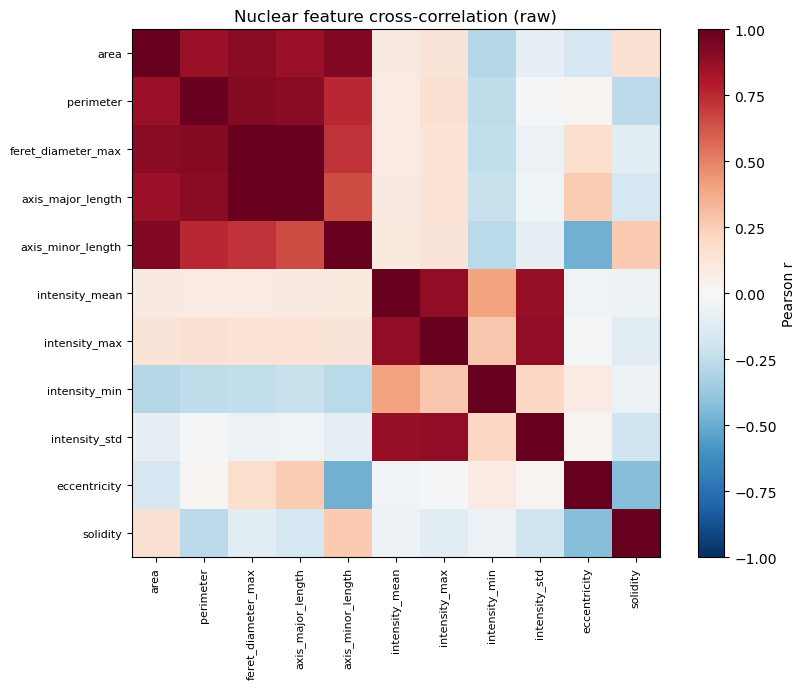

Highly correlated pairs (|r| > 0.9):
  +0.988  feret_diameter_max     axis_major_length
  +0.926  area                   axis_minor_length
  +0.918  perimeter              feret_diameter_max
  +0.905  area                   feret_diameter_max
[full] using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']
[full] dropped 0 rows with NaN/inf; 1046112 remain
[full] EVR: [0.396 0.313 0.16  0.11  0.017 0.005]
[full] cumulative: [0.396 0.709 0.869 0.978 0.995 1.   ]


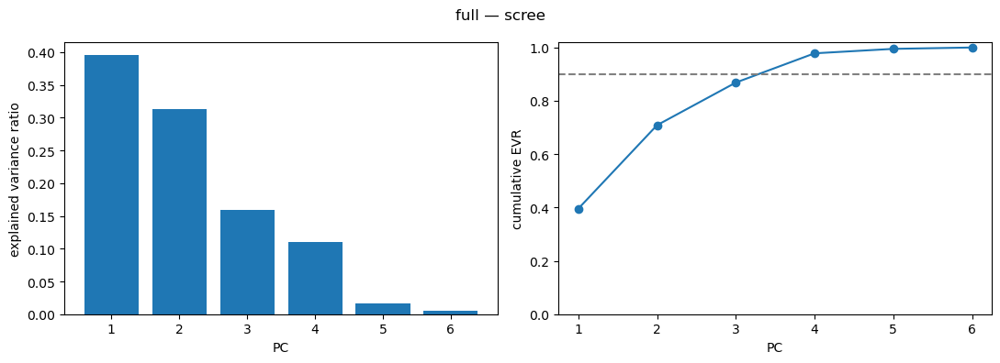

                  PC1    PC2    PC3    PC4    PC5    PC6
area            0.201  0.053  0.961 -0.139  0.119  0.015
intensity_mean -0.085  0.697  0.087  0.153 -0.690 -0.010
intensity_std  -0.167  0.683 -0.086  0.026  0.705  0.015
eccentricity   -0.593 -0.155  0.171  0.340  0.003  0.692
solidity        0.451 -0.033  0.023  0.883  0.111 -0.060
aspect_ratio    0.607  0.141 -0.179 -0.249 -0.021  0.719


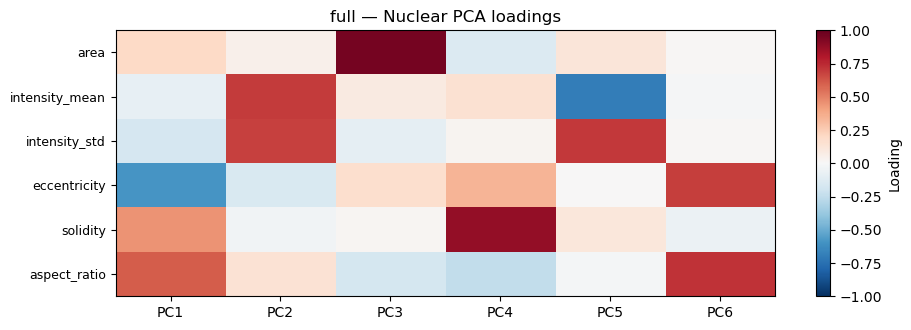

In [8]:
feature_correlation(df)
df, pca, FEATURES = fit_pca(df, label="full")

### PCA plots
Assessment of ROI level data for nucleus features

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap
import seaborn as sns
import glasbey


# ===========================================================================
# Palettes
# ===========================================================================
def make_palette(values, hue_bounds=(60, 500.0), chroma_bounds=(40, 130)):
    """Stable {value: color} mapping for a categorical column, derived from
    the data (not a hardcoded set). Sorted so colors are reproducible."""
    vals = sorted(pd.Series(values).dropna().unique())
    raw = glasbey.create_palette(palette_size=max(len(vals), 1),
                                 hue_bounds=hue_bounds, chroma_bounds=chroma_bounds)
    cmap = ListedColormap(raw)
    pal = {v: cmap(i) for i, v in enumerate(vals)}
    return pal


# high-cardinality fallback for genotype-like columns with no fixed mapping
_GENO_RAW = glasbey.create_palette(palette_size=64, hue_bounds=(0.0, 360.0),
                                   chroma_bounds=(40, 90))
GENO_COLORS = [ListedColormap(_GENO_RAW)(i) for i in range(64)]


def check_palette_coverage(data, col, palette):
    """Warn about values present in the data but missing from the palette."""
    present = set(data[col].dropna().unique())
    missing = present - set(palette)
    print(f"[warning] {col} values with no color: {sorted(missing)}" if missing
          else f"All {len(present)} {col} values have a color.")


# ===========================================================================
# Scatter: one PCA panel colored by a categorical column
# ===========================================================================
def pca_scatter(data, color_col, pcx="PC1", pcy="PC2", palette=None,
                s=2, alpha=0.15, figsize=(10, 7), legend_ncol=1,
                title=None, show_legend=True, shuffle=True, random_state=0):
    """PCA scatter colored by `color_col`.

    palette : optional {value: color} dict. If None, Gene_Var_Type uses the
              glasbey genotype colors and everything else falls back to husl.
    shuffle : plot rows in random order so no single group sits on top.
    """
    if shuffle:
        data = data.sample(frac=1, random_state=random_state).reset_index(drop=True)

    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.78)
    vals = data[color_col].astype("object")
    cats = vals.value_counts().index.tolist()

    if palette is not None:
        colors = [palette.get(c, "#808080") for c in cats]
    elif color_col == "Gene_Var_Type":
        colors = [GENO_COLORS[i % len(GENO_COLORS)] for i in range(len(cats))]
    else:
        colors = sns.color_palette("husl", n_colors=len(cats))

    for c, col in zip(cats, colors):
        m = vals == c
        ax.scatter(data.loc[m, pcx], data.loc[m, pcy], s=s, alpha=alpha,
                   color=col, linewidths=0, rasterized=True)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)
    ax.set_title(title or f"PCA of {color_col}", pad=10)
    if show_legend:
        handles = [Line2D([0], [0], marker="o", linestyle="", markersize=5,
                   markerfacecolor=col, markeredgecolor=col, label=str(c))
                   for c, col in zip(cats, colors)]
        ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
                  frameon=False, fontsize=7, ncol=legend_ncol,
                  borderaxespad=0.0, handletextpad=0.4, columnspacing=0.8)
    plt.show()
    return ax


# ===========================================================================
# Centroid overlay: per-group centroids over a faint background cloud
# ===========================================================================
def centroid_overlay(data, color_col, group_keys, pcx="PC1", pcy="PC2",
                     palette=None, stat="median", bg_frac=1.0, s_centroid=60,
                     figsize=(10, 7), legend_ncol=1, title=None,
                     bg_s=1, bg_alpha=0.03):
    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.78)
    bg = data.sample(frac=bg_frac, random_state=0) if bg_frac < 1.0 else data
    ax.scatter(bg[pcx], bg[pcy], s=bg_s, alpha=bg_alpha, color="lightgray",
               linewidths=0, rasterized=True)
    agg_spec = {pcx: stat, pcy: stat}
    if color_col not in group_keys:
        agg_spec[color_col] = "first"
    cent = data.groupby(group_keys).agg(agg_spec).reset_index()
    vals = cent[color_col].astype("object")
    cats = vals.value_counts().index.tolist()
    colors = ([palette.get(c, "#808080") for c in cats] if palette
              else sns.color_palette("husl", n_colors=len(cats)))
    for c, col in zip(cats, colors):
        m = vals == c
        ax.scatter(cent.loc[m, pcx], cent.loc[m, pcy], s=s_centroid, color=col,
                   edgecolor="k", linewidths=0.5, alpha=0.9)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)
    ax.set_title(title or f"Per-group {stat} centroids ({color_col})", pad=10)
    handles = [Line2D([0], [0], marker="o", linestyle="", markersize=6,
               markerfacecolor=col, markeredgecolor="k", label=str(c))
               for c, col in zip(cats, colors)]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
              frameon=False, fontsize=7, ncol=legend_ncol)
    plt.show()
    return cent


# ===========================================================================
# Convenience: a standard panel set for one scored frame
# ===========================================================================
def scatter_panels(data, specs, label="Nuclei", s=2, alpha=0.15, figsize=(12, 7)):
    """Run pca_scatter for several columns in one call.

    specs : list of (column, palette_or_None). Pass a palette dict for columns
            you want stable colors on (plate, batch); None lets the function
            pick (glasbey for Gene_Var_Type, husl otherwise).
    """
    for col, pal in specs:
        pca_scatter(data, col, palette=pal, s=s, alpha=alpha, figsize=figsize,
                    legend_ncol=2 if col in ("Gene_Var_Type", "Genotype_Name") else 1,
                    title=f"{label} — {col}")


# --- usage -----------------------------------------------------------------
# build palettes once from whatever frame you're plotting:
# plate_pal = make_palette(df["iNDI_Plate_ID"])
# batch_pal = make_palette(df["Batch"])
# check_palette_coverage(df, "iNDI_Plate_ID", plate_pal)
#
# # single calls, anywhere later in the script -- no global dependencies:
# pca_scatter(df, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7),
#             title="Nuclei — iNDI_Plate_ID")
# pca_scatter(df, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2,
#             title="Nuclei — Gene_Var_Type")
#
# # or the whole standard set at once:
# scatter_panels(df, [
#     ("iNDI_Plate_ID", plate_pal),
#     ("Source",        None),
#     ("Batch",         batch_pal),
#     ("Asp PosID",     None),
#     ("Gene_Var_Type", None),
# ])
#
# centroid_overlay(df, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal,
#                  figsize=(12, 7), title="Per-experiment medians (by plate)")
# cent = df.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
# print("Std of per-experiment centroids (batch magnitude):")
# print(cent.std().round(3))

All 21 iNDI_Plate_ID values have a color.


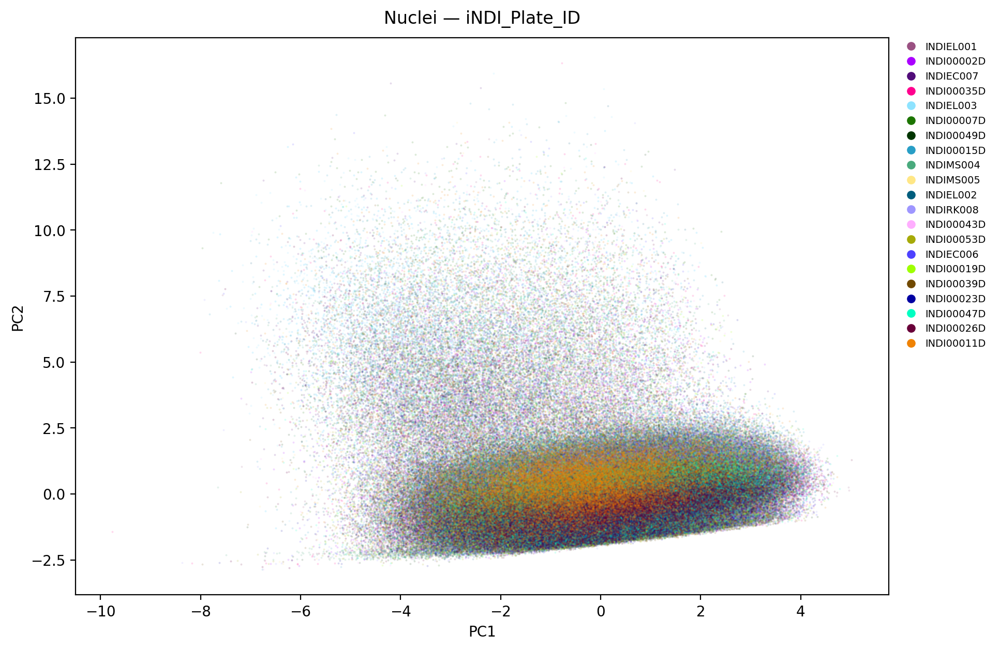

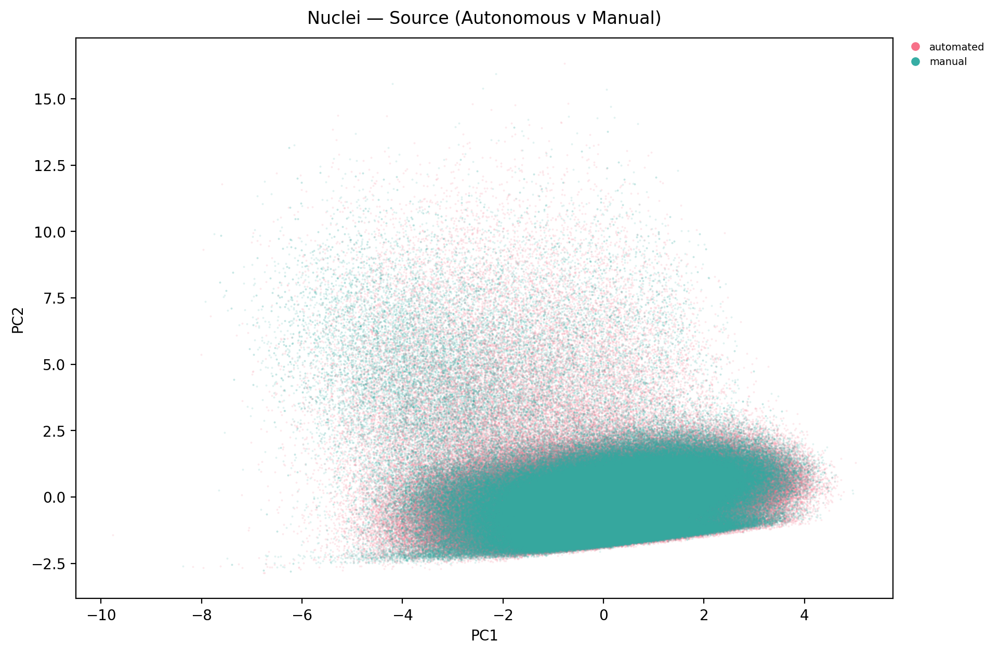

All 5 Batch values have a color.


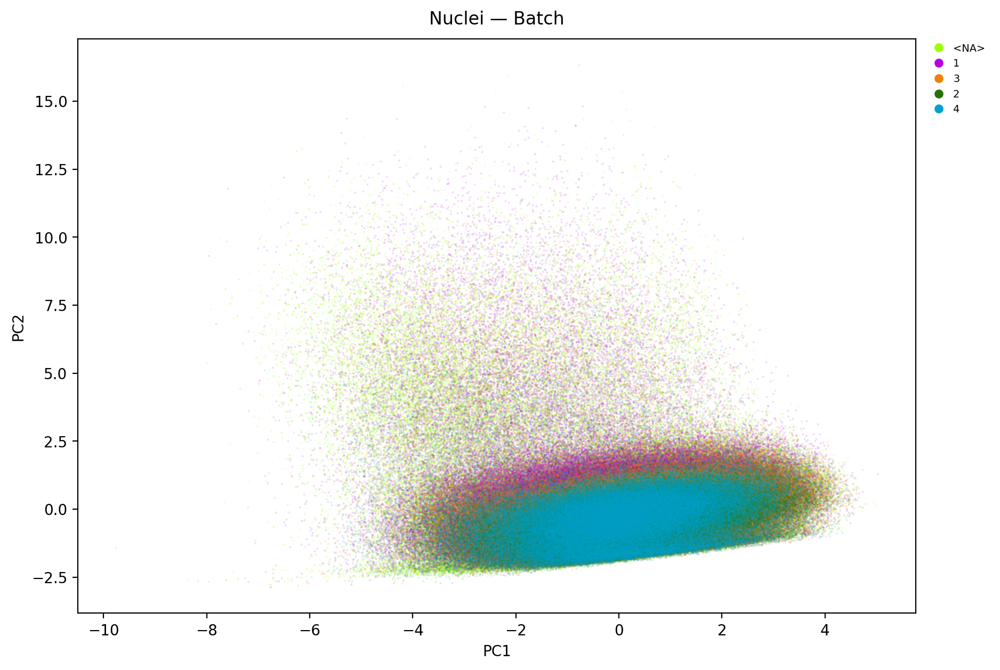

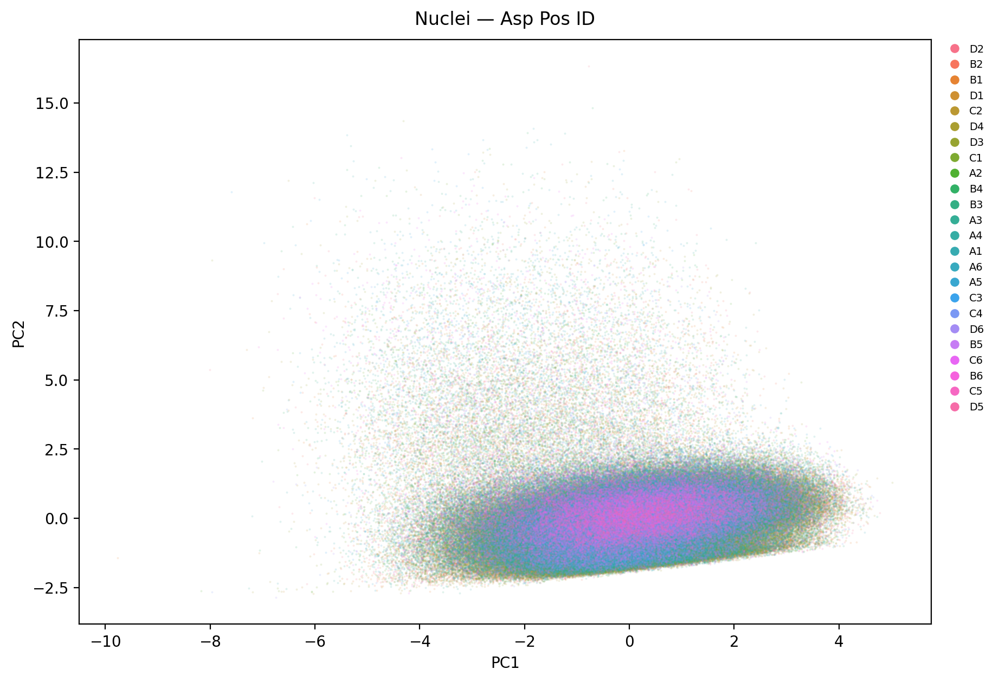

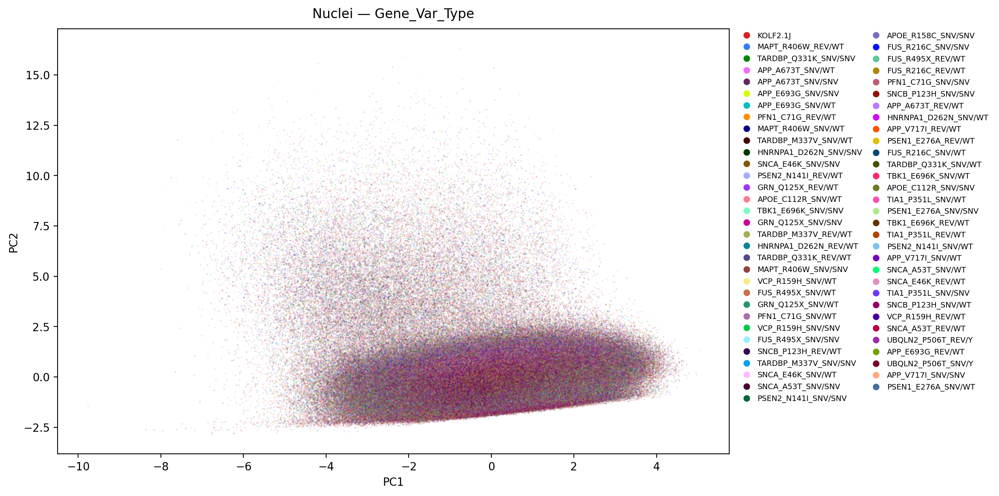

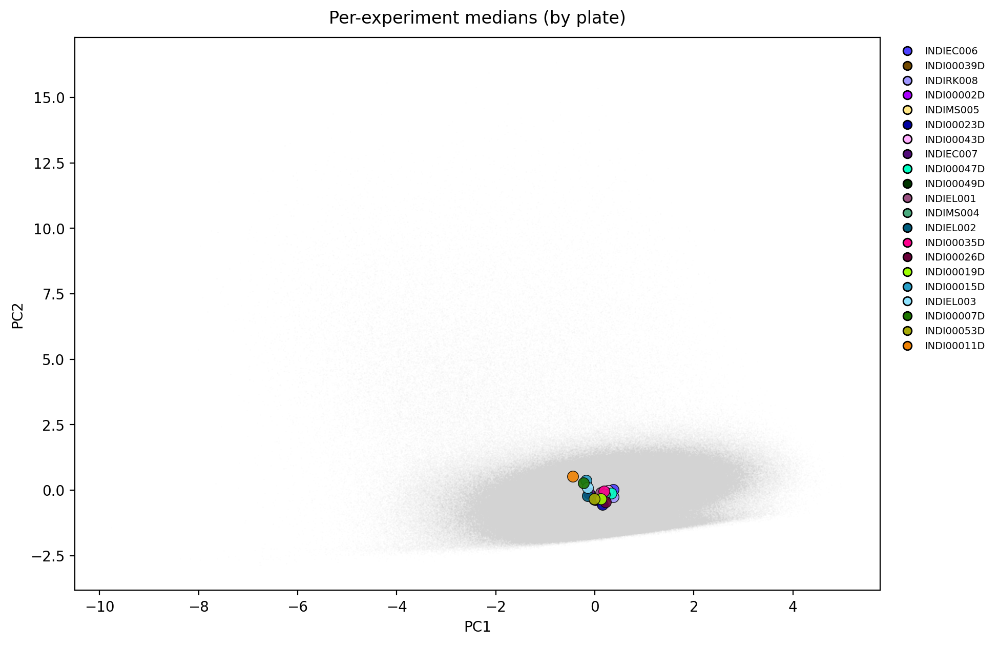

Std of per-experiment centroids (batch magnitude):
PC1    0.218
PC2    0.272
PC3    0.207
dtype: float64


In [10]:
plate_pal = make_palette(df["iNDI_Plate_ID"])
check_palette_coverage(df, "iNDI_Plate_ID", plate_pal)
pca_scatter(df, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Nuclei — iNDI_Plate_ID")

pca_scatter(df, "Source", figsize=(12, 7),title="Nuclei — Source (Autonomous v Manual)")

batch_palette = make_palette(df["Batch"])
check_palette_coverage(df, "Batch", batch_palette)
pca_scatter(df, "Batch", palette=batch_palette, figsize=(12, 7),title="Nuclei — Batch")

pca_scatter(df, "Asp PosID", figsize=(12, 7),title="Nuclei — Asp Pos ID")

pca_scatter(df, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2, title="Nuclei — Gene_Var_Type")

centroid_overlay(df, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate)")
cent = df.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

### Variance-component analysis

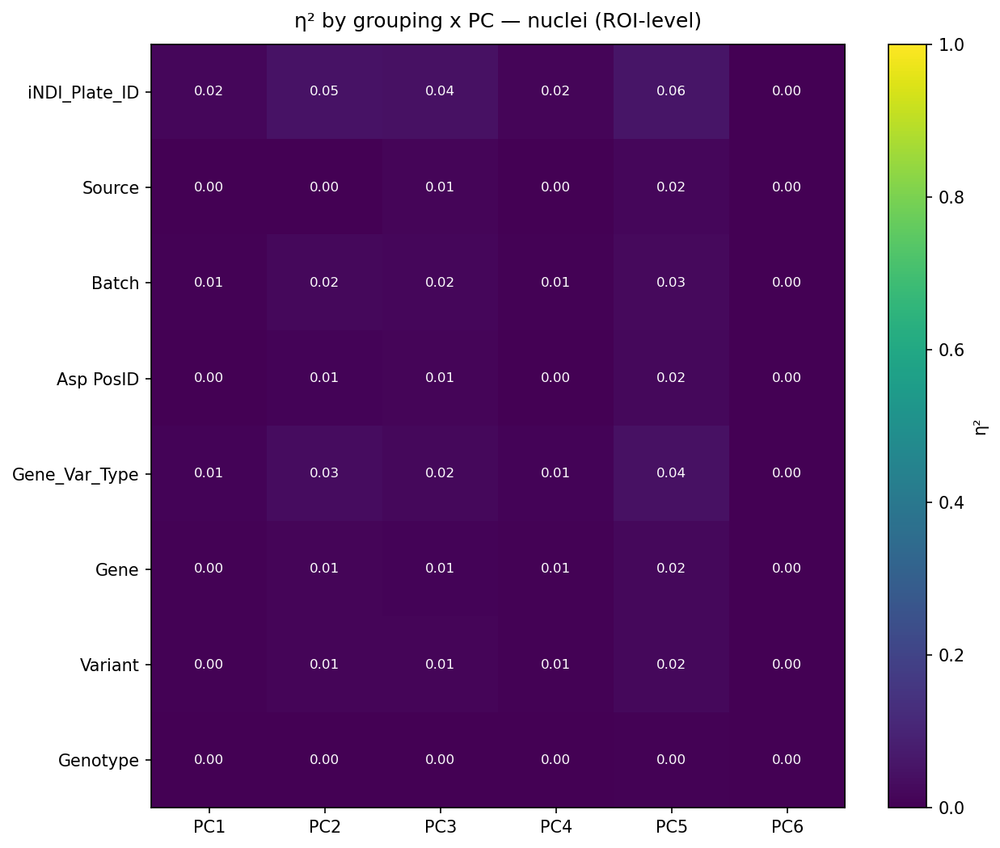

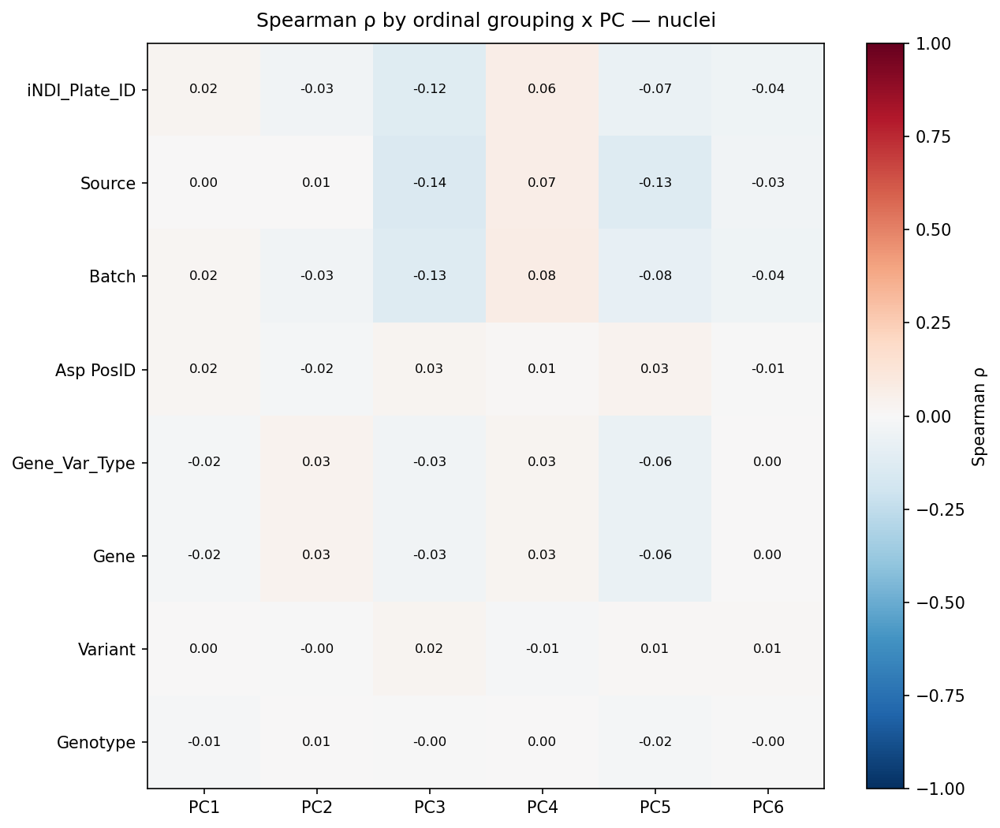

In [11]:
def eta_squared(values, groups):
    values = np.asarray(values, dtype=float)
    mask = np.isfinite(values)
    values, groups = values[mask], np.asarray(groups)[mask]
    if values.size == 0:
        return np.nan
    grand = values.mean()
    ss_total = ((values - grand) ** 2).sum()
    ss_between = 0.0
    for g in pd.unique(groups):
        v = values[groups == g]
        if v.size == 0:            # guard: skip empty groups
            continue
        ss_between += len(v) * (v.mean() - grand) ** 2
    return ss_between / ss_total if ss_total > 0 else np.nan


def eta_heatmap(data, group_cols, n_pcs=None, title="η² by grouping x PC", annot=True):
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))
    if n_pcs is not None:
        pc_cols = pc_cols[:n_pcs]
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)
    for gc in group_cols:
        groups = data[gc].to_numpy()
        for pc in pc_cols:
            mat.loc[gc, pc] = eta_squared(data[pc].to_numpy(), groups)
    fig, ax = plt.subplots(figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(group_cols) + 1.5), dpi=150)
    im = ax.imshow(mat.values.astype(float), cmap="viridis", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(group_cols))); ax.set_yticklabels(group_cols)
    plt.colorbar(im, ax=ax, label="η²")
    ax.set_title(title, pad=10)
    if annot:
        for i in range(len(group_cols)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if v < 0.6 else "black", fontsize=8)
    plt.tight_layout(); plt.show()
    return mat

# Structure dropped (single channel). Batch drivers that matter for nuclei:
GROUP_COLS = ["iNDI_Plate_ID", "Source", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"]
eta_full = eta_heatmap(df, GROUP_COLS, n_pcs=10, title="η² by grouping x PC — nuclei (ROI-level)")

from scipy.stats import spearmanr

def spearman_heatmap(data, group_cols, n_pcs=None,
                     title="Spearman ρ by grouping x PC", annot=True):
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))
    if n_pcs is not None:
        pc_cols = pc_cols[:n_pcs]
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)

    for gc in group_cols:
        # ordinal code: use numeric directly if numeric, else factorize
        col = data[gc]
        if pd.api.types.is_numeric_dtype(col):
            codes = col.to_numpy(dtype=float)
        else:
            codes = pd.factorize(col, sort=True)[0].astype(float)
            codes[codes < 0] = np.nan  # NaNs come back as -1
        for pc in pc_cols:
            x = data[pc].to_numpy(dtype=float)
            m = np.isfinite(x) & np.isfinite(codes)
            if m.sum() < 3:
                mat.loc[gc, pc] = np.nan
                continue
            rho, _ = spearmanr(x[m], codes[m])
            mat.loc[gc, pc] = rho

    fig, ax = plt.subplots(
        figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(group_cols) + 1.5), dpi=150)
    # diverging map + symmetric limits since ρ ∈ [-1, 1]
    im = ax.imshow(mat.values.astype(float), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(group_cols))); ax.set_yticklabels(group_cols)
    plt.colorbar(im, ax=ax, label="Spearman ρ")
    ax.set_title(title, pad=10)
    if annot:
        for i in range(len(group_cols)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if abs(v) > 0.5 else "black", fontsize=8)
    plt.tight_layout(); plt.show()
    return mat

ORDINAL_COLS = ["iNDI_Plate_ID", "Source", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"]
spear = spearman_heatmap(df, ORDINAL_COLS, n_pcs=10,
                         title="Spearman ρ by ordinal grouping x PC — nuclei")

[facet] 16 genes; 236718 total KOLF2.1J rows (all folded into each facet)
  APOE: 38764 variant + 236718 KOLF rows


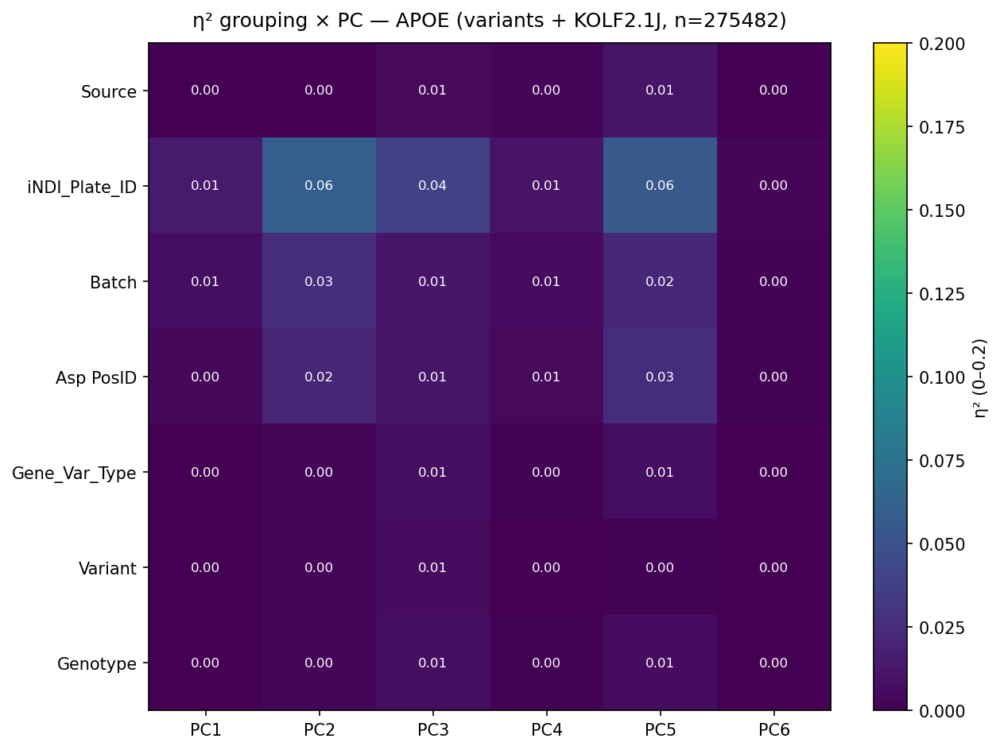

  APP: 119844 variant + 236718 KOLF rows


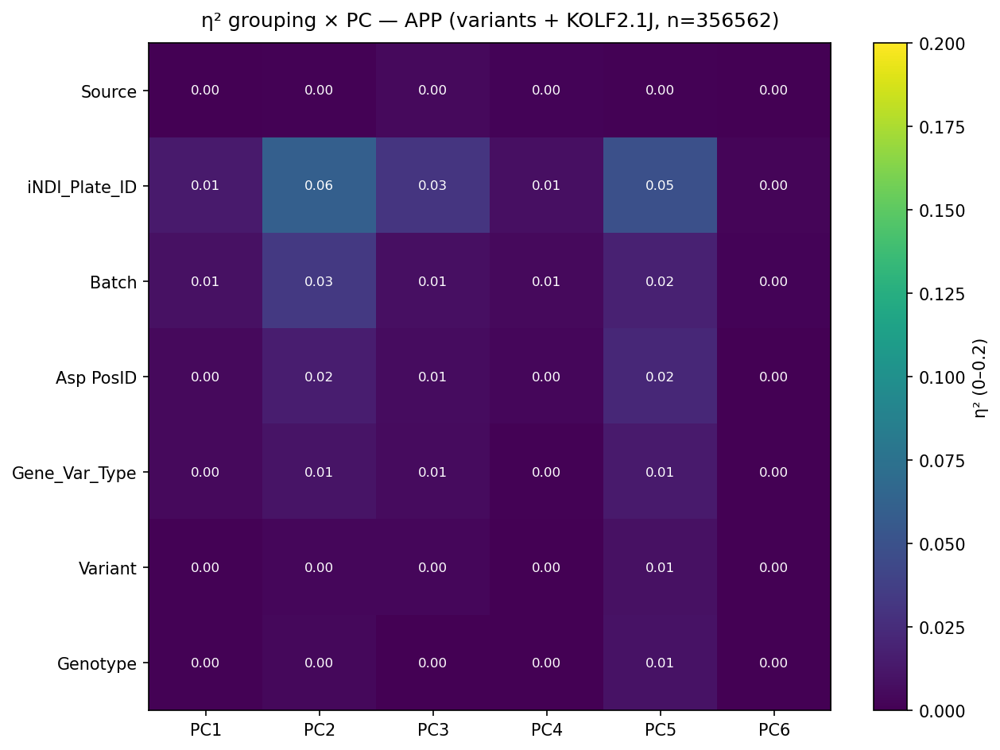

  FUS: 75312 variant + 236718 KOLF rows


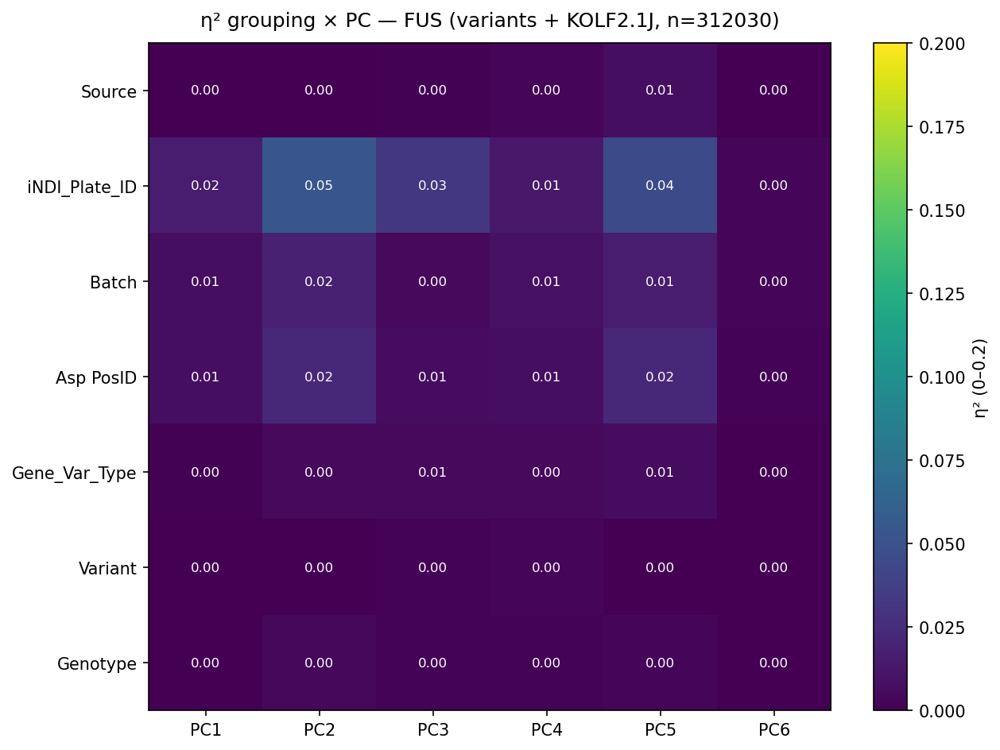

  GRN: 47400 variant + 236718 KOLF rows


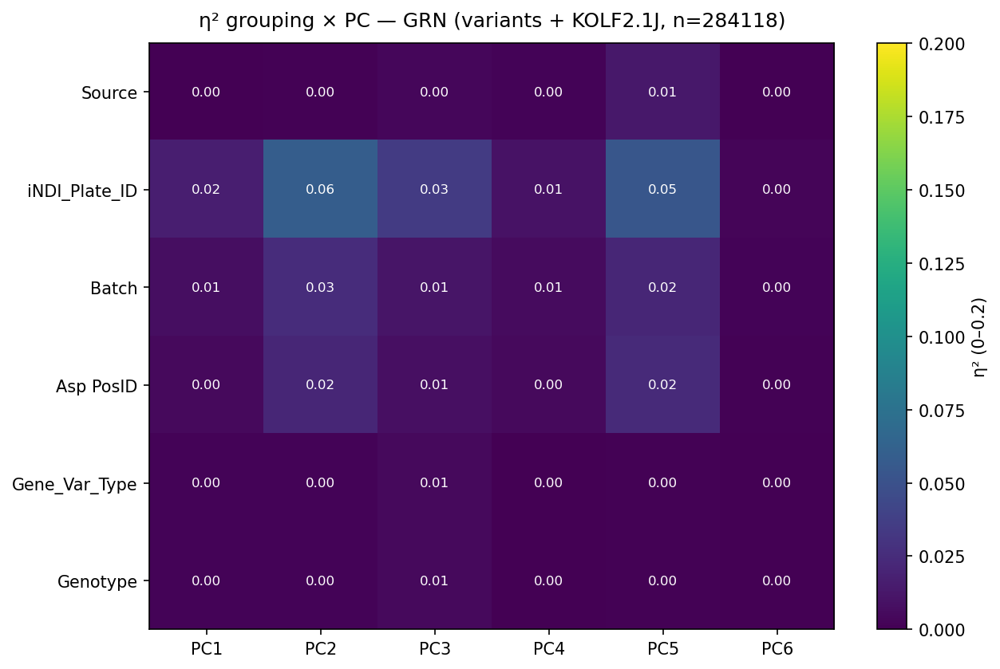

  HNRNPA1: 44838 variant + 236718 KOLF rows


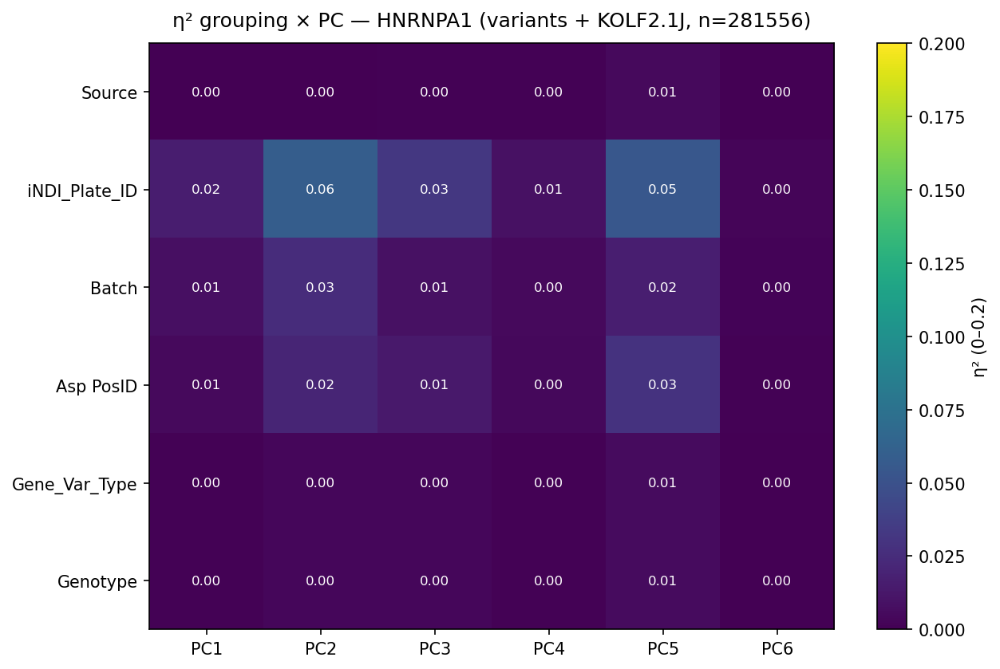

  MAPT: 59889 variant + 236718 KOLF rows


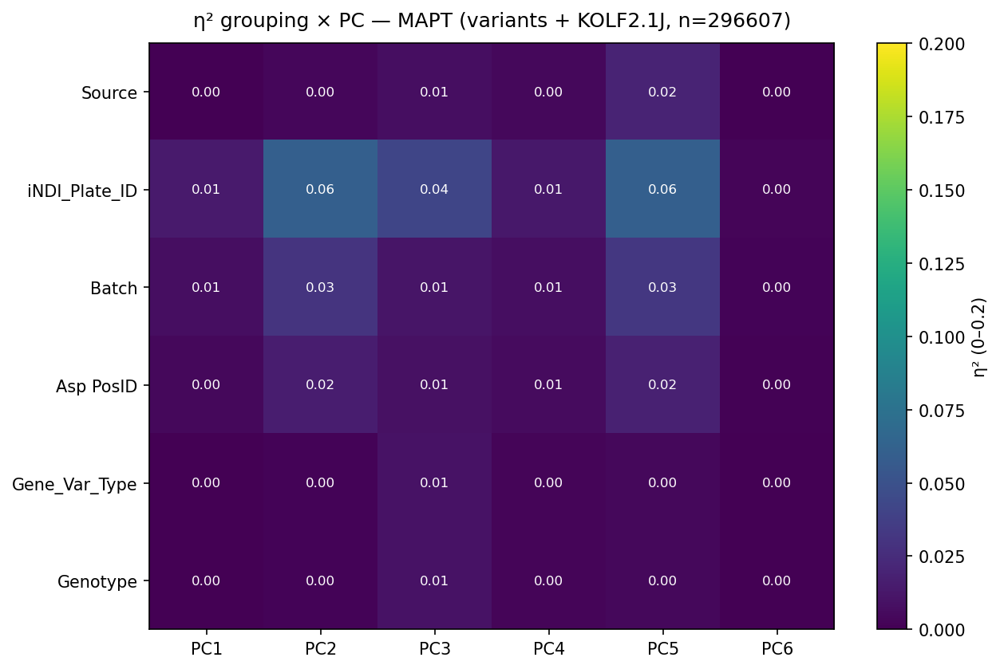

  PFN1: 44491 variant + 236718 KOLF rows


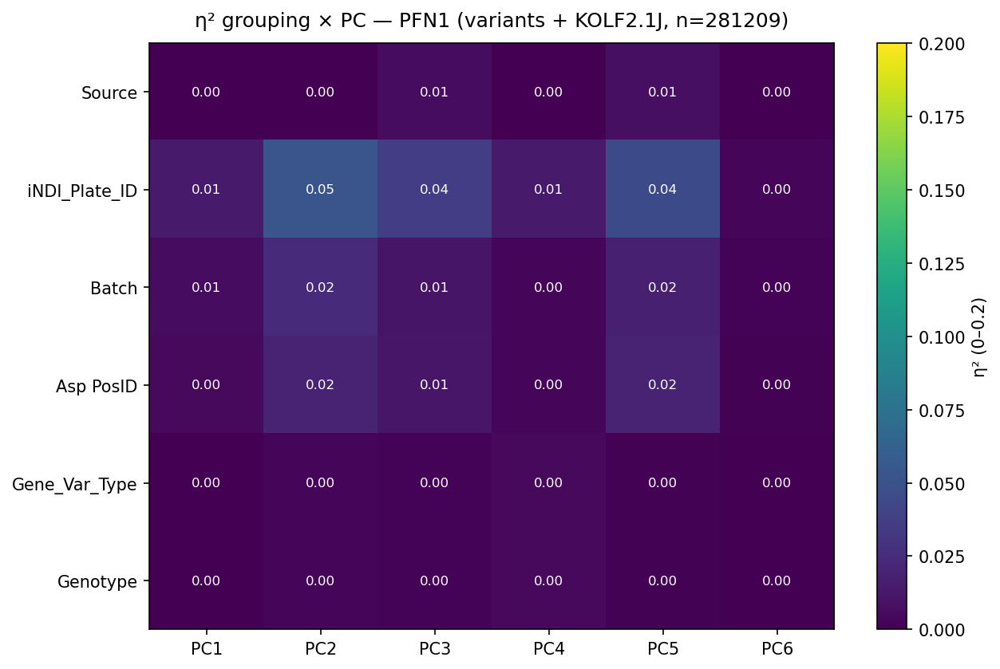

  PSEN1: 20655 variant + 236718 KOLF rows


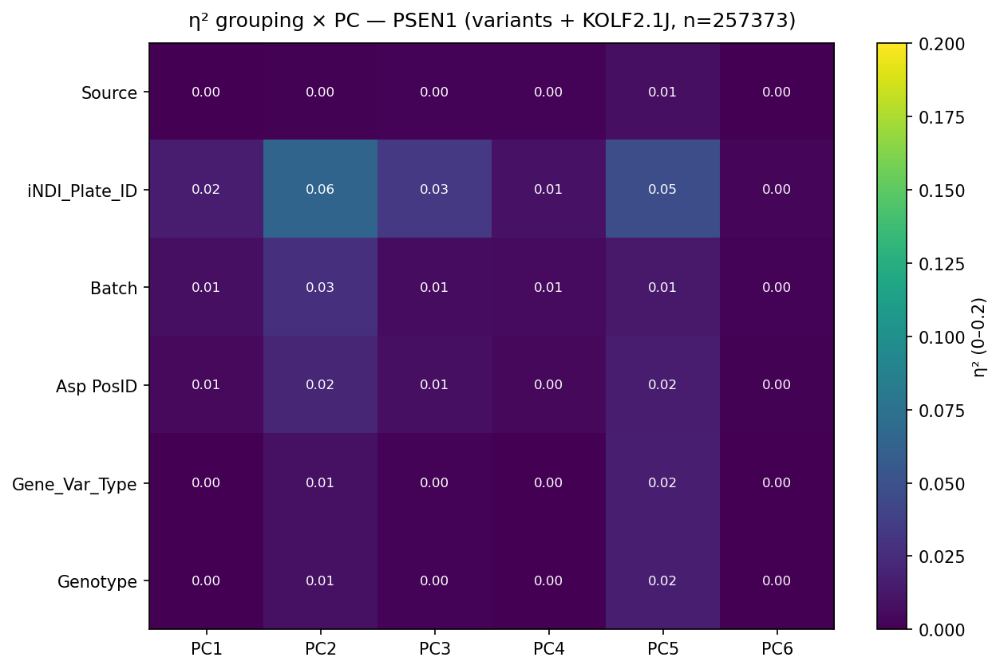

  PSEN2: 38982 variant + 236718 KOLF rows


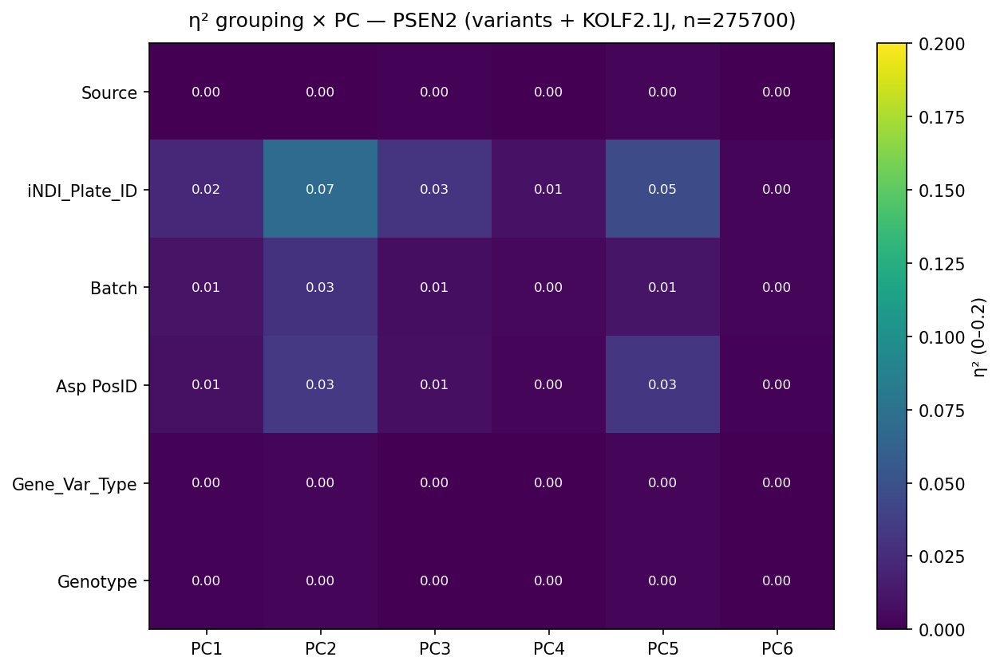

  SNCA: 68031 variant + 236718 KOLF rows


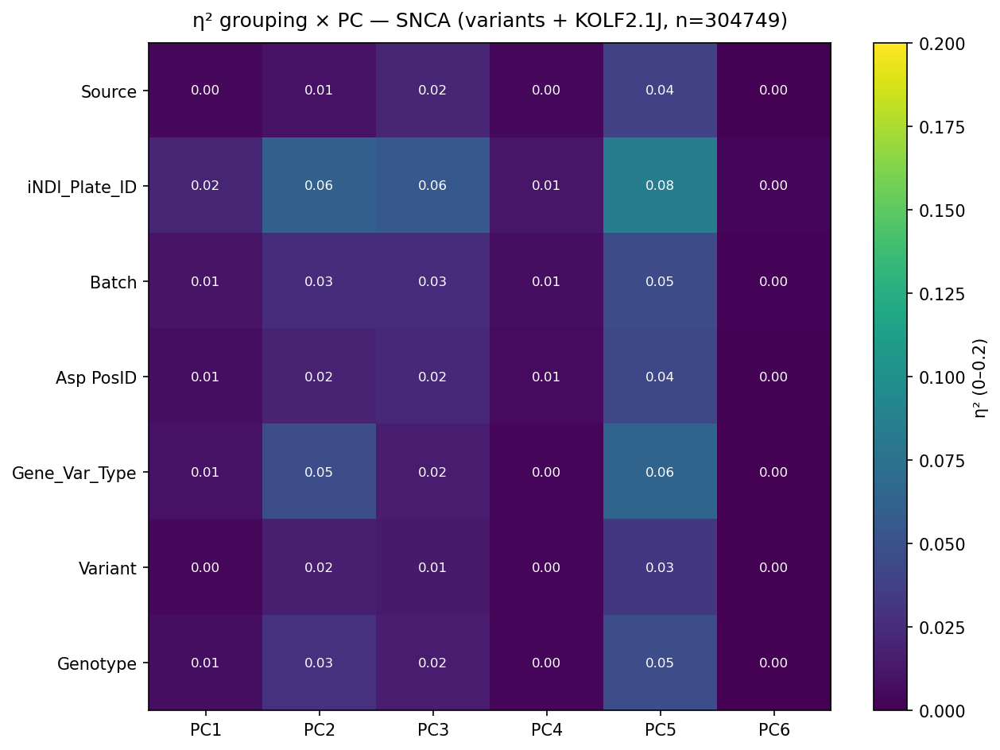

  SNCB: 32536 variant + 236718 KOLF rows


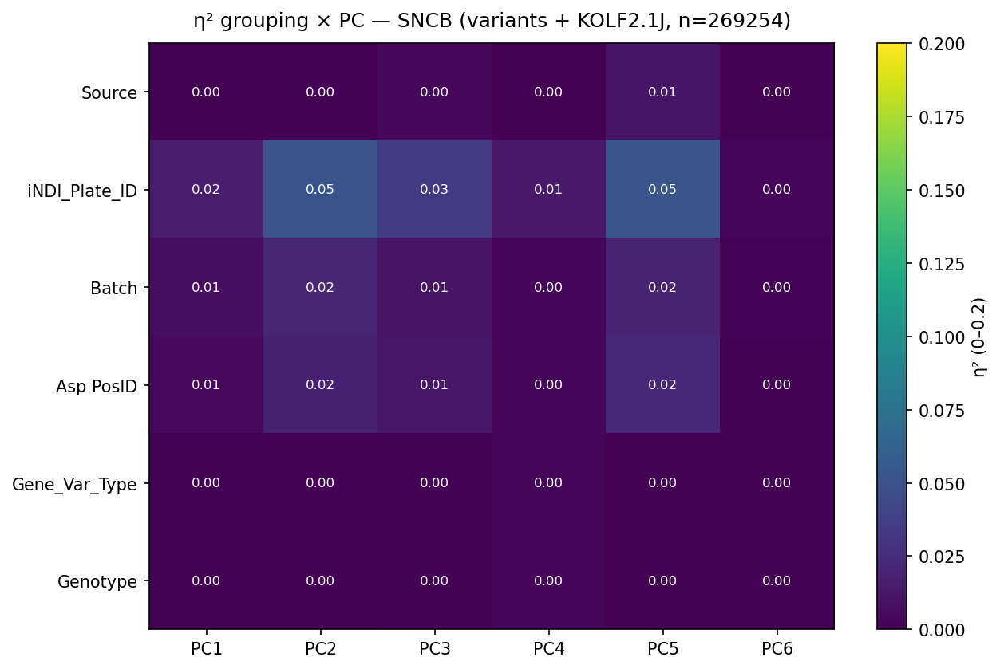

  TARDBP: 98484 variant + 236718 KOLF rows


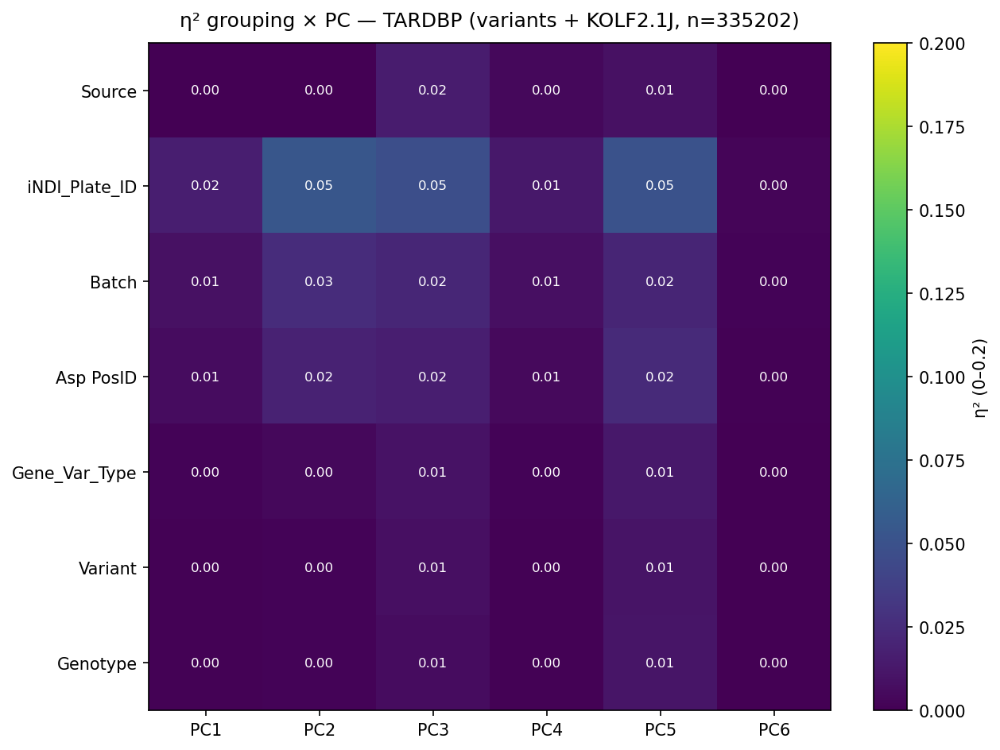

  TBK1: 35178 variant + 236718 KOLF rows


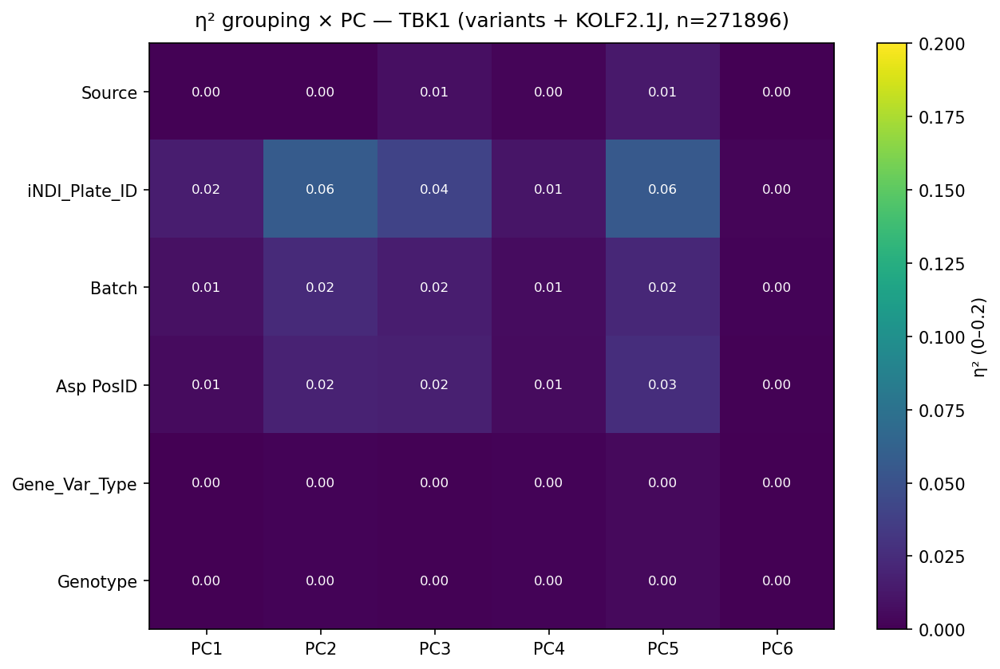

  TIA1: 26072 variant + 236718 KOLF rows


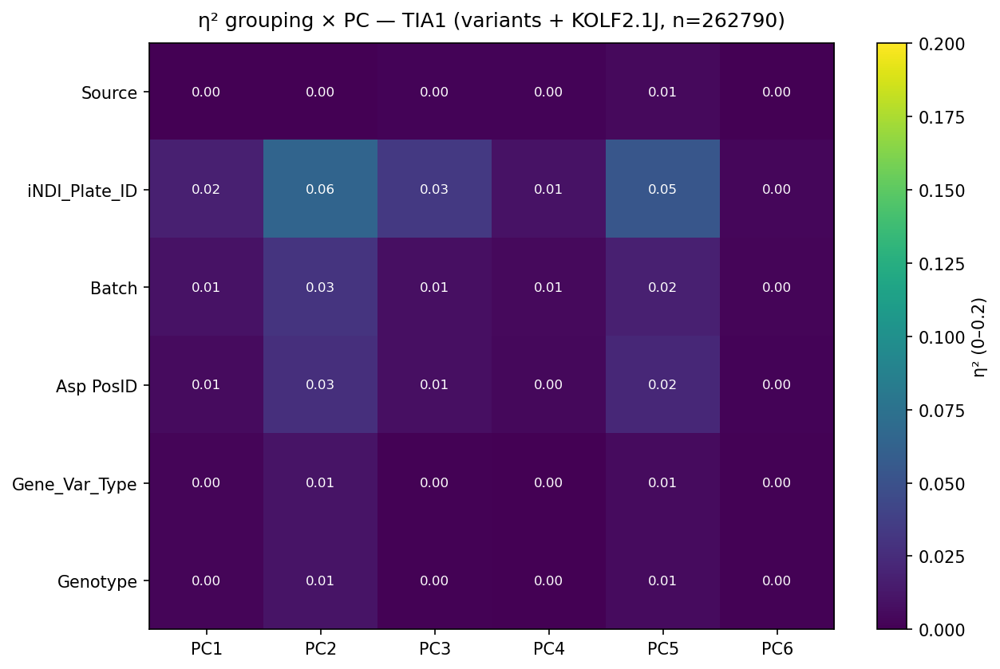

  UBQLN2: 13924 variant + 236718 KOLF rows


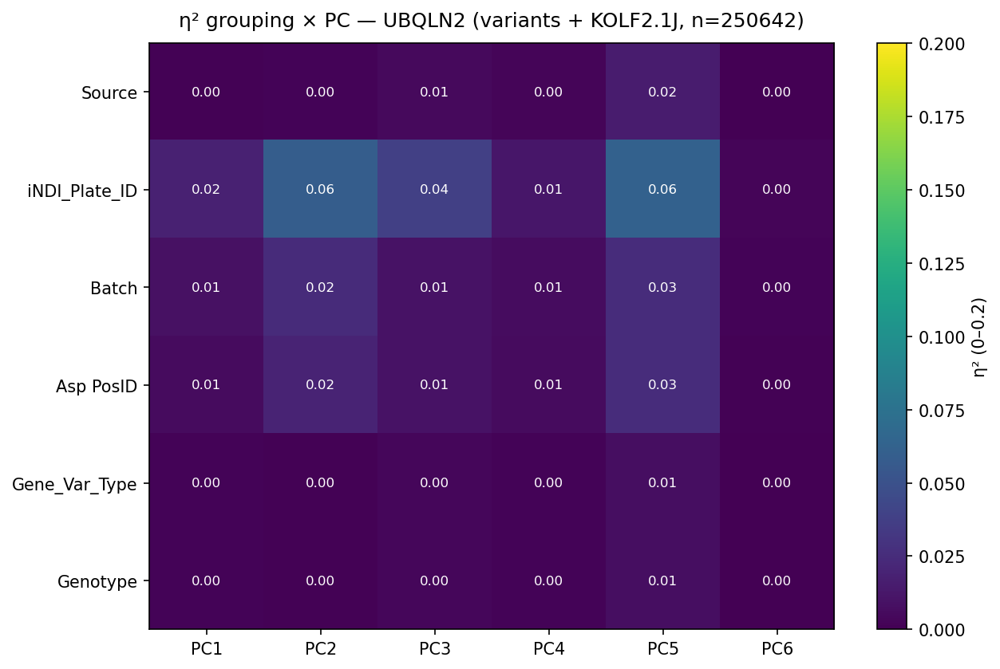

  VCP: 36700 variant + 236718 KOLF rows


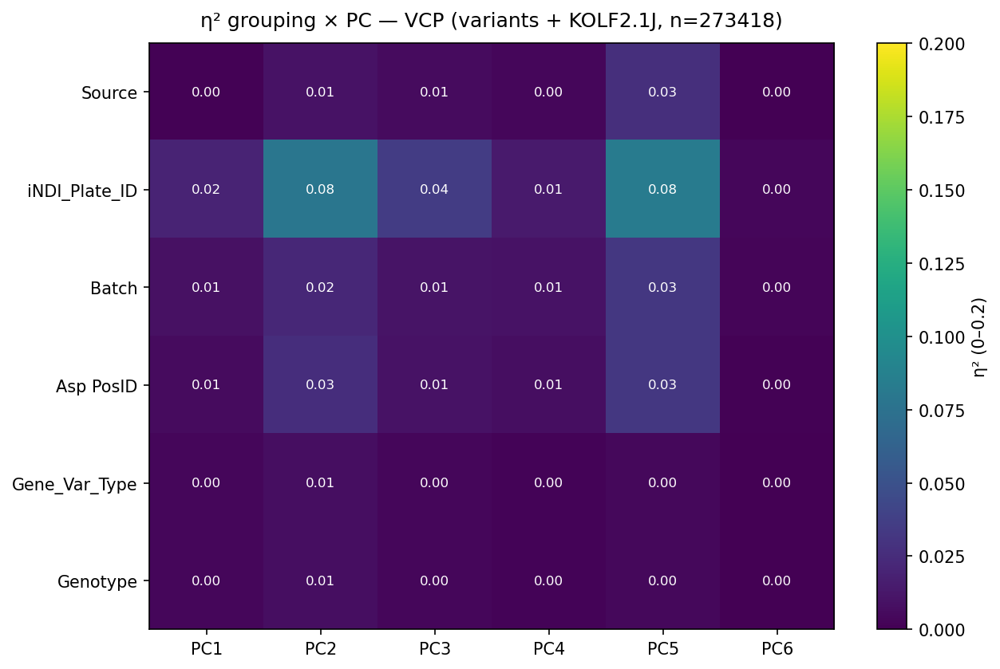

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- your original eta_squared, unchanged ----------------------------------
def eta_squared(values, groups):
    values = np.asarray(values, dtype=float)
    mask = np.isfinite(values)
    values, groups = values[mask], np.asarray(groups)[mask]
    if values.size == 0:
        return np.nan
    grand = values.mean()
    ss_total = ((values - grand) ** 2).sum()
    ss_between = 0.0
    for g in pd.unique(groups):
        v = values[groups == g]
        if v.size == 0:
            continue
        ss_between += len(v) * (v.mean() - grand) ** 2
    return ss_between / ss_total if ss_total > 0 else np.nan


# --- optional well-level aggregation (strongly recommended) ----------------
# A per-gene variant effect on a mean is invisible at single-nucleus level.
# Collapse ROI rows to one row per well before faceting.
def aggregate_to_wells(data, well_keys, carry_cols, pc_cols):
    agg = {pc: "median" for pc in pc_cols}
    for c in carry_cols:
        agg[c] = "first"
    return data.groupby(list(well_keys), as_index=False).agg(agg)


# --- shared WT/control predicate -------------------------------------------
def is_wt(data, gene_col="Gene"):
    """True for the shared KOLF2.1J parental-control rows (they live in Gene)."""
    return data[gene_col].astype(str).str.strip() == "KOLF2.1J"


# --- the original single-matrix eta computation, as a reusable helper -------
def eta_matrix(data, group_cols, pc_cols):
    """grouping x PC matrix of η² for one data subset (e.g. one gene facet)."""
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)
    for gc in group_cols:
        groups = data[gc].to_numpy()
        for pc in pc_cols:
            mat.loc[gc, pc] = eta_squared(data[pc].to_numpy(), groups)
    return mat


# --- per-gene: ONE SEPARATE FIGURE per gene --------------------------------
def plot_gene_heatmap(sub, group_cols, pc_cols, gene, vmax=0.2, annot=True,
                      drop_constant=True):
    """Draw a single grouping x PC η² heatmap for one gene's subset."""
    rows = list(group_cols)
    if drop_constant:  # hide grouping rows with <2 levels in this facet
        rows = [g for g in rows if g in sub.columns and sub[g].nunique() > 1]
    mat = eta_matrix(sub, rows, pc_cols)

    fig, ax = plt.subplots(
        figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(mat.index) + 1.5), dpi=150)
    im = ax.imshow(mat.values.astype(float), cmap="viridis",
                   vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(mat.index))); ax.set_yticklabels(mat.index)
    plt.colorbar(im, ax=ax, label=f"η² (0–{vmax})")
    ax.set_title(f"η² grouping × PC — {gene} (variants + KOLF2.1J, n={len(sub)})",
                 pad=10)
    if annot:
        for i in range(len(mat.index)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if v < 0.6 * vmax else "black",
                            fontsize=8)
    plt.tight_layout(); plt.show()
    return mat


def facet_by_gene(data, group_cols, n_pcs=10,
                  gene_col="Gene", vmax=0.2, annot=True,
                  include_wt=True, drop_constant=True,
                  plate_match=False, plate_col="iNDI_Plate_ID"):
    """One separate η² heatmap figure per gene. Each gene's subset is that
    gene's variant rows plus the shared KOLF2.1J control rows.

    plate_match=True restricts the KOLF2.1J rows folded into each facet to the
    plates that gene's variants actually occupy, removing the plate confound
    that arises when controls span all plates but a gene sits on only a few.
    """
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))[:n_pcs]

    wt_mask = is_wt(data, gene_col)
    wt_rows = data[wt_mask]
    edited = data[~wt_mask]
    genes = sorted(pd.unique(edited[gene_col].dropna()))
    print(f"[facet] {len(genes)} genes; {len(wt_rows)} total KOLF2.1J rows "
          f"{'(plate-matched per facet)' if plate_match else '(all folded into each facet)'}")

    facet_groups = [g for g in group_cols if g != gene_col]

    mats = {}
    for gene in genes:
        gene_rows = edited[edited[gene_col] == gene]
        if include_wt:
            wt_use = wt_rows
            if plate_match and plate_col in data.columns:
                gene_plates = set(gene_rows[plate_col].dropna().unique())
                wt_use = wt_rows[wt_rows[plate_col].isin(gene_plates)]
            sub = pd.concat([gene_rows, wt_use], ignore_index=True)
            print(f"  {gene}: {len(gene_rows)} variant + {len(wt_use)} KOLF rows"
                  f"{f' on {len(set(gene_rows[plate_col].dropna().unique()))} plate(s)' if plate_match else ''}")
        else:
            sub = gene_rows
        mats[gene] = plot_gene_heatmap(sub, facet_groups, pc_cols, gene,
                                       vmax=vmax, annot=annot,
                                       drop_constant=drop_constant)
    return mats


# --- usage -----------------------------------------------------------------
GROUP_COLS = ["Source", "iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Variant", "Genotype"]

# recommended: aggregate to wells first (adjust well_keys to your schema)
# pc_cols = sorted([c for c in df.columns if c.startswith("PC")], key=lambda s: int(s[2:]))[:10]
# well_df = aggregate_to_wells(
#     df,
#     well_keys=["iNDI_Plate_ID", "Row", "Column"],
#     carry_cols=GROUP_COLS + ["Gene"],
#     pc_cols=pc_cols,
# )
# facet_grid_by_gene(well_df, GROUP_COLS, n_pcs=10, vmax=0.2)

# or straight on ROI-level df (noisier):
mats = facet_by_gene(df, GROUP_COLS, n_pcs=10, vmax=0.2)

## Well-level aggregation
### PCA plots

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 199828 rows (13440 images)
[full] well-level: 6352 rows
[full well] using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']
[full well] dropped 0 rows with NaN/inf; 6352 remain
[full well] EVR: [0.418 0.286 0.157 0.103 0.032 0.003]
[full well] cumulative: [0.418 0.704 0.861 0.964 0.997 1.   ]


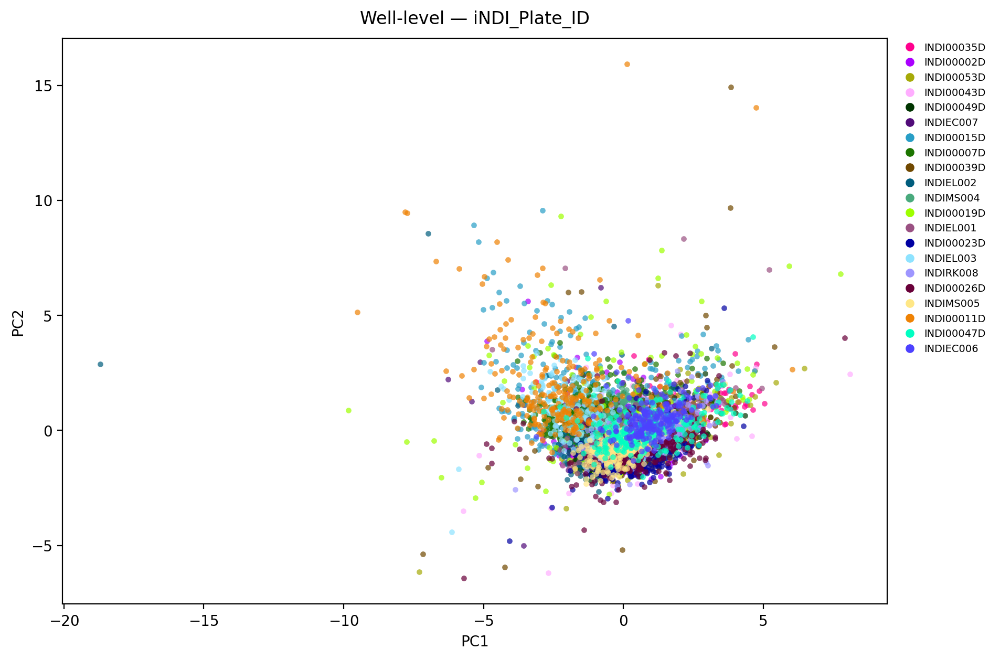

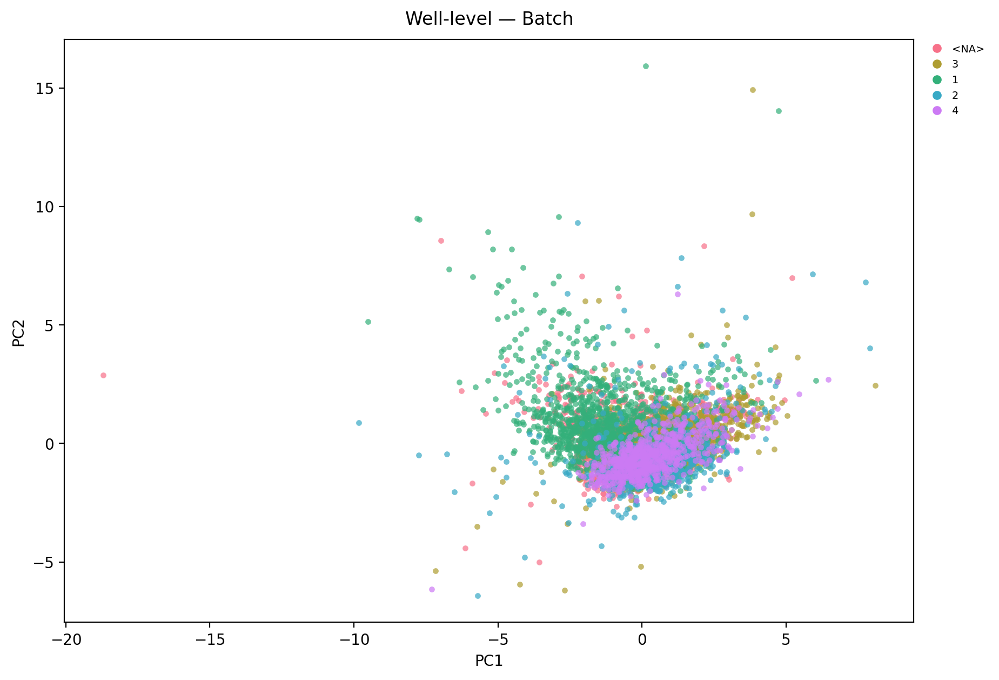

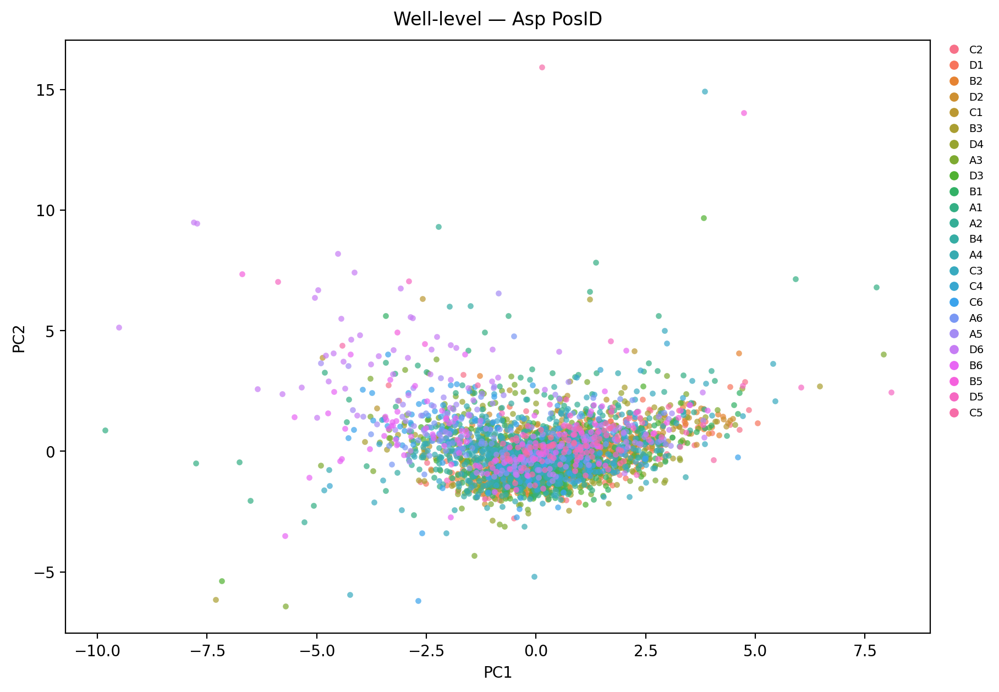

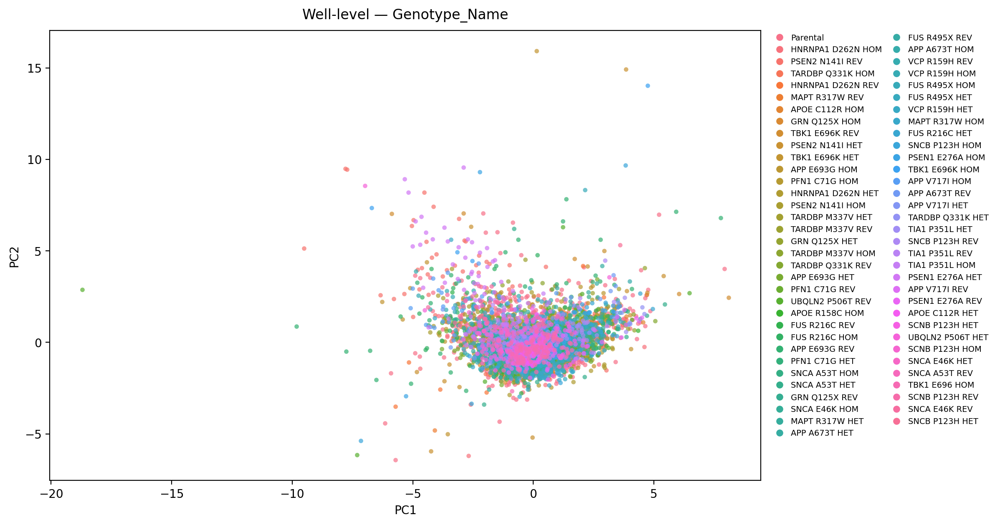

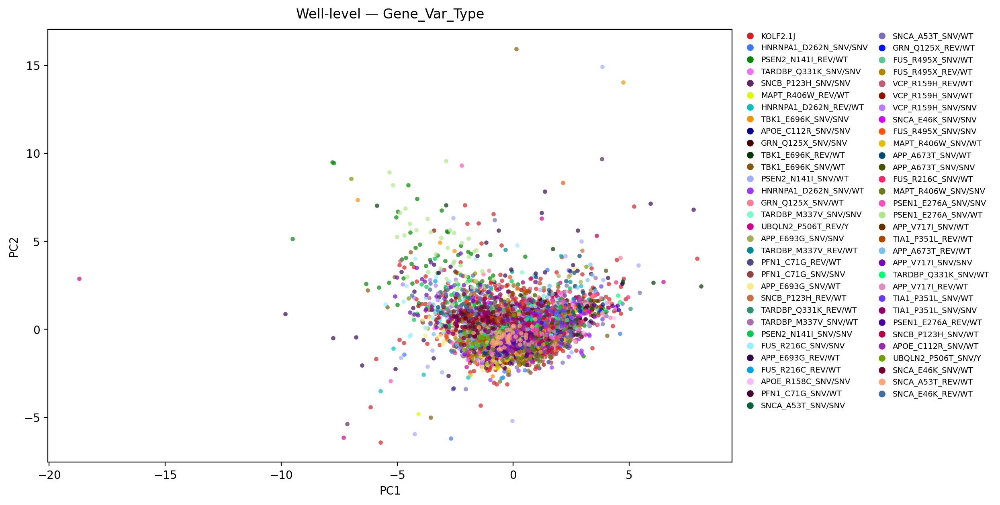

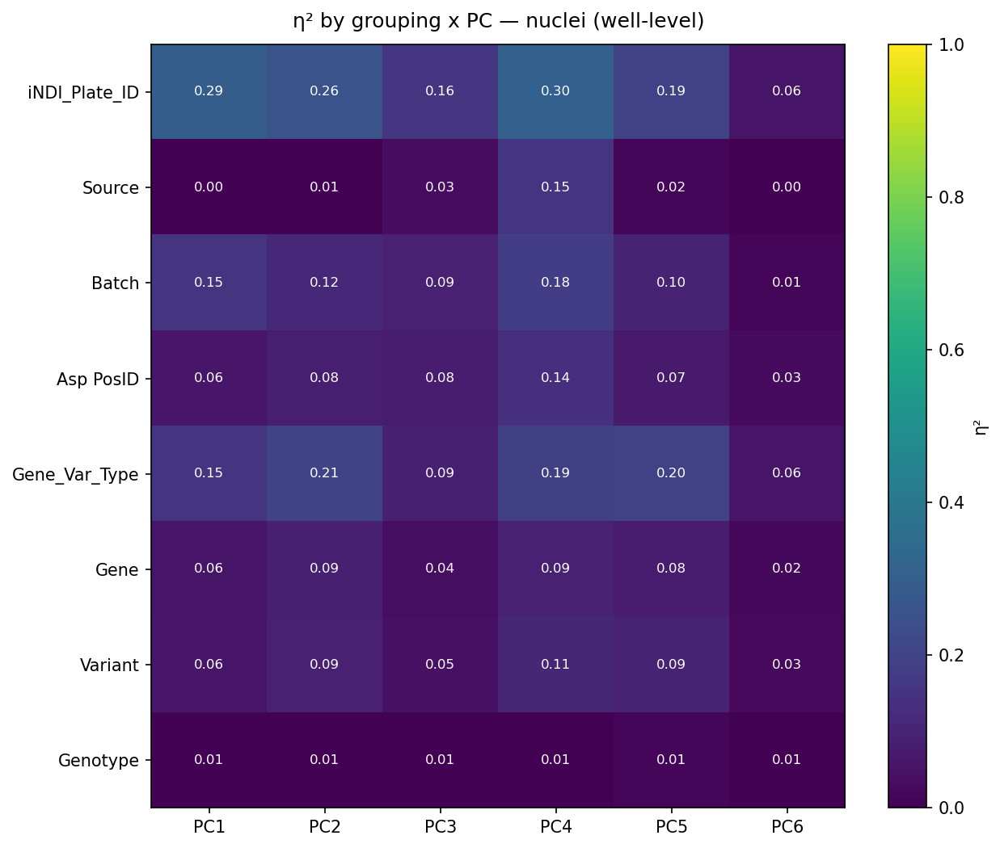

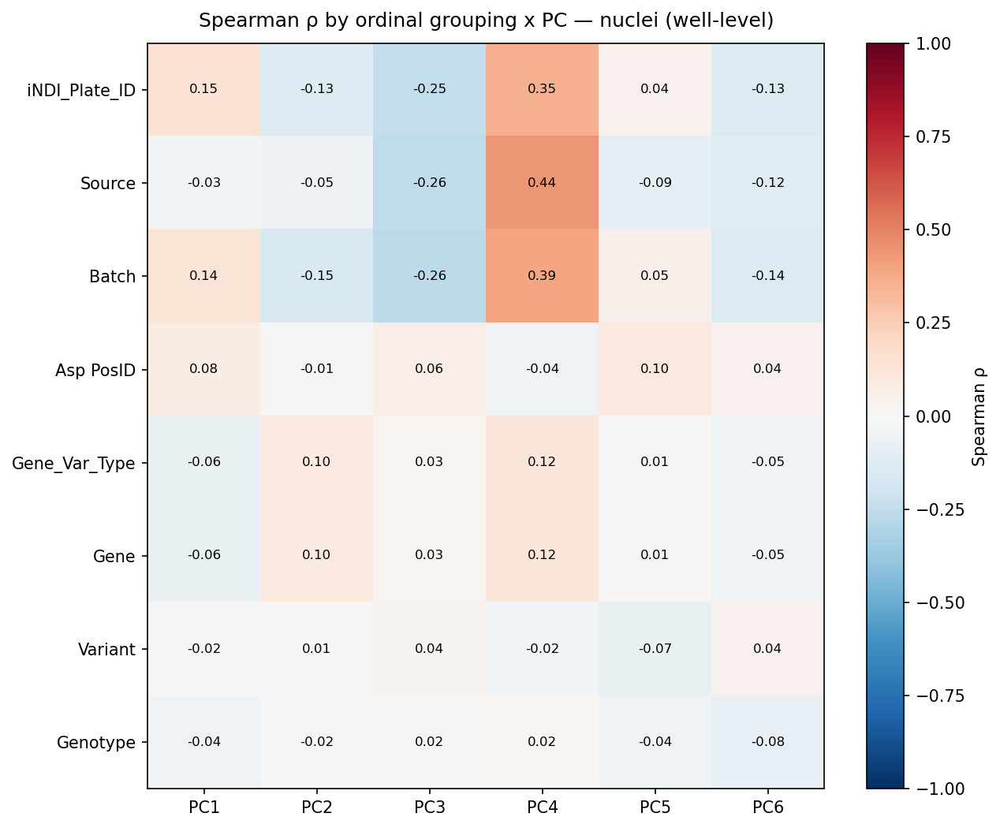

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,0.145014,-0.132569,-0.247455,0.352620,0.042928,-0.133287
Source,-0.025696,-0.052534,-0.256418,0.443152,-0.089103,-0.123187
Batch,0.136373,-0.150981,-0.260231,0.394928,0.054599,-0.135420
Asp PosID,0.077458,-0.014781,0.064620,-0.036074,0.100296,0.040208
Gene_Var_Type,-0.063965,0.099882,0.030032,0.118361,0.009356,-0.046050
Gene,-0.063039,0.099960,0.029161,0.121584,0.013948,-0.045513
Variant,-0.023334,0.008642,0.037317,-0.024240,-0.074319,0.043226
Genotype,-0.036318,-0.018097,0.015095,0.018806,-0.042398,-0.079660


In [13]:
import numpy as np
import pandas as pd

# well = Measurement_ID + subdirectory; image = image_name
WELL_KEYS = ["Measurement_ID", "subdirectory"]
IMAGE_KEY = "image_name"


def aggregate_wells(data, features, well_keys=WELL_KEYS, image_key=IMAGE_KEY,
                    check_cols=("Genotype_Name", "iNDI_Plate_ID", "prep_method"),
                    label="", image_stat="median", well_stat="mean",
                    n_pc_drop=20):
    """Collapse nuclei -> image -> well.

    stage 1: `image_stat` across nuclei within each image
    stage 2: `well_stat` across images within each well

    Metadata columns (everything that isn't a feature, PC, or key) are carried
    through with .first(), after a safety check that they're invariant within a
    well. Returns the well-level dataframe (NOT PCA-scored -- run fit_pca next).
    """
    features = [f for f in features if f in data.columns]
    group_keys = [*well_keys, image_key]
    drop_cols = (set(features) | {f"PC{i+1}" for i in range(n_pc_drop)}
                 | set(group_keys) | {"label", "filename", "filepath"})
    meta_cols = [c for c in data.columns if c not in drop_cols]

    # safety: metadata carried by .first() should be invariant within a well
    for col in check_cols:
        if col in data.columns:
            n_bad = (data.groupby(well_keys)[col].nunique() > 1).sum()
            print(f"[{label}] {col}: {n_bad} well(s) with >1 value"
                  f"{'  <-- CHECK' if n_bad else ''}")

    # stage 1: within-image summary across nuclei
    agg_image = {**{f: image_stat for f in features},
                 **{m: "first" for m in meta_cols}}
    image_level = data.groupby(group_keys, as_index=False).agg(agg_image)
    print(f"[{label}] image-level: {len(image_level)} rows "
          f"({data[image_key].nunique()} images)")

    # stage 2: within-well summary across images
    agg_well = {**{f: well_stat for f in features},
                **{m: "first" for m in meta_cols}}
    well_level = image_level.groupby(well_keys, as_index=False).agg(agg_well)
    print(f"[{label}] well-level: {len(well_level)} rows")

    return well_level


# --- usage -----------------------------------------------------------------
# aggregate, then reuse the SAME fit_pca from the feature section (don't
# re-implement the scale/PCA/score here):
#
# well_level = aggregate_wells(df, FEATURES, label="full")
# well_level, pca_well, _ = fit_pca(
#     well_level, features=FEATURES, add_aspect_ratio=False,
#     show_scree=False, show_loadings=False, label="full well",
# )


well_level = aggregate_wells(df, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)
well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_shuf["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Batch", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Batch")
pca_scatter(well_shuf, "Asp PosID", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Asp PosID")
pca_scatter(well_shuf, "Genotype_Name", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Genotype_Name")
pca_scatter(well_shuf, "Gene_Var_Type", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Gene_Var_Type")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Source", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"],
            n_pcs=6, title="η² by grouping x PC — nuclei (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Source", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — nuclei (well-level)")

### Variance-component analysis
This is built to handle all of the parental data for each genotype, but remember that this is HIGHLY unbalanced.\
"plate_match=True" will correct for this by only pulling parentals from the plates that each genotype is on, which is more accurate, but NOT a proxy for plate correction

[facet] 16 genes; 1450 total KOLF2.1J rows (all folded into each facet)
  APOE: 224 variant + 1450 KOLF rows


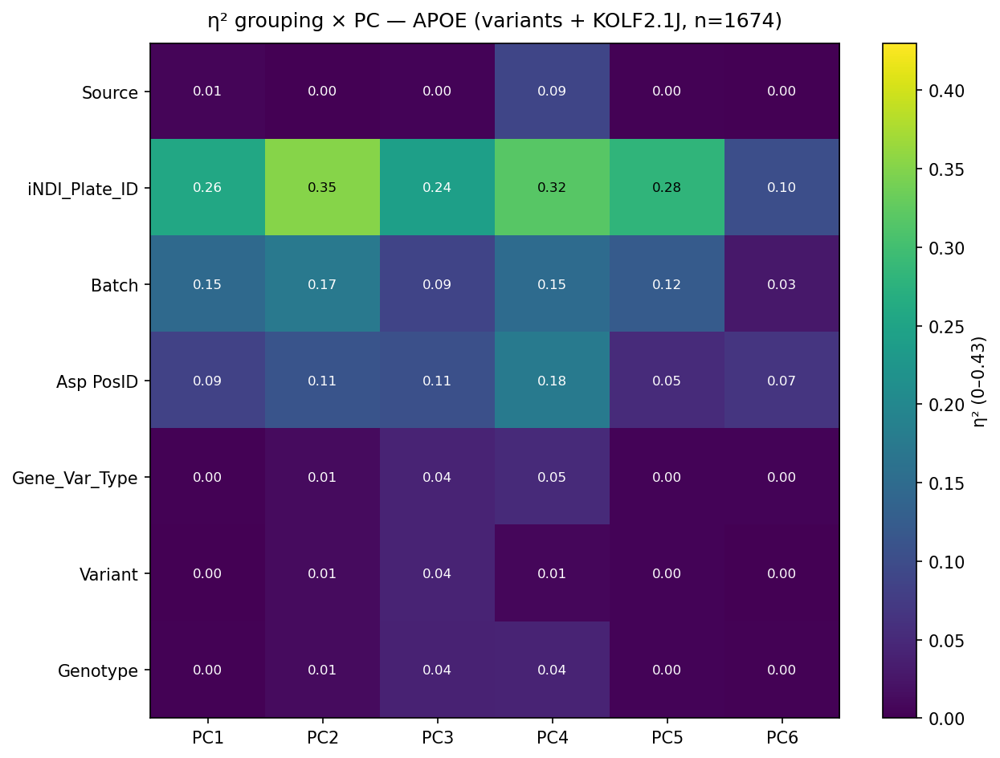

  APP: 613 variant + 1450 KOLF rows


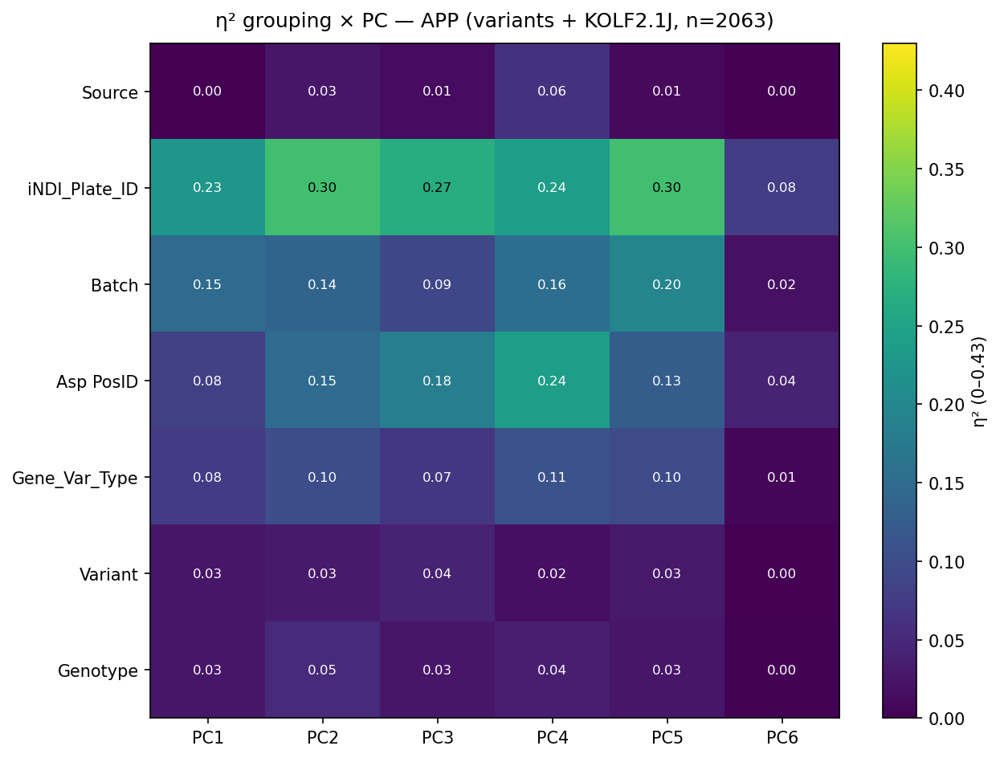

  FUS: 481 variant + 1450 KOLF rows


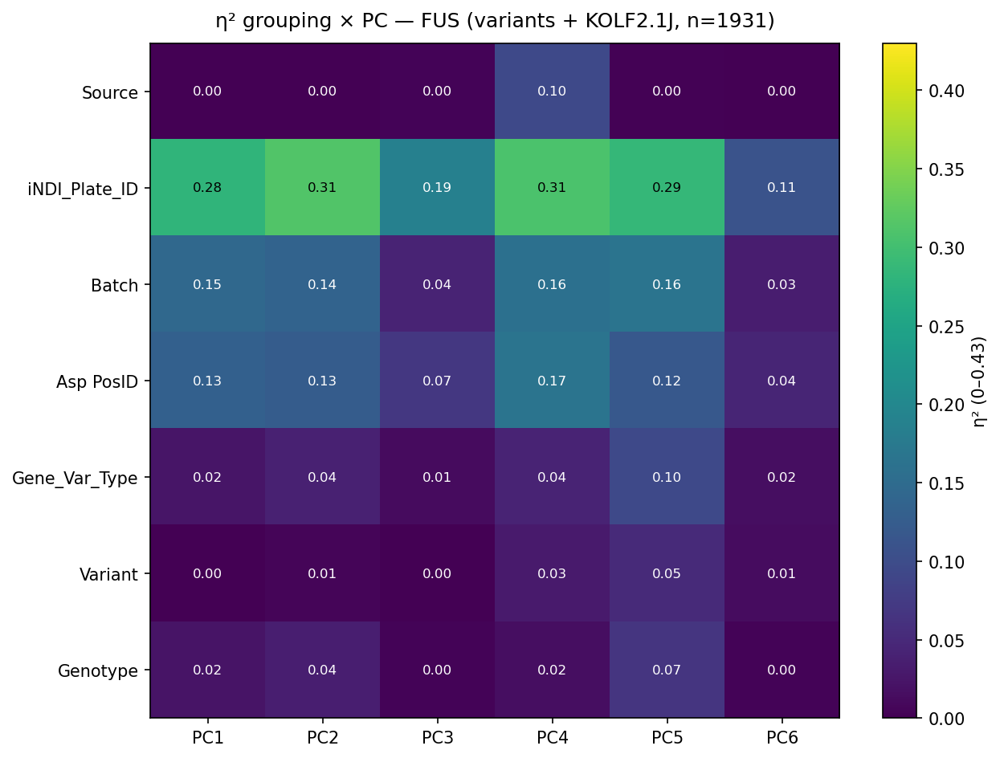

  GRN: 268 variant + 1450 KOLF rows


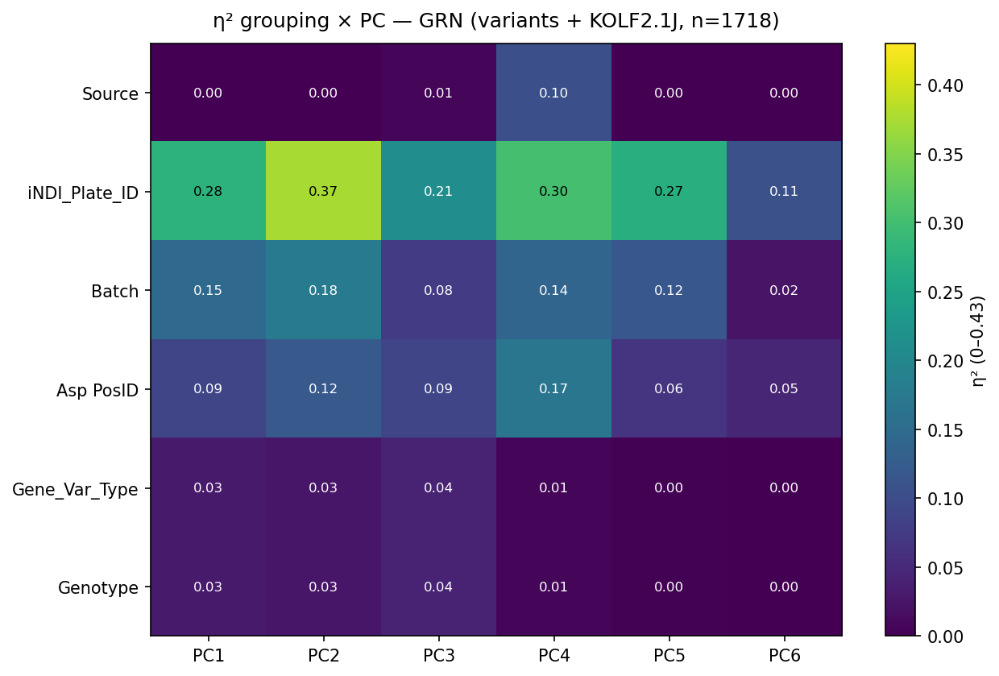

  HNRNPA1: 350 variant + 1450 KOLF rows


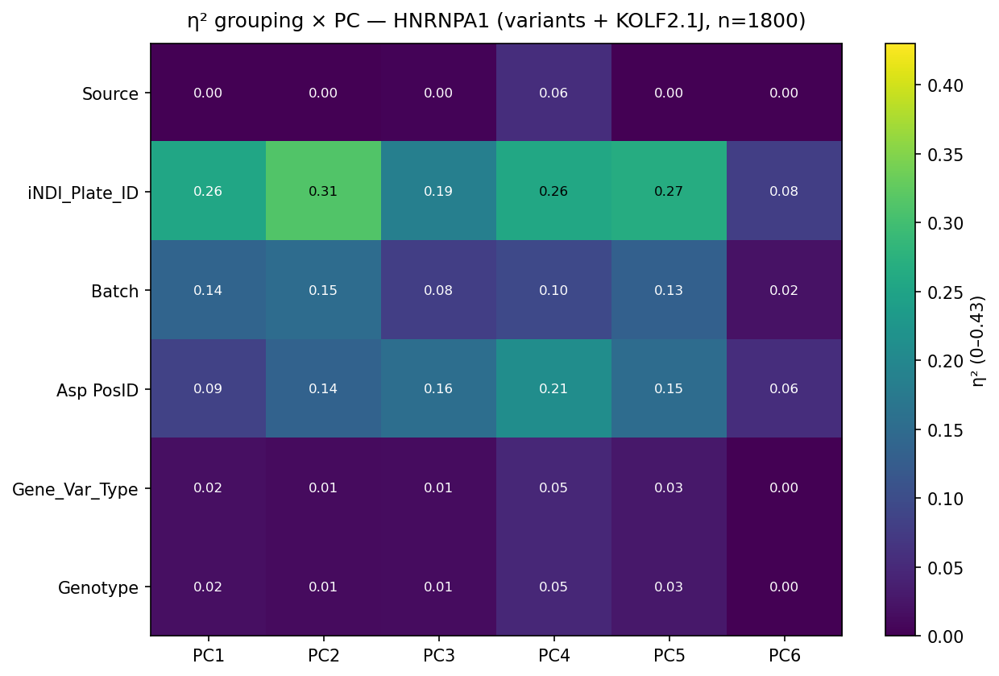

  MAPT: 255 variant + 1450 KOLF rows


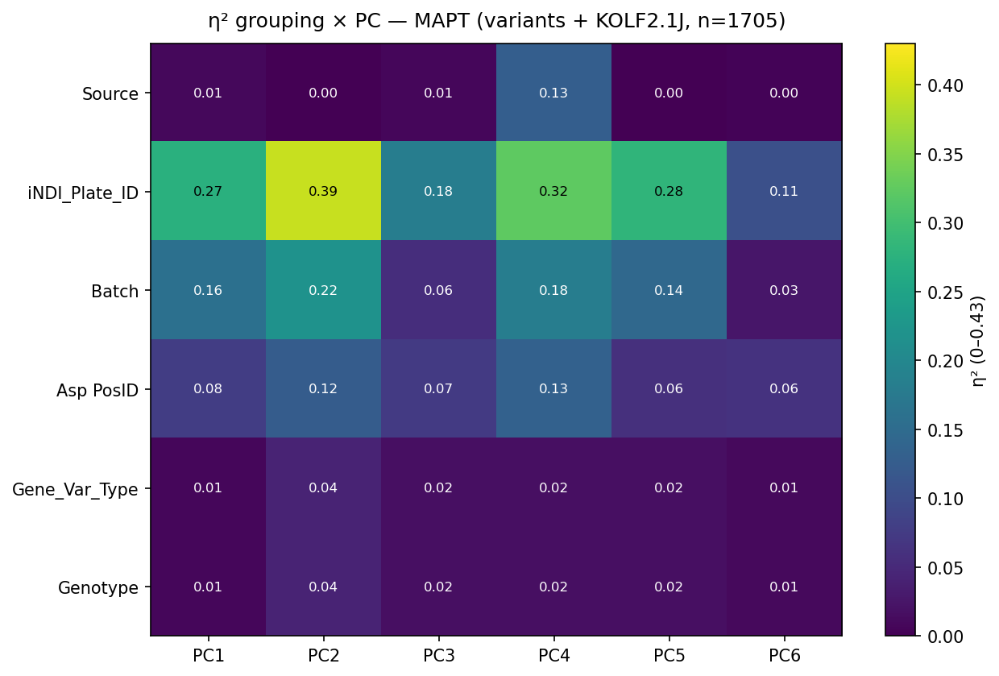

  PFN1: 268 variant + 1450 KOLF rows


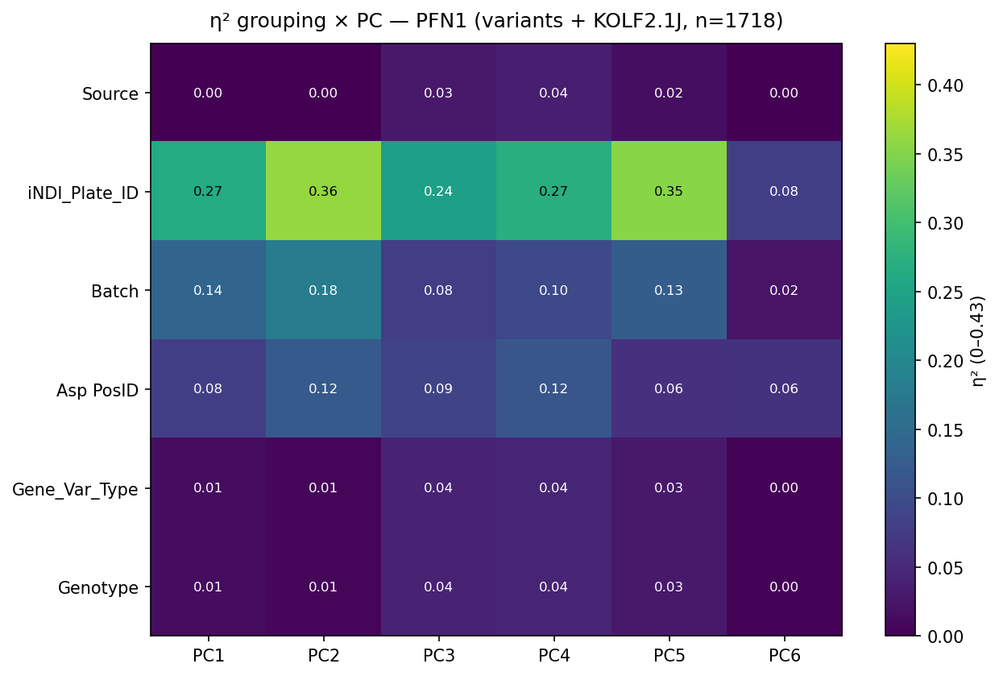

  PSEN1: 147 variant + 1450 KOLF rows


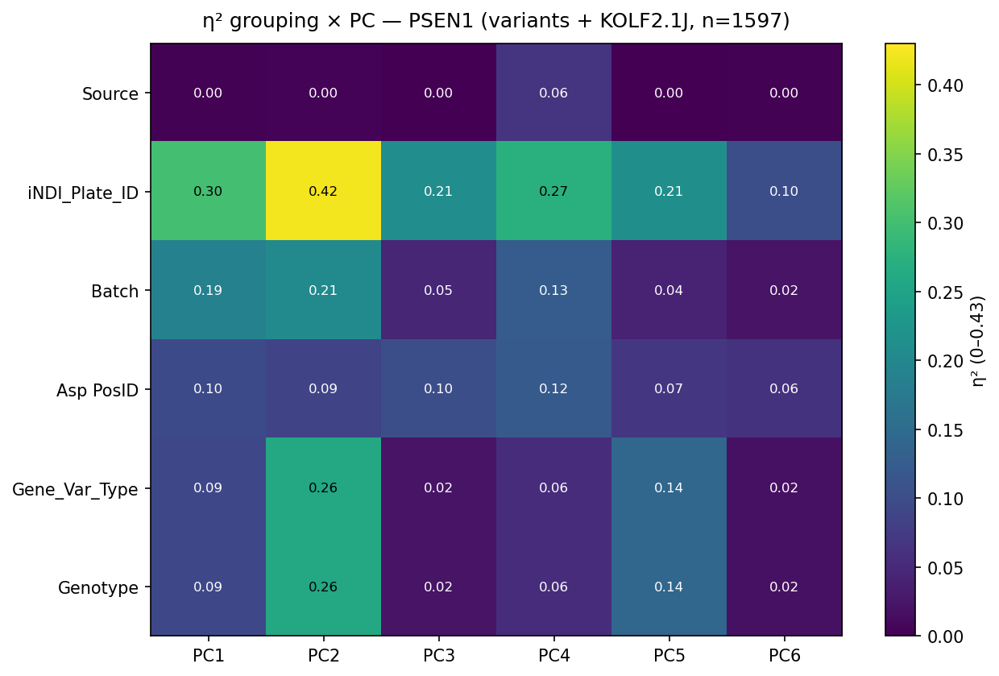

  PSEN2: 318 variant + 1450 KOLF rows


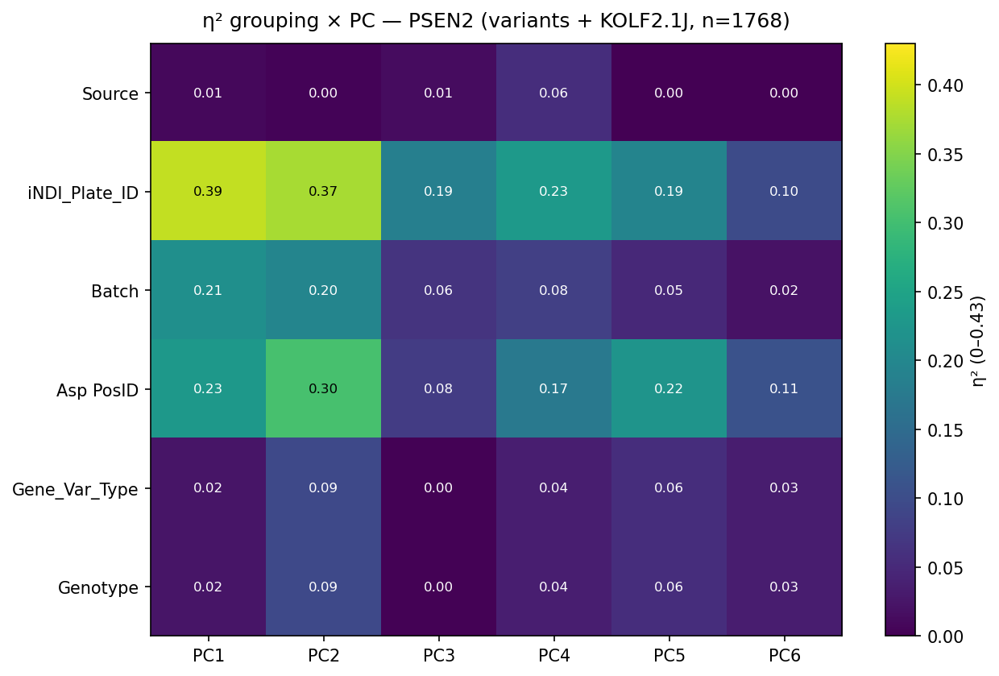

  SNCA: 363 variant + 1450 KOLF rows


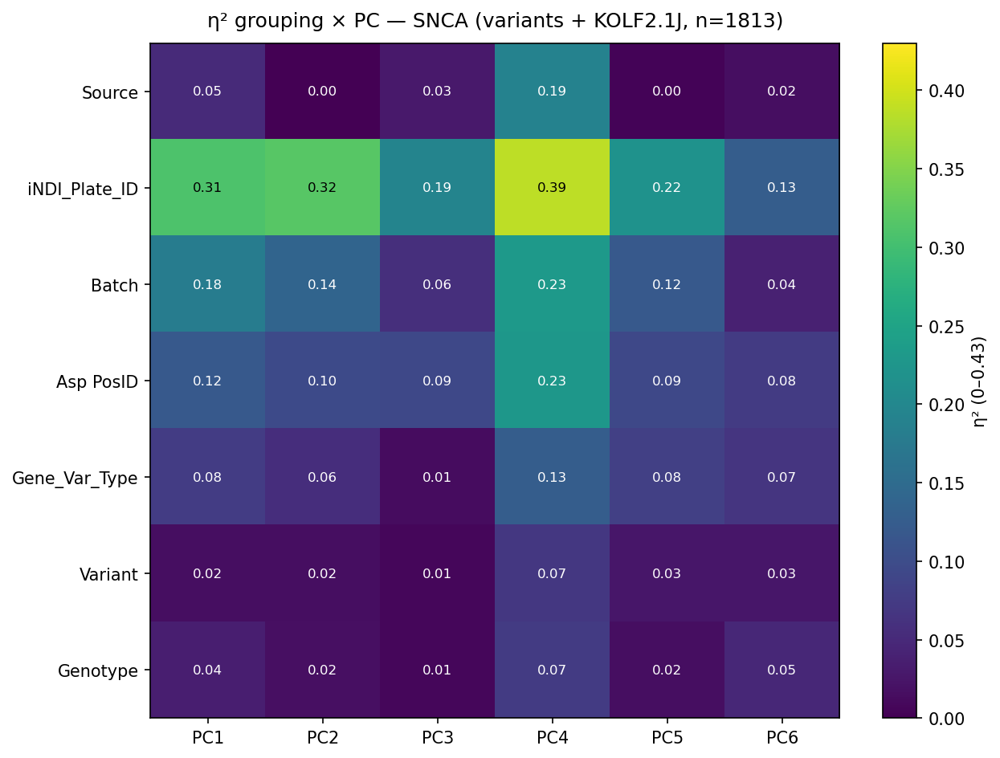

  SNCB: 249 variant + 1450 KOLF rows


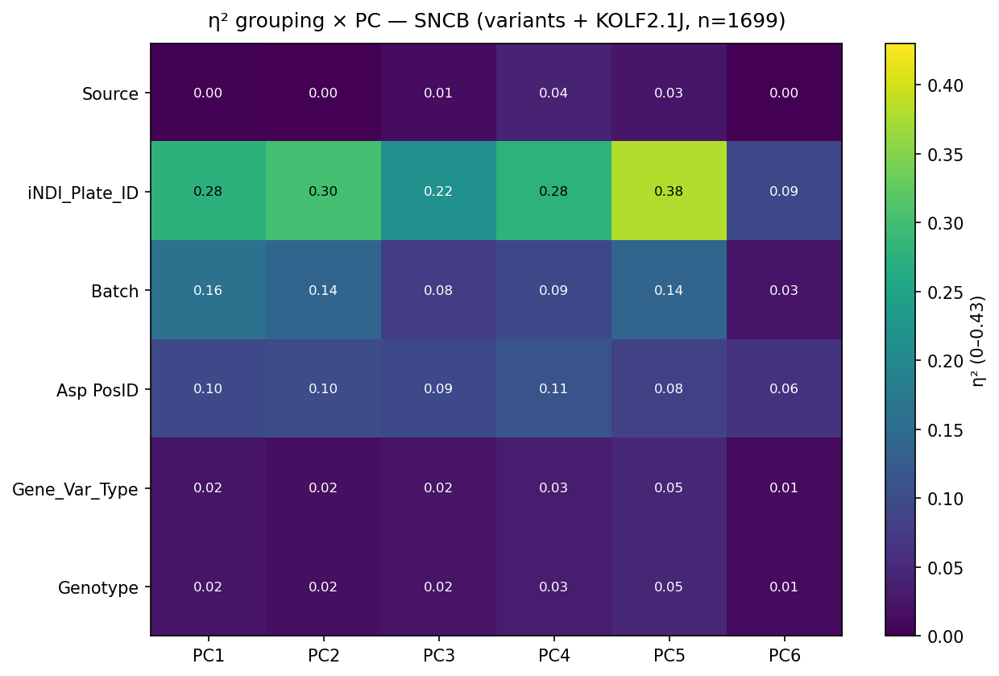

  TARDBP: 539 variant + 1450 KOLF rows


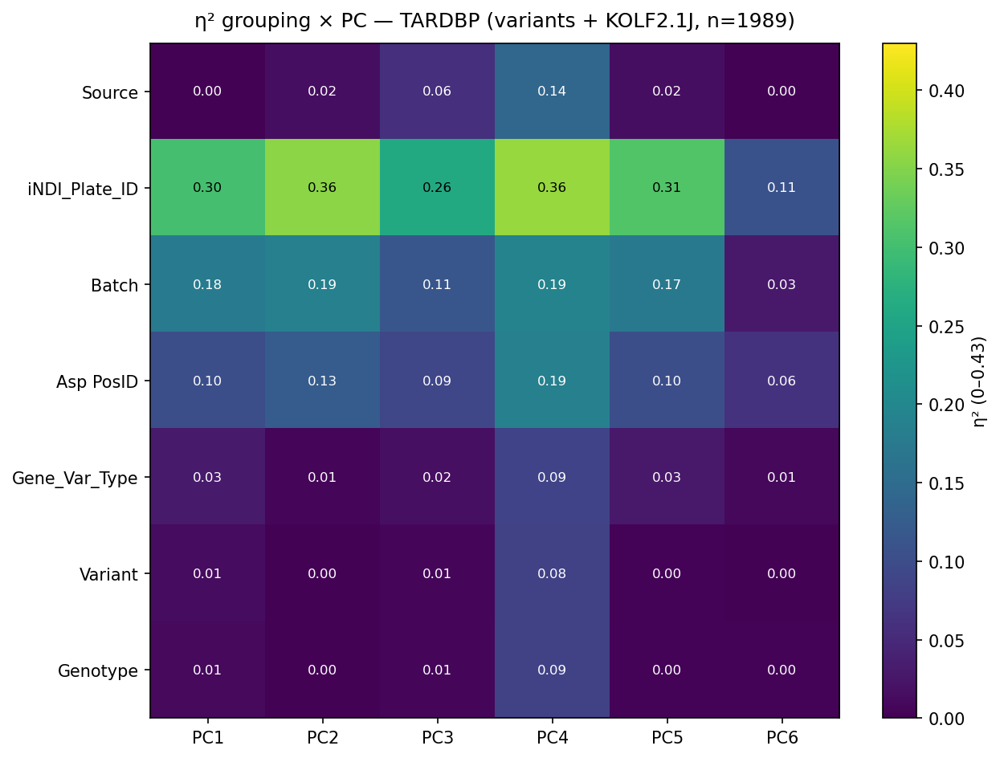

  TBK1: 277 variant + 1450 KOLF rows


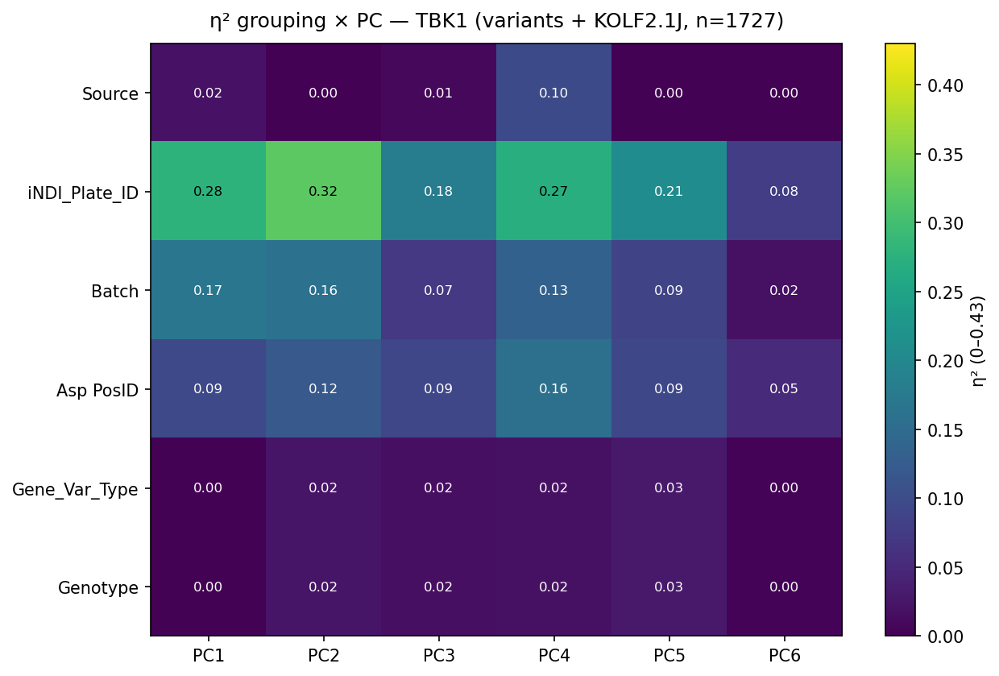

  TIA1: 144 variant + 1450 KOLF rows


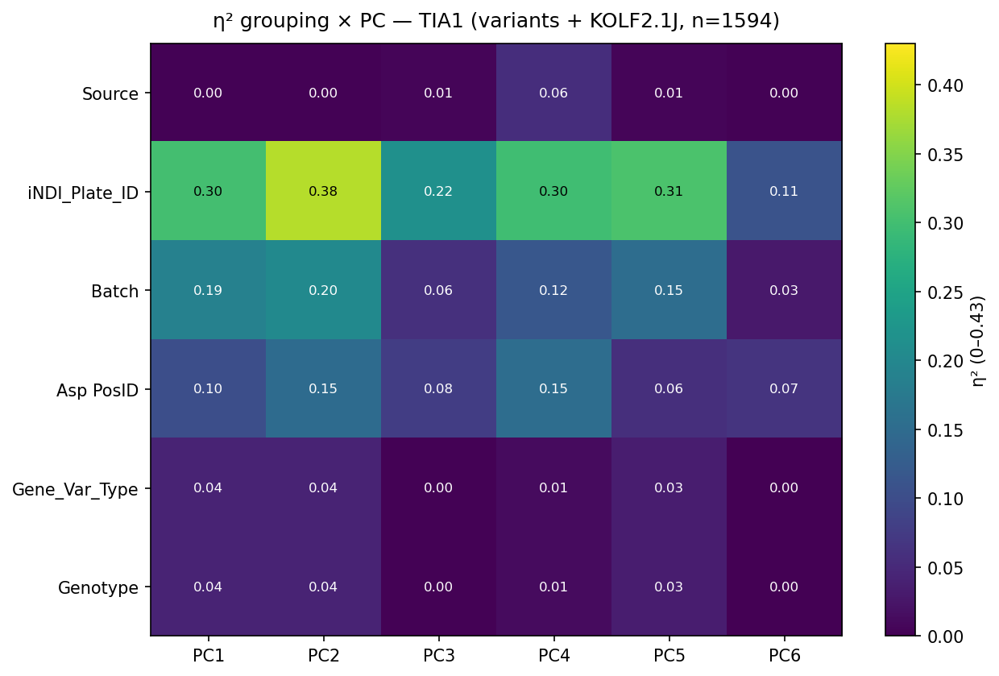

  UBQLN2: 132 variant + 1450 KOLF rows


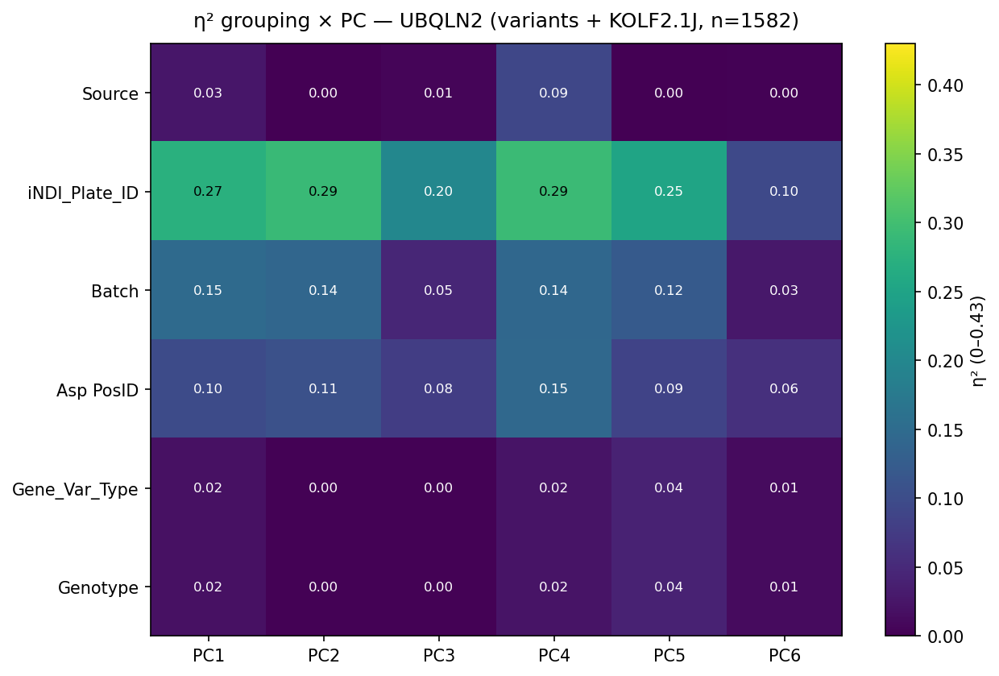

  VCP: 228 variant + 1450 KOLF rows


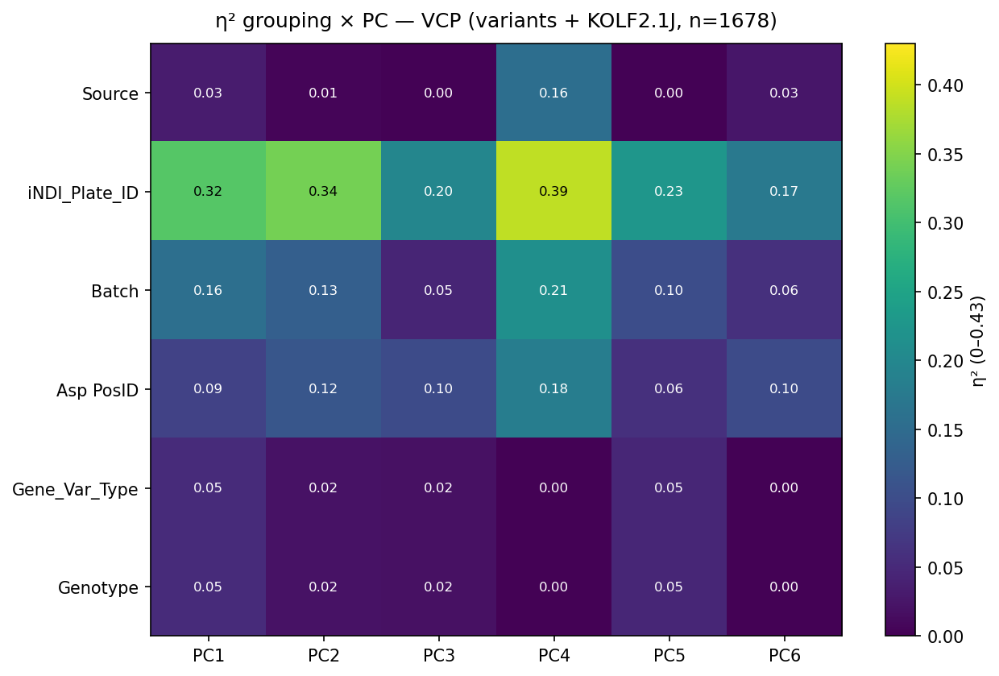

[facet] 16 genes; 1450 total KOLF2.1J rows (plate-matched per facet)
  APOE: 224 variant + 181 KOLF rows on 3 plate(s)


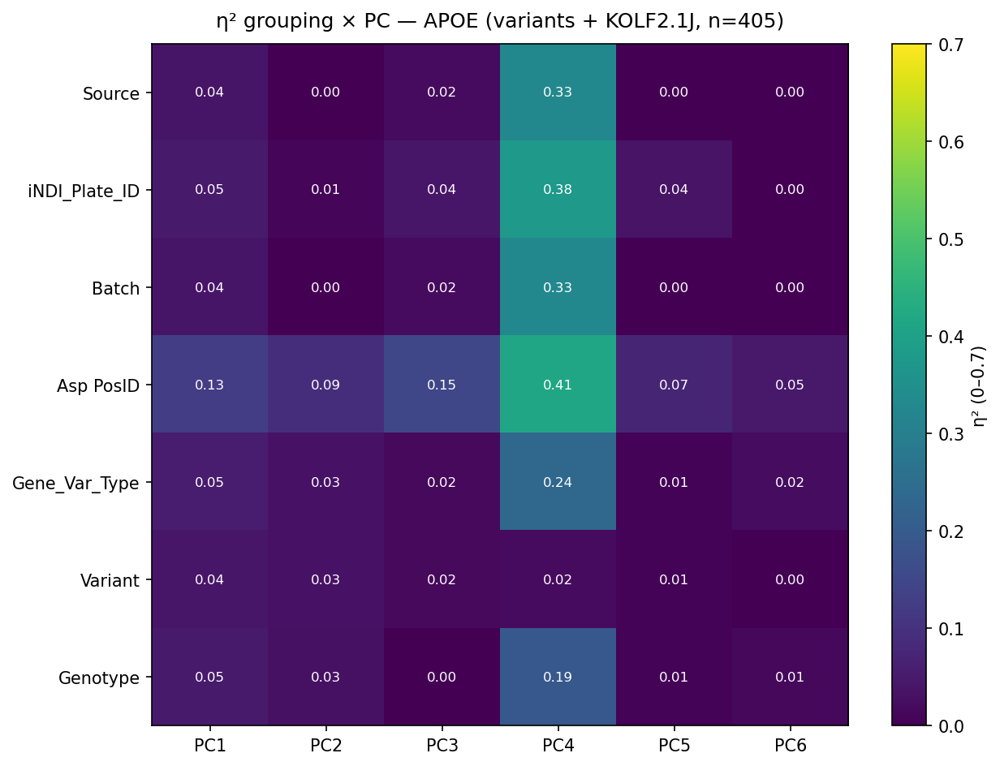

  APP: 613 variant + 433 KOLF rows on 6 plate(s)


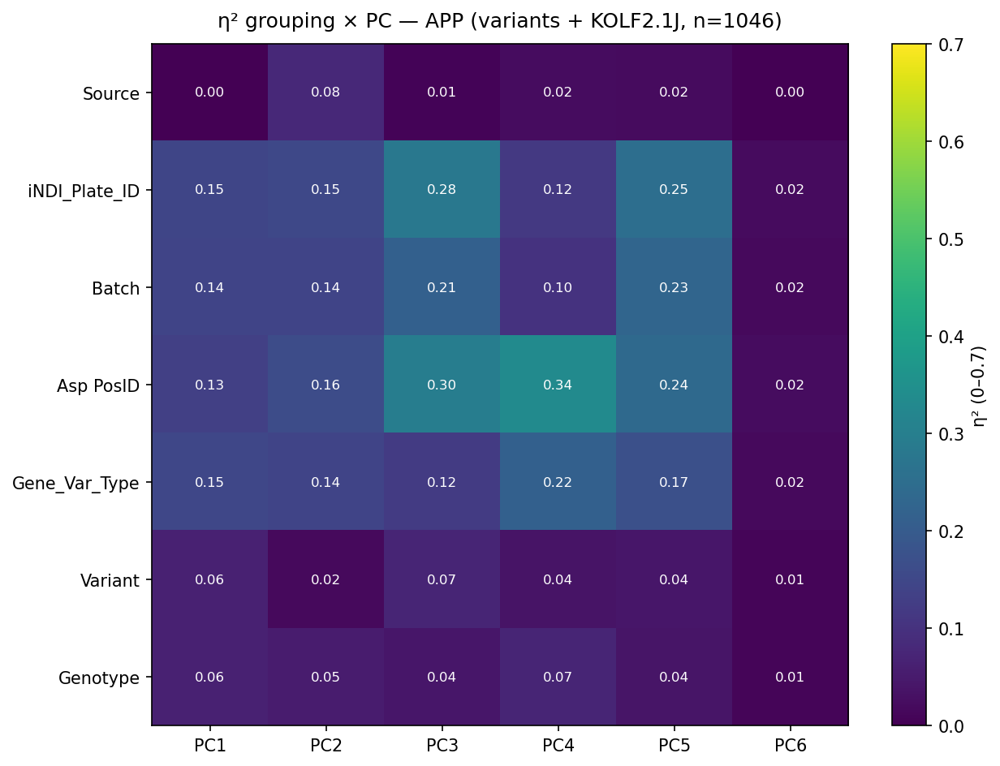

  FUS: 481 variant + 427 KOLF rows on 6 plate(s)


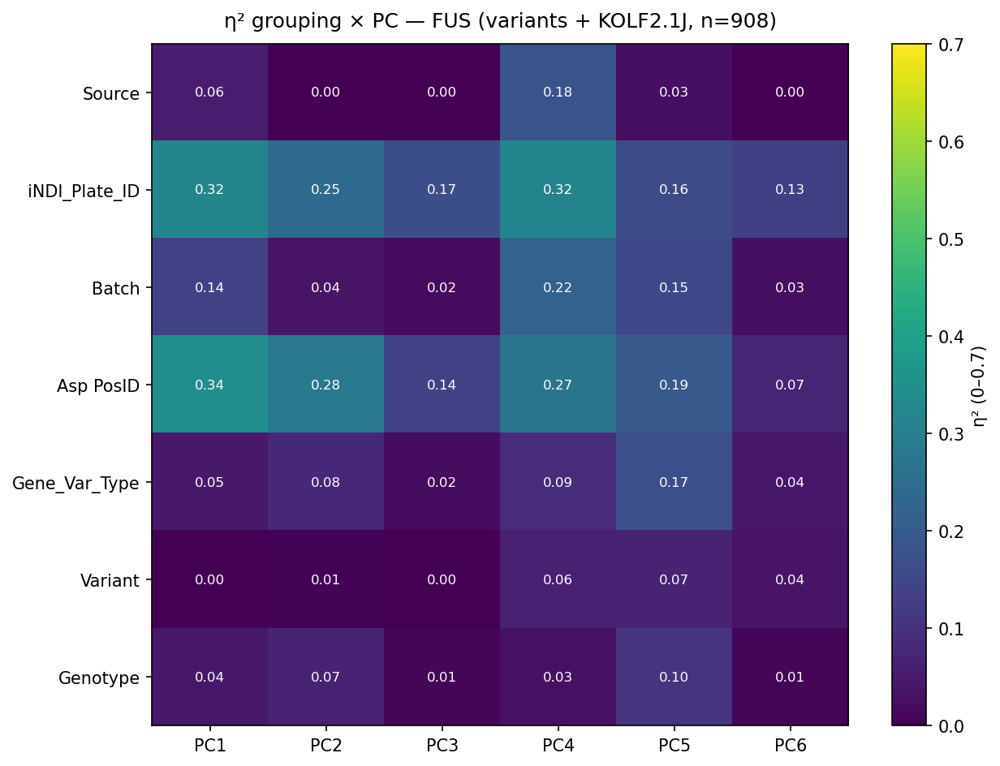

  GRN: 268 variant + 224 KOLF rows on 4 plate(s)


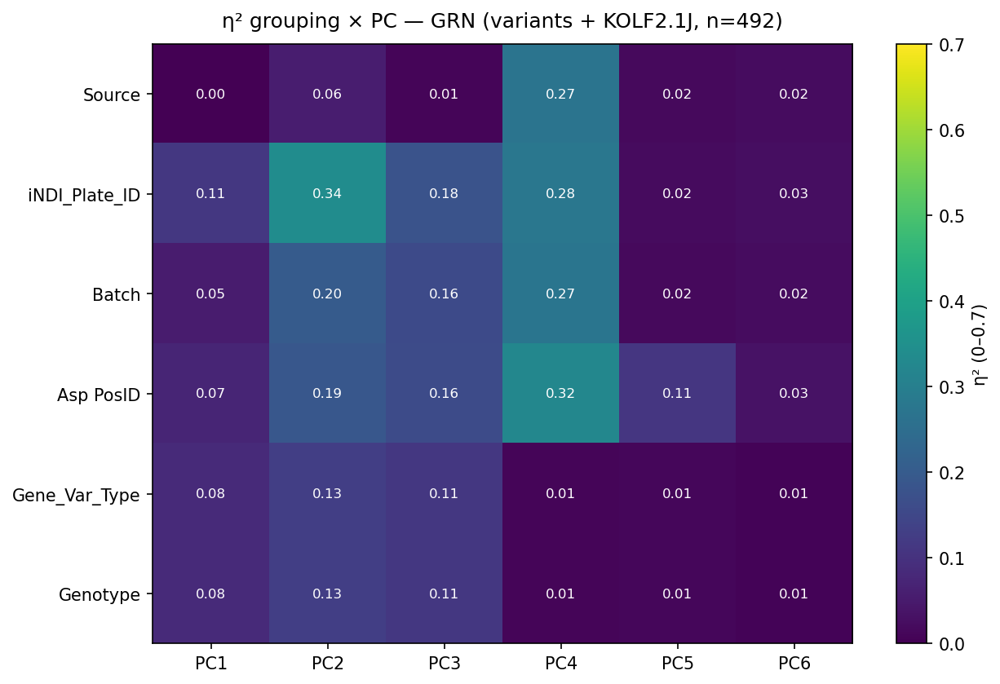

  HNRNPA1: 350 variant + 248 KOLF rows on 4 plate(s)


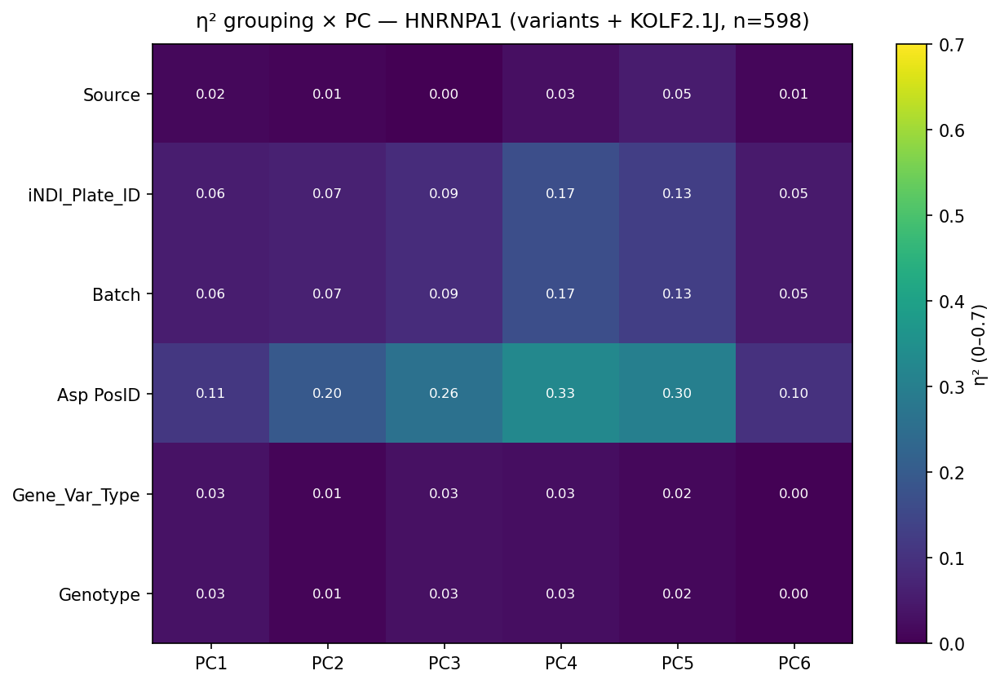

  MAPT: 255 variant + 180 KOLF rows on 3 plate(s)


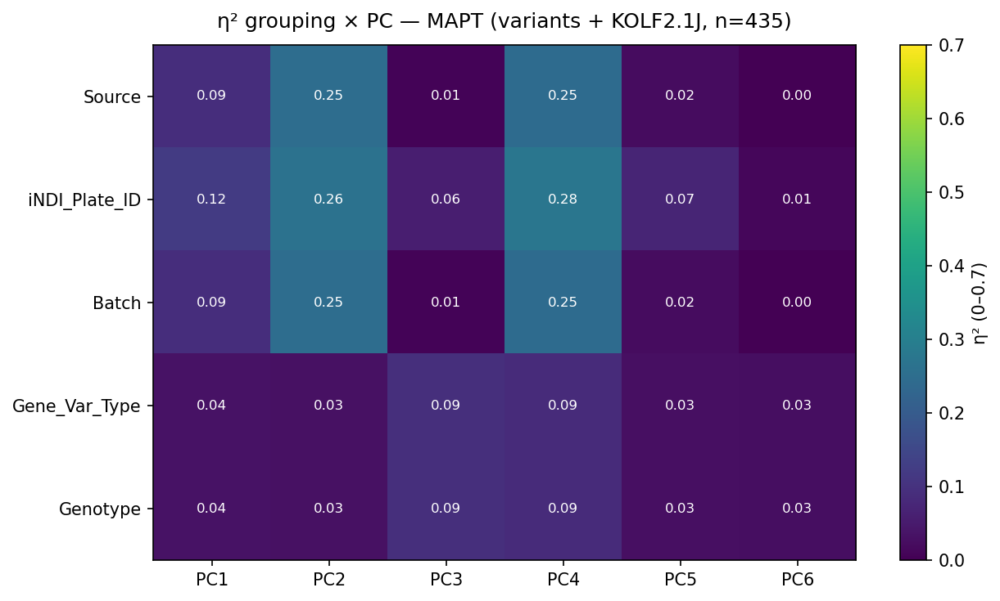

  PFN1: 268 variant + 180 KOLF rows on 3 plate(s)


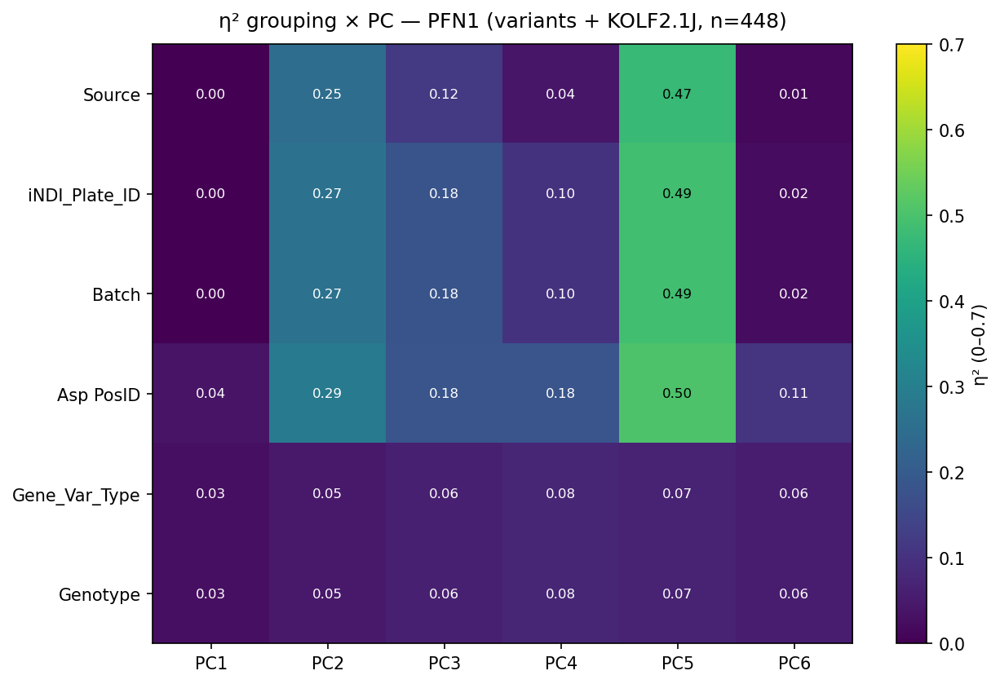

  PSEN1: 147 variant + 239 KOLF rows on 3 plate(s)


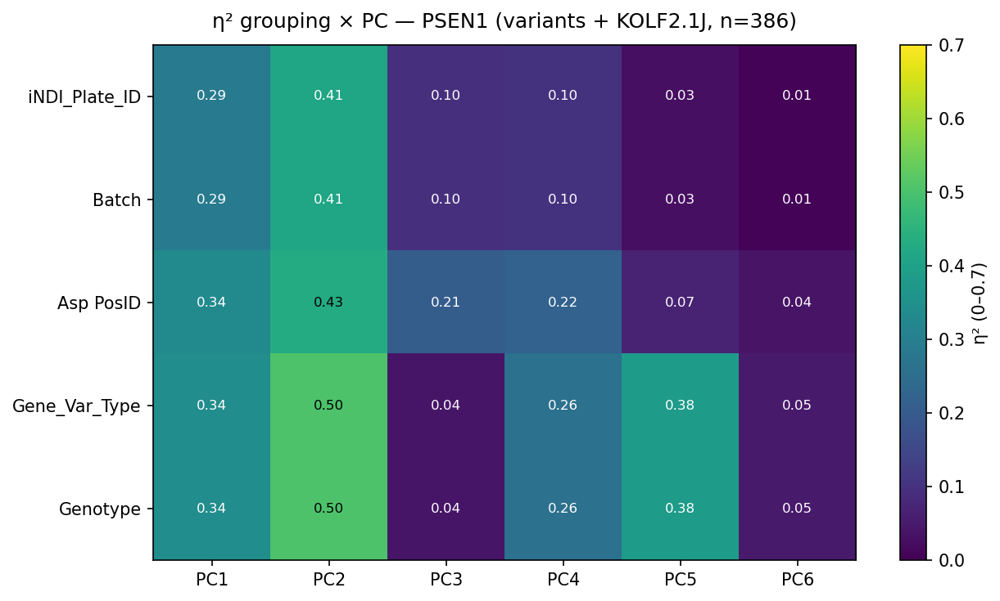

  PSEN2: 318 variant + 396 KOLF rows on 5 plate(s)


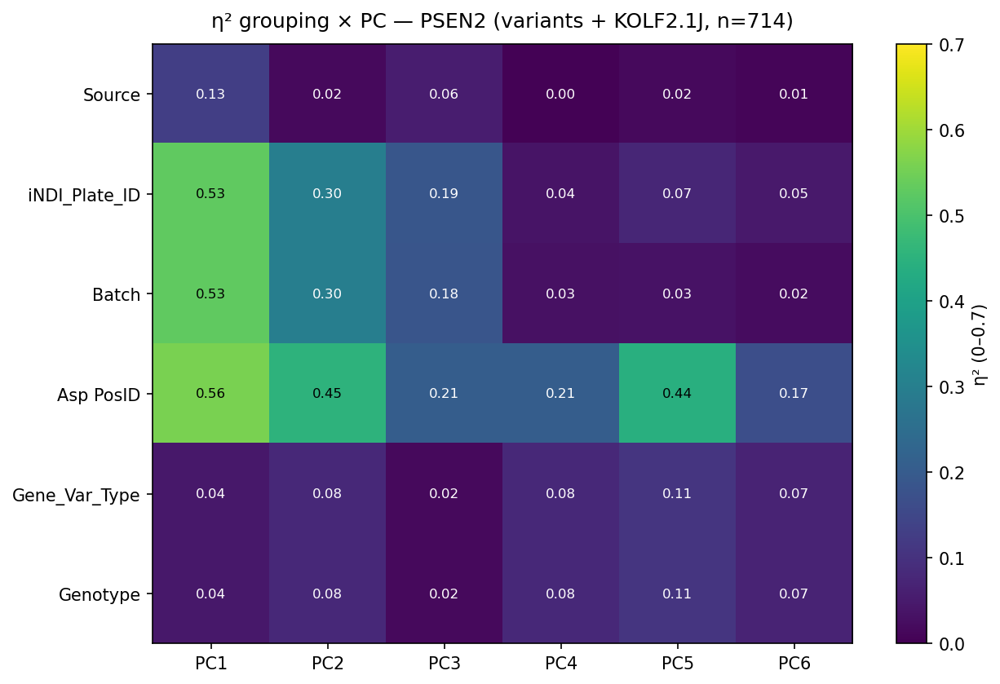

  SNCA: 363 variant + 259 KOLF rows on 4 plate(s)


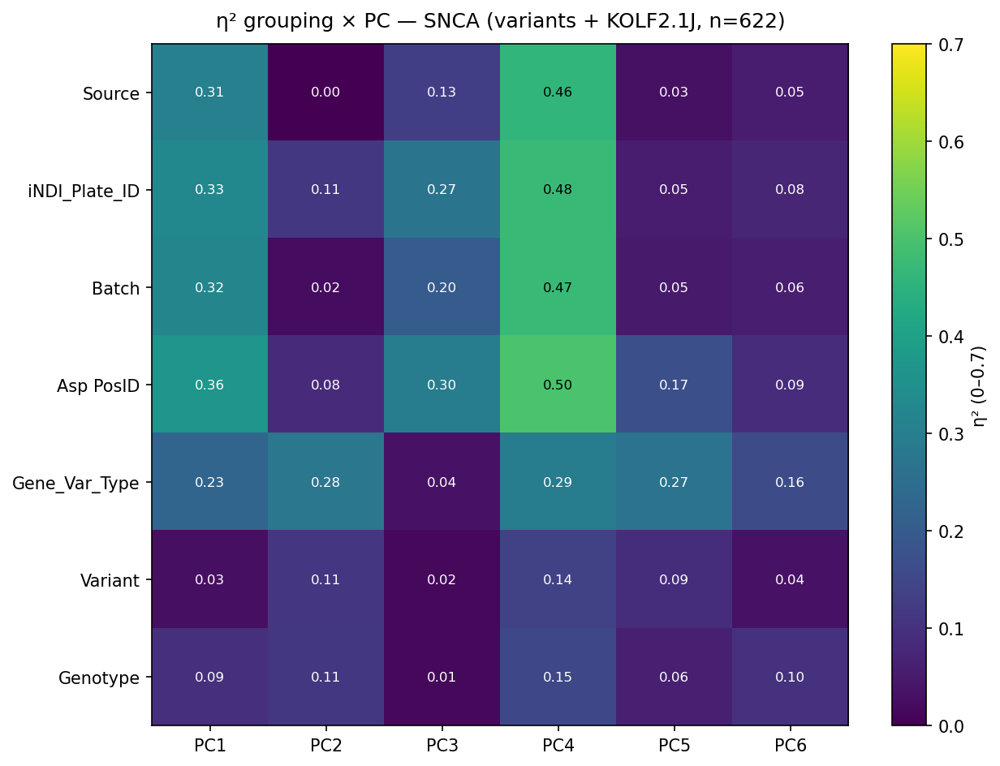

  SNCB: 249 variant + 234 KOLF rows on 3 plate(s)


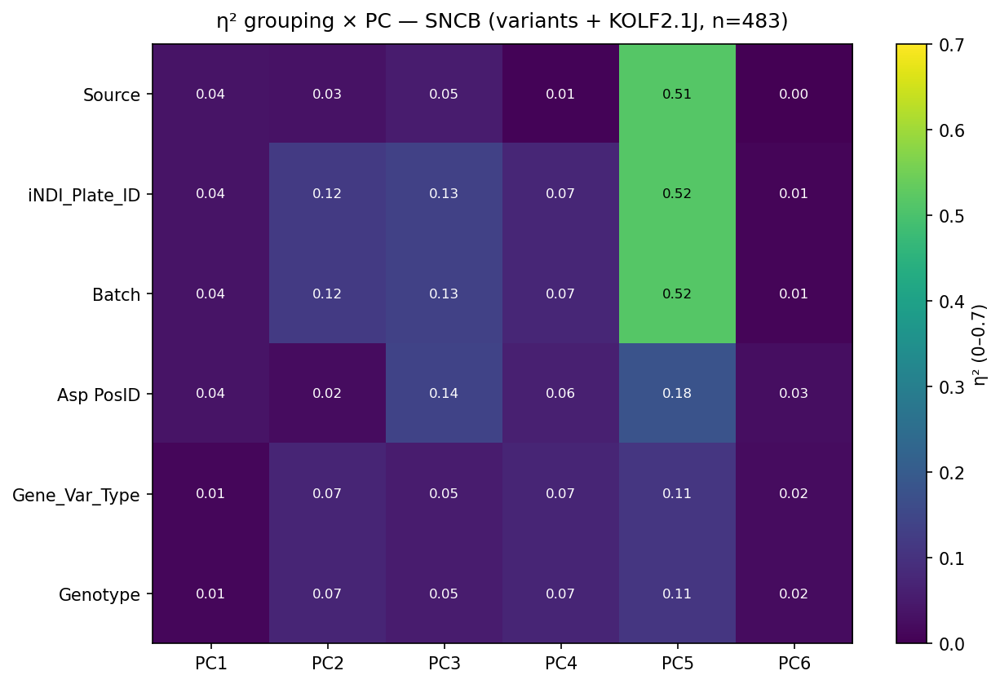

  TARDBP: 539 variant + 360 KOLF rows on 6 plate(s)


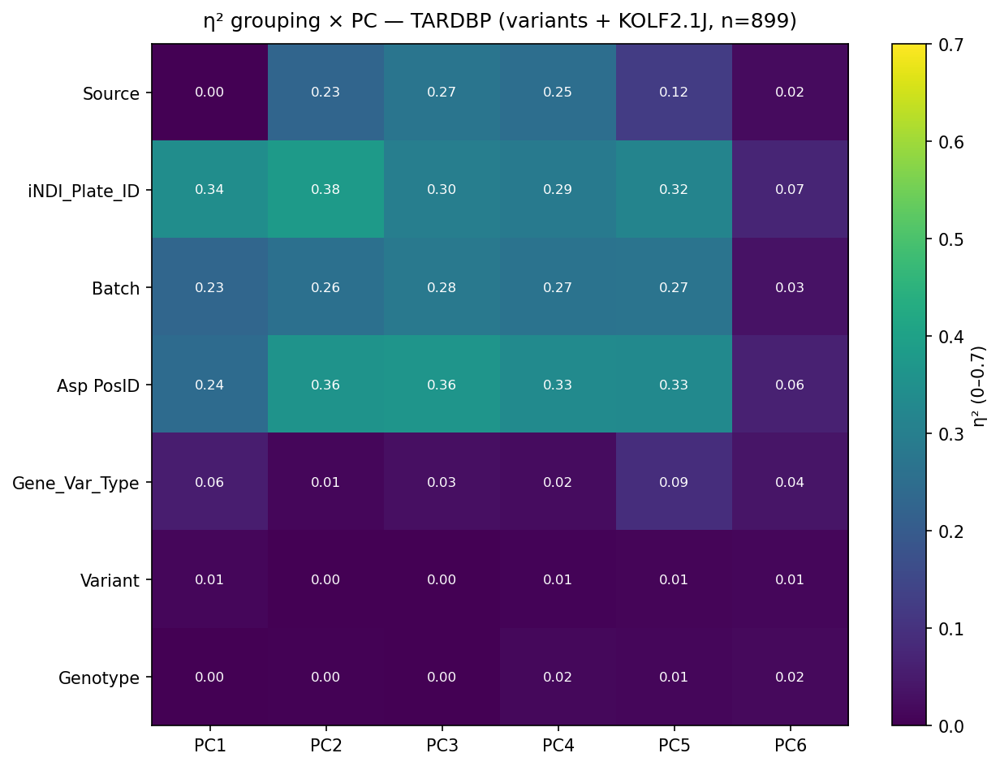

  TBK1: 277 variant + 276 KOLF rows on 4 plate(s)


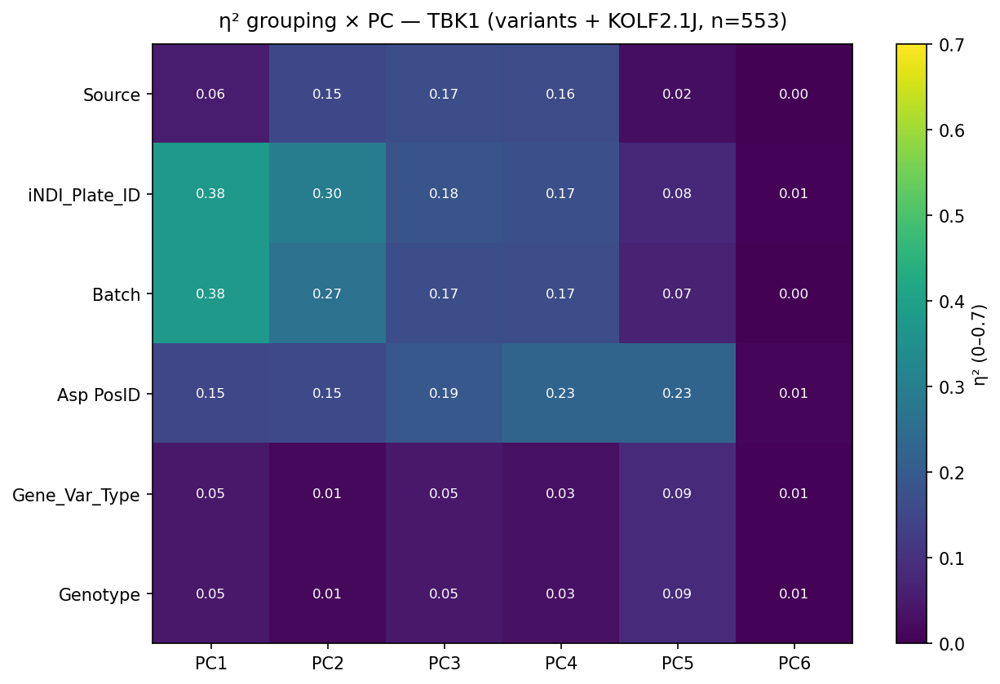

  TIA1: 144 variant + 192 KOLF rows on 2 plate(s)


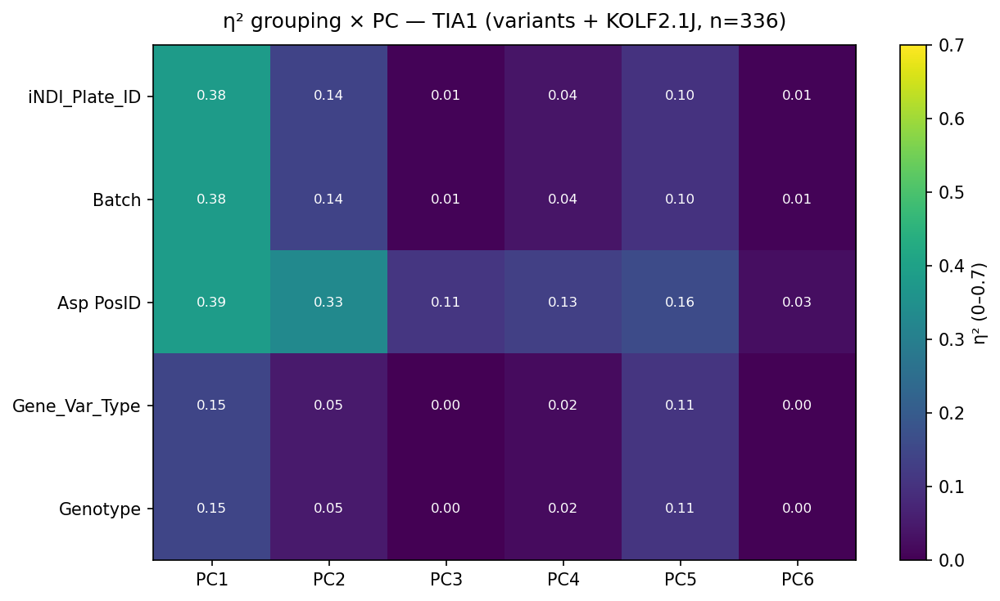

  UBQLN2: 132 variant + 136 KOLF rows on 2 plate(s)


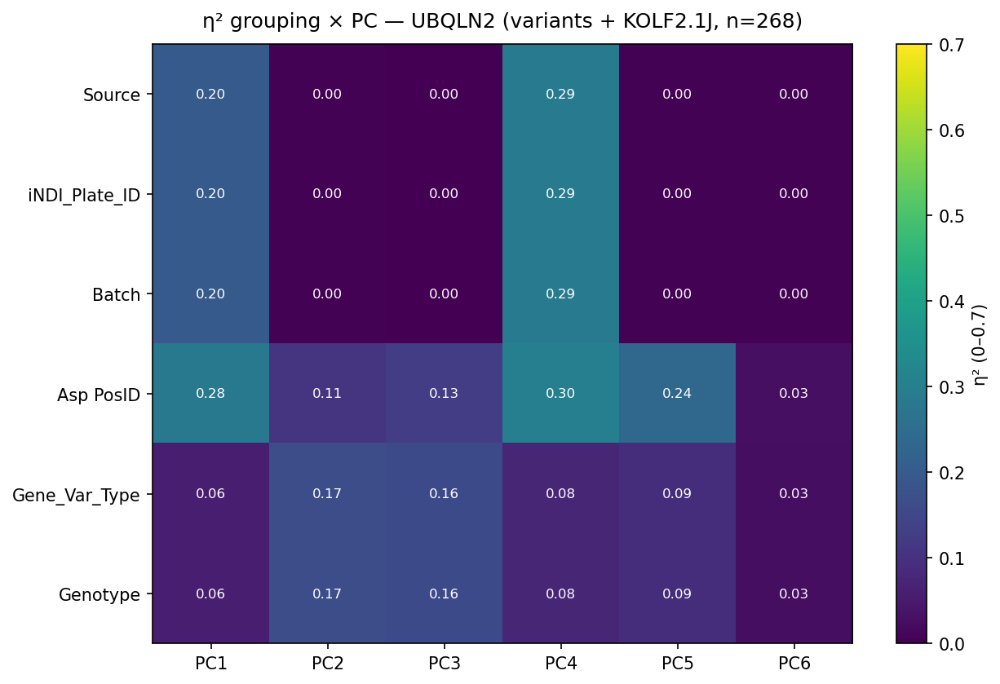

  VCP: 228 variant + 124 KOLF rows on 2 plate(s)


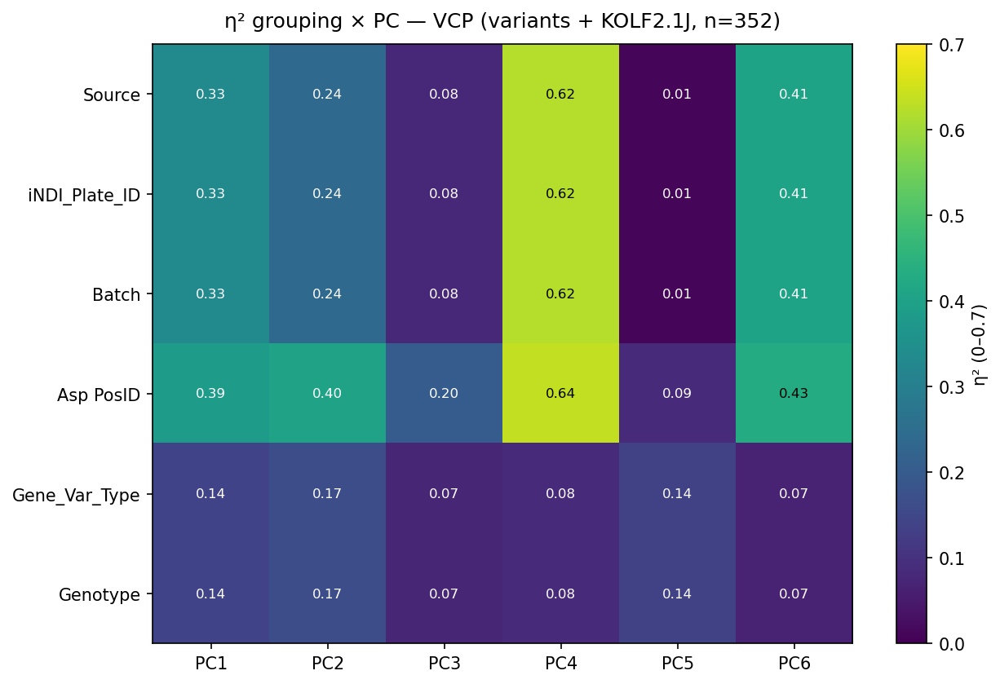

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- your original eta_squared, unchanged ----------------------------------
def eta_squared(values, groups):
    values = np.asarray(values, dtype=float)
    mask = np.isfinite(values)
    values, groups = values[mask], np.asarray(groups)[mask]
    if values.size == 0:
        return np.nan
    grand = values.mean()
    ss_total = ((values - grand) ** 2).sum()
    ss_between = 0.0
    for g in pd.unique(groups):
        v = values[groups == g]
        if v.size == 0:
            continue
        ss_between += len(v) * (v.mean() - grand) ** 2
    return ss_between / ss_total if ss_total > 0 else np.nan


# --- optional well-level aggregation (strongly recommended) ----------------
# A per-gene variant effect on a mean is invisible at single-nucleus level.
# Collapse ROI rows to one row per well before faceting.
def aggregate_to_wells(data, well_keys, carry_cols, pc_cols):
    agg = {pc: "median" for pc in pc_cols}
    for c in carry_cols:
        agg[c] = "first"
    return data.groupby(list(well_keys), as_index=False).agg(agg)


# --- shared WT/control predicate -------------------------------------------
def is_wt(data, gene_col="Gene"):
    """True for the shared KOLF2.1J parental-control rows (they live in Gene)."""
    return data[gene_col].astype(str).str.strip() == "KOLF2.1J"


# --- the original single-matrix eta computation, as a reusable helper -------
def eta_matrix(data, group_cols, pc_cols):
    """grouping x PC matrix of η² for one data subset (e.g. one gene facet)."""
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)
    for gc in group_cols:
        groups = data[gc].to_numpy()
        for pc in pc_cols:
            mat.loc[gc, pc] = eta_squared(data[pc].to_numpy(), groups)
    return mat


# --- per-gene: ONE SEPARATE FIGURE per gene --------------------------------
def plot_gene_heatmap(sub, group_cols, pc_cols, gene, vmax=0.2, annot=True,
                      drop_constant=True):
    """Draw a single grouping x PC η² heatmap for one gene's subset."""
    rows = list(group_cols)
    if drop_constant:  # hide grouping rows with <2 levels in this facet
        rows = [g for g in rows if g in sub.columns and sub[g].nunique() > 1]
    mat = eta_matrix(sub, rows, pc_cols)

    fig, ax = plt.subplots(
        figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(mat.index) + 1.5), dpi=150)
    im = ax.imshow(mat.values.astype(float), cmap="viridis",
                   vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(mat.index))); ax.set_yticklabels(mat.index)
    plt.colorbar(im, ax=ax, label=f"η² (0–{vmax})")
    ax.set_title(f"η² grouping × PC — {gene} (variants + KOLF2.1J, n={len(sub)})",
                 pad=10)
    if annot:
        for i in range(len(mat.index)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if v < 0.6 * vmax else "black",
                            fontsize=8)
    plt.tight_layout(); plt.show()
    return mat


def facet_by_gene(data, group_cols, n_pcs=10,
                  gene_col="Gene", vmax=0.2, annot=True,
                  include_wt=True, drop_constant=True,
                  plate_match=False, plate_col="iNDI_Plate_ID"):
    """One separate η² heatmap figure per gene. Each gene's subset is that
    gene's variant rows plus the shared KOLF2.1J control rows.

    plate_match=True restricts the KOLF2.1J rows folded into each facet to the
    plates that gene's variants actually occupy, removing the plate confound
    that arises when controls span all plates but a gene sits on only a few.
    """
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))[:n_pcs]

    wt_mask = is_wt(data, gene_col)
    wt_rows = data[wt_mask]
    edited = data[~wt_mask]
    genes = sorted(pd.unique(edited[gene_col].dropna()))
    print(f"[facet] {len(genes)} genes; {len(wt_rows)} total KOLF2.1J rows "
          f"{'(plate-matched per facet)' if plate_match else '(all folded into each facet)'}")

    facet_groups = [g for g in group_cols if g != gene_col]

    mats = {}
    for gene in genes:
        gene_rows = edited[edited[gene_col] == gene]
        if include_wt:
            wt_use = wt_rows
            if plate_match and plate_col in data.columns:
                gene_plates = set(gene_rows[plate_col].dropna().unique())
                wt_use = wt_rows[wt_rows[plate_col].isin(gene_plates)]
            sub = pd.concat([gene_rows, wt_use], ignore_index=True)
            print(f"  {gene}: {len(gene_rows)} variant + {len(wt_use)} KOLF rows"
                  f"{f' on {len(set(gene_rows[plate_col].dropna().unique()))} plate(s)' if plate_match else ''}")
        else:
            sub = gene_rows
        mats[gene] = plot_gene_heatmap(sub, facet_groups, pc_cols, gene,
                                       vmax=vmax, annot=annot,
                                       drop_constant=drop_constant)
    return mats


# --- usage -----------------------------------------------------------------
GROUP_COLS = ["Source", "iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Variant", "Genotype"]

mats = facet_by_gene(well_level, GROUP_COLS, n_pcs=10, vmax=0.43, plate_match=False)
mats = facet_by_gene(well_level, GROUP_COLS, n_pcs=10, vmax=0.7, plate_match=True)

### Genotype faceted PCAs


MANUAL (2198 wells)


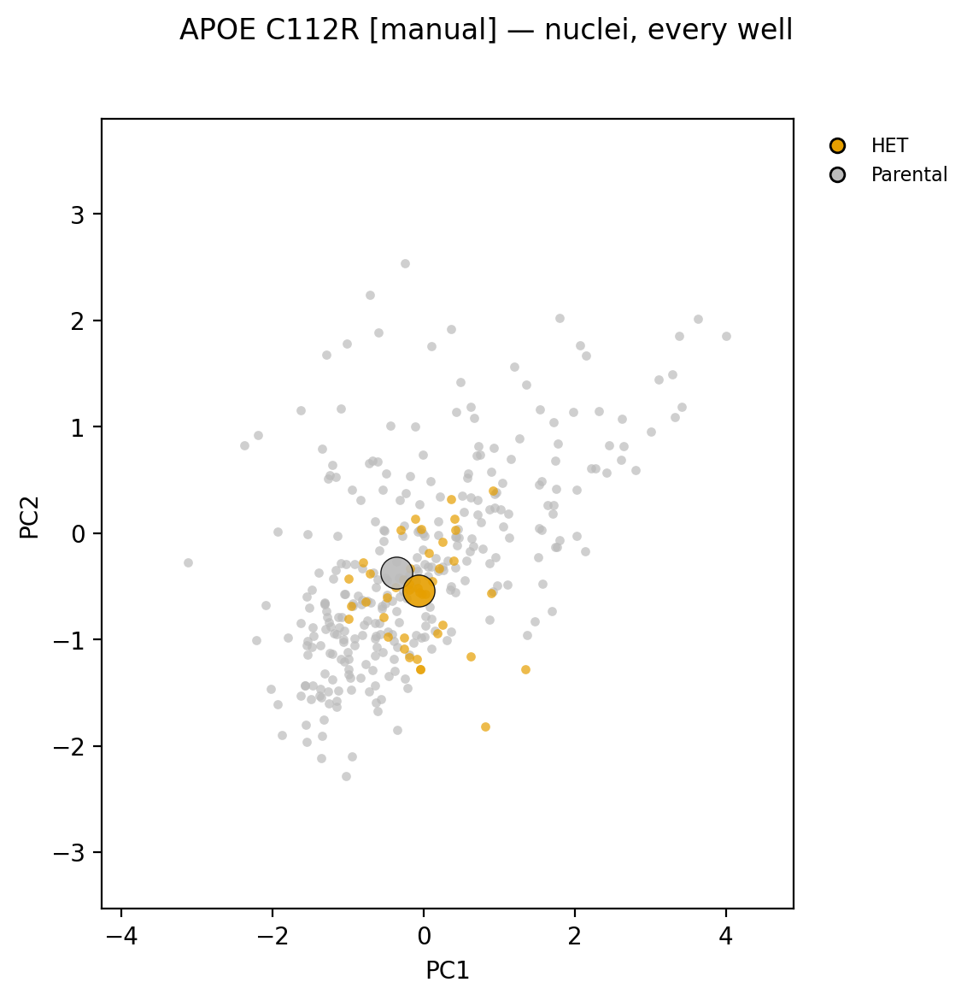

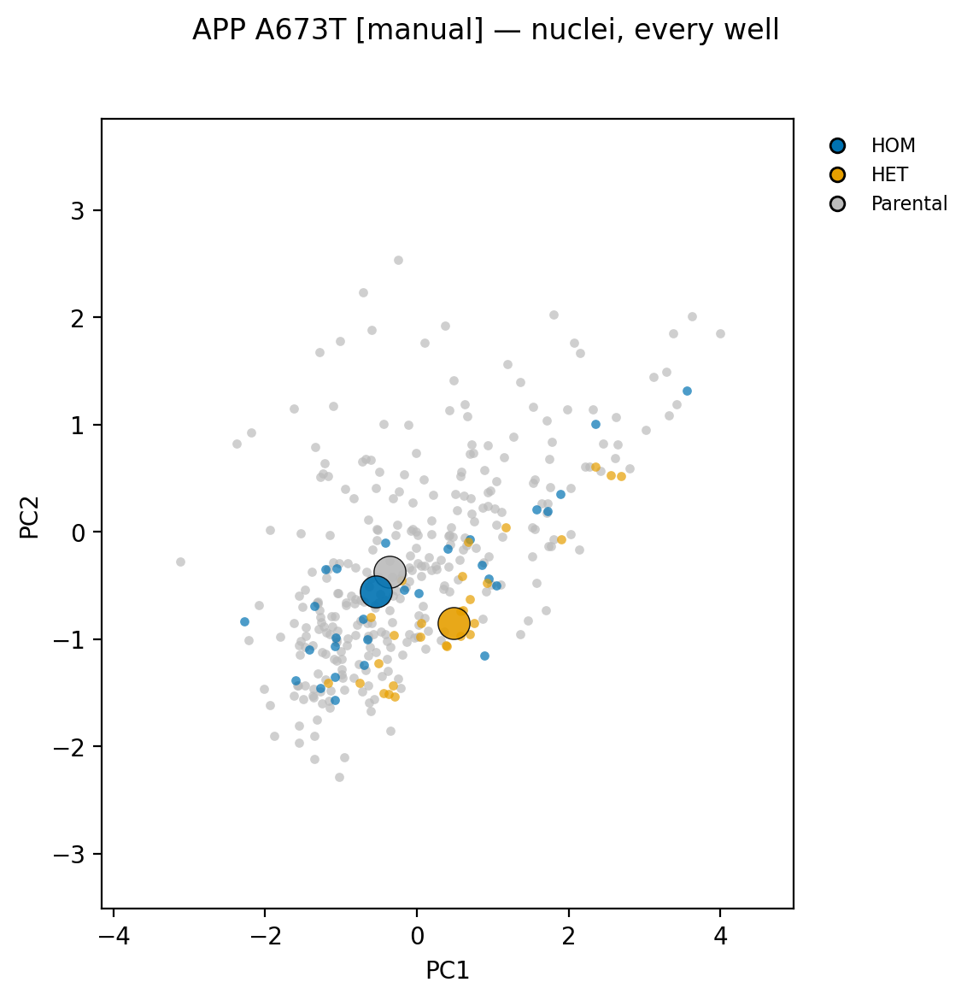

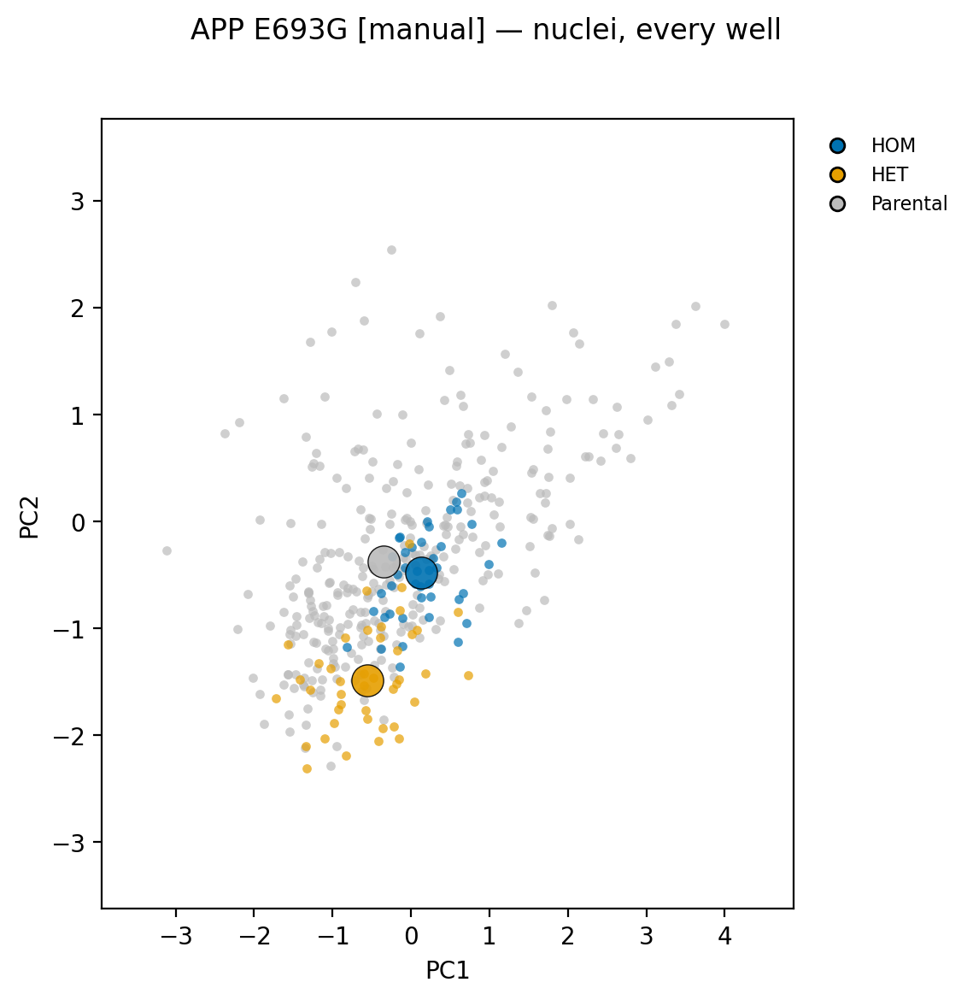

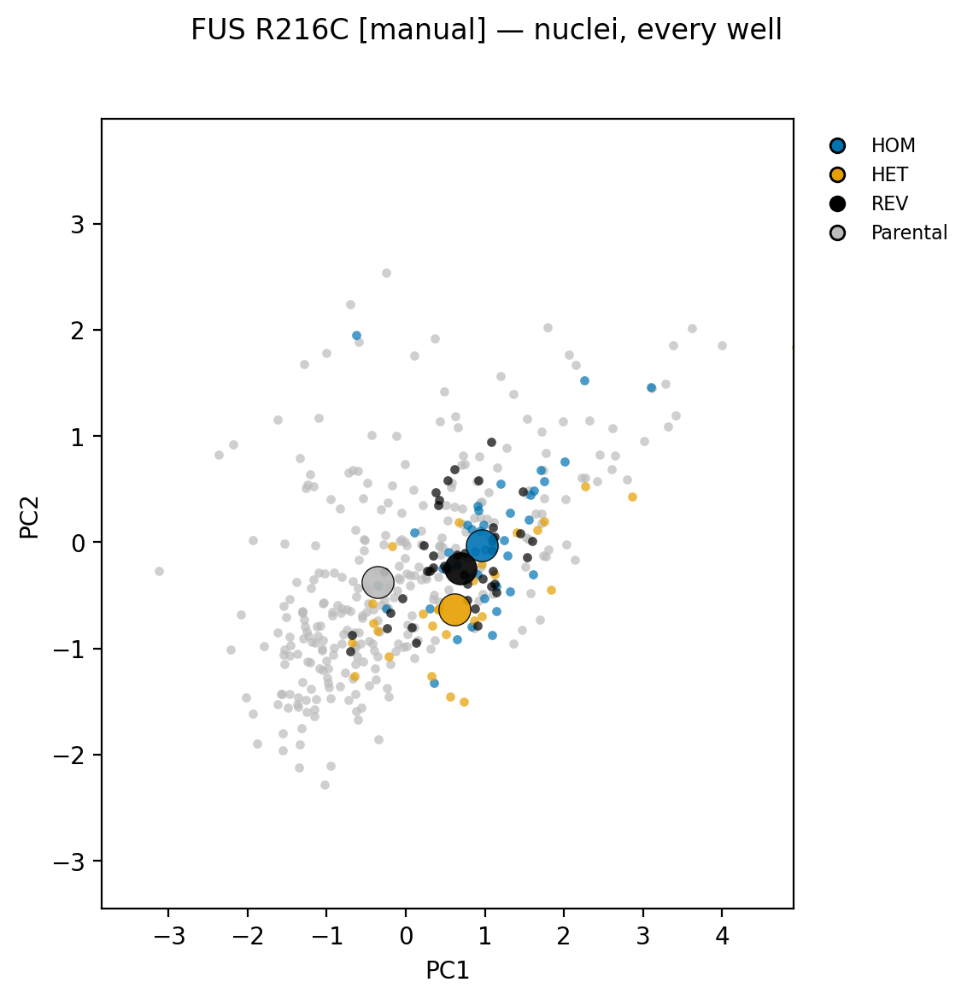

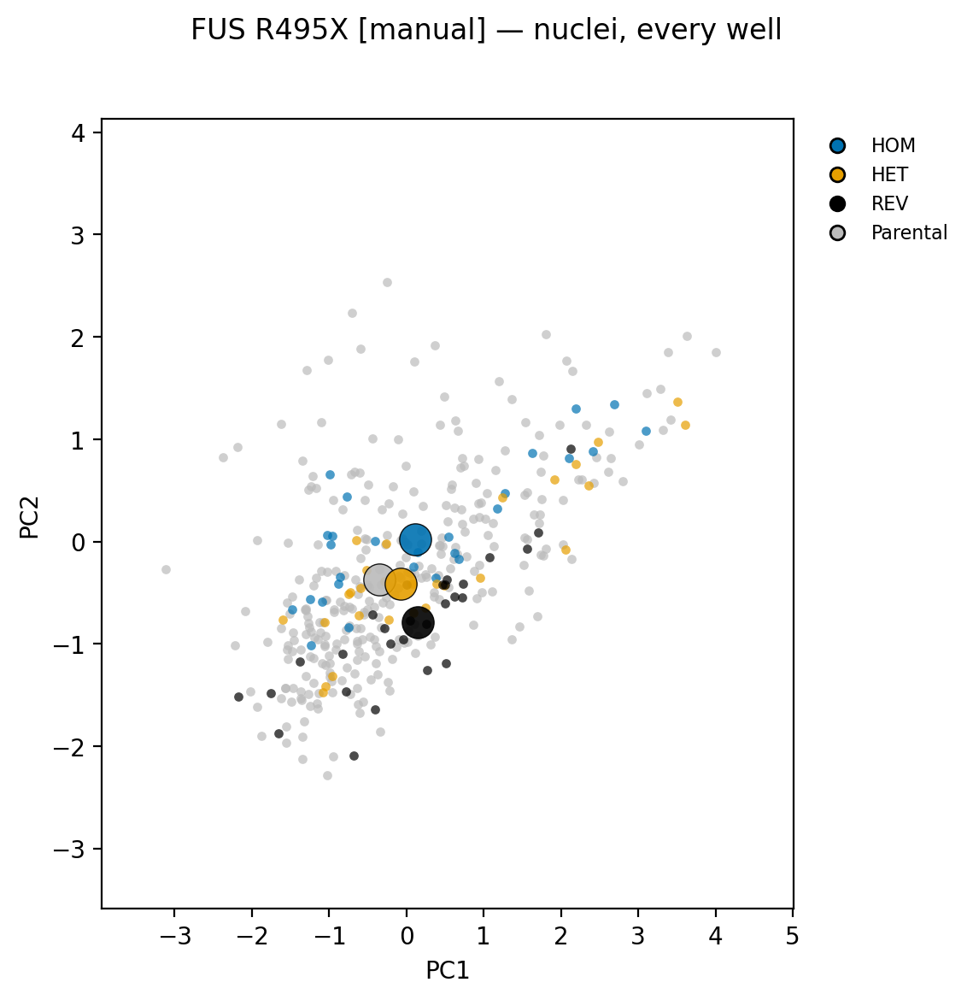

...

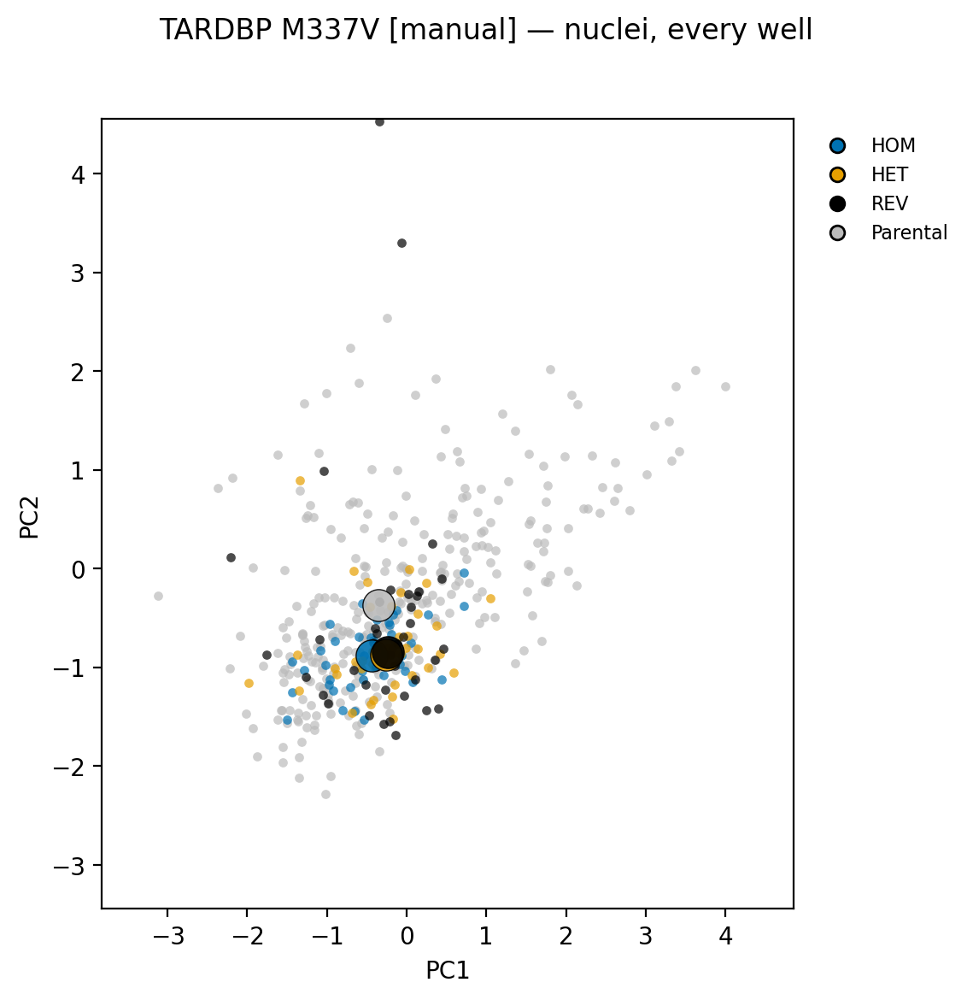

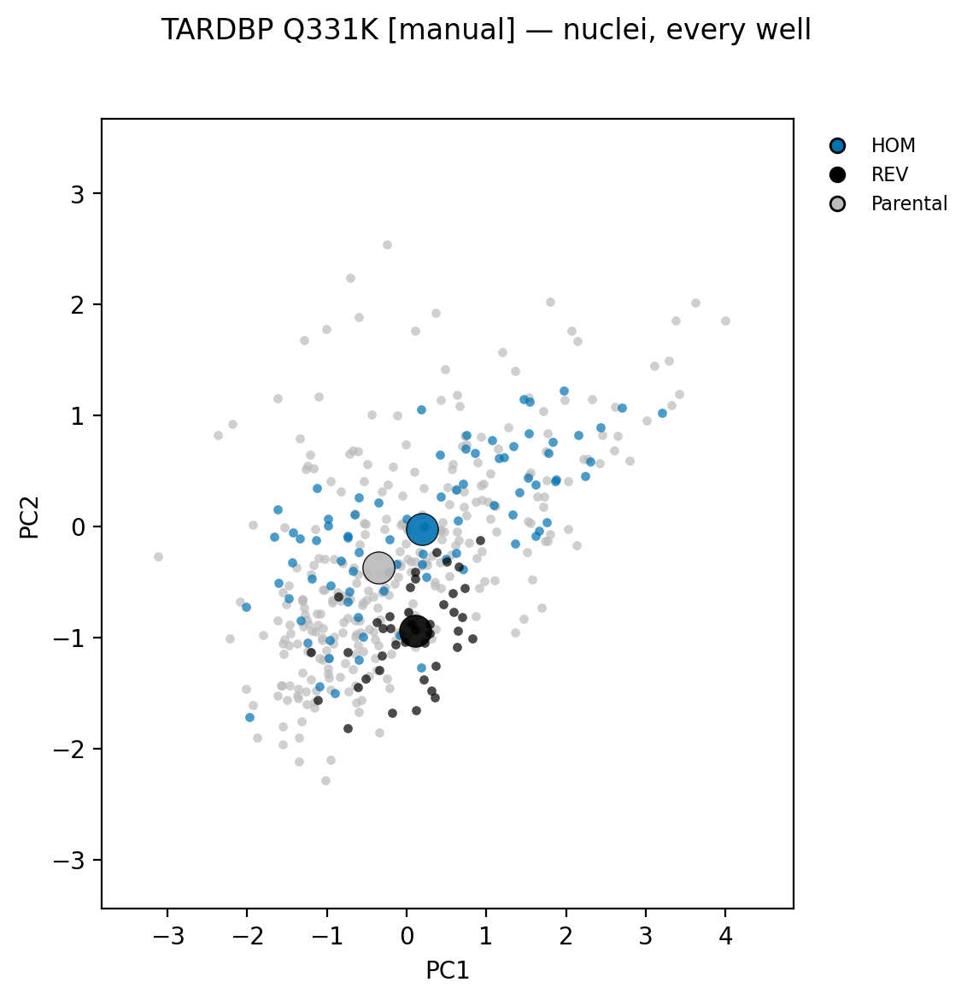

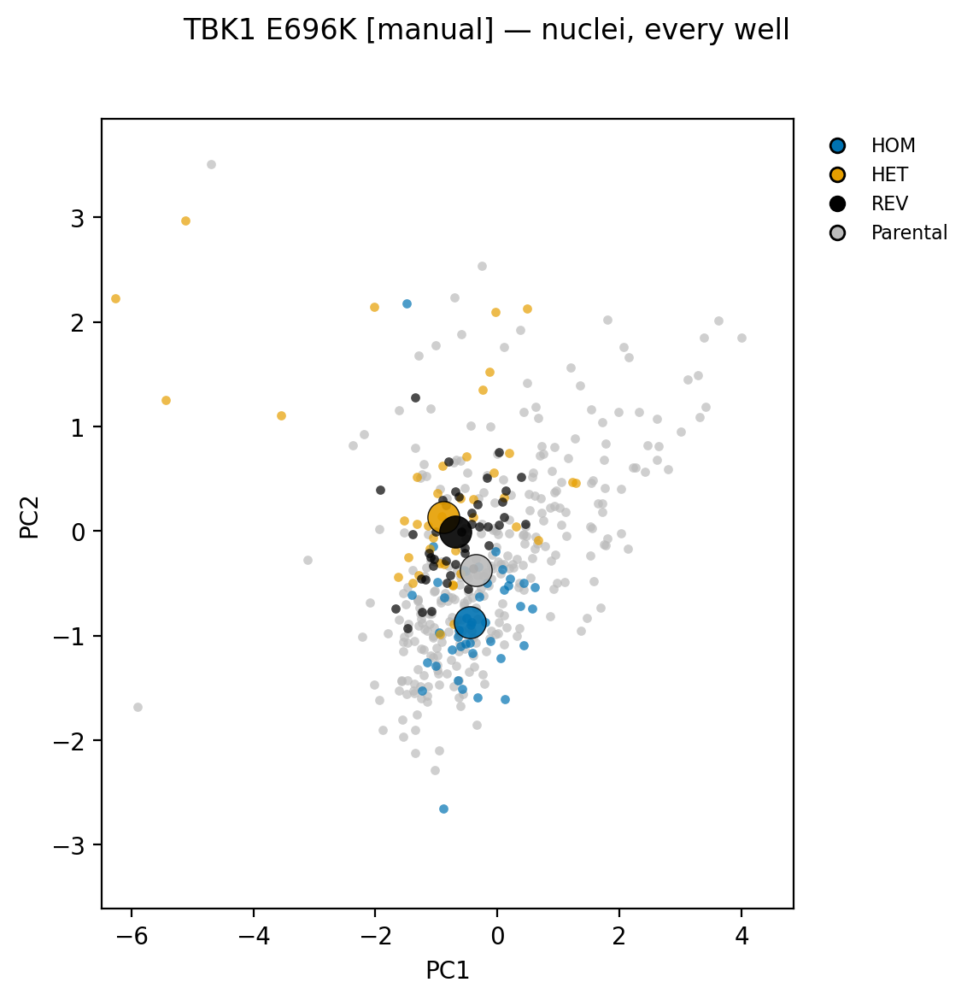

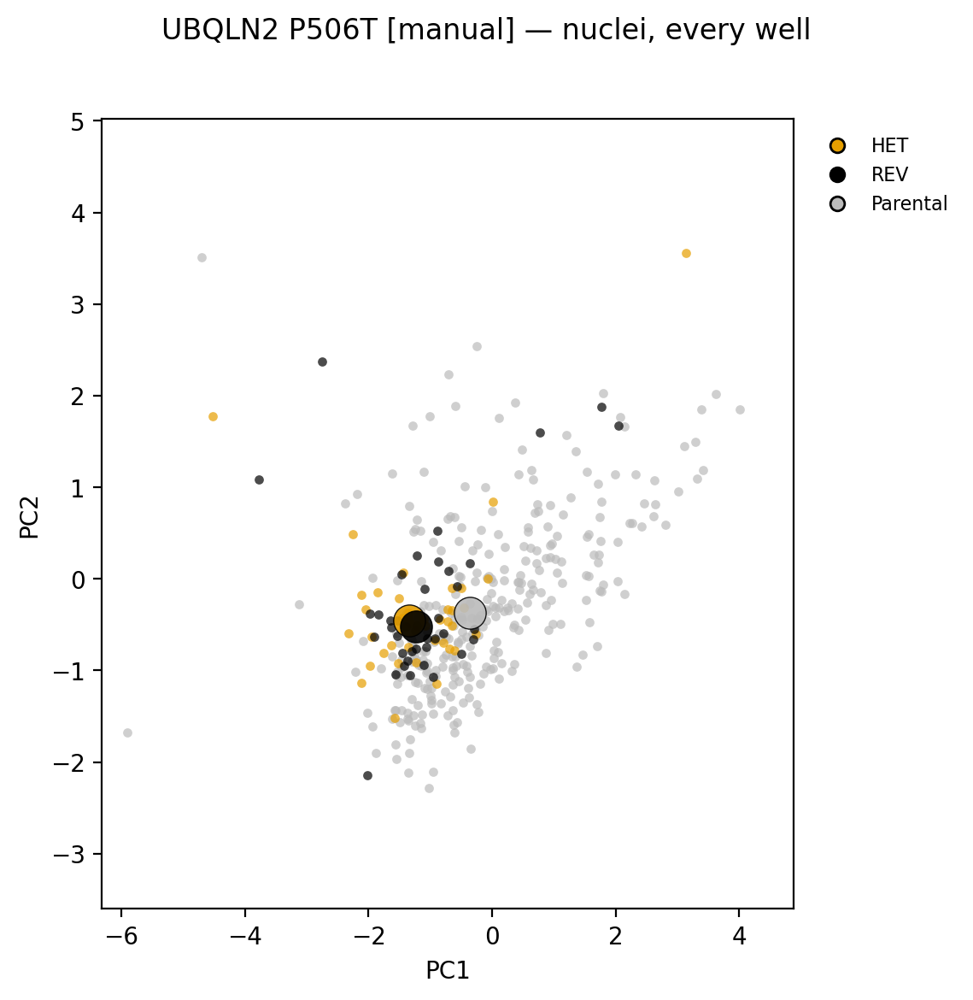

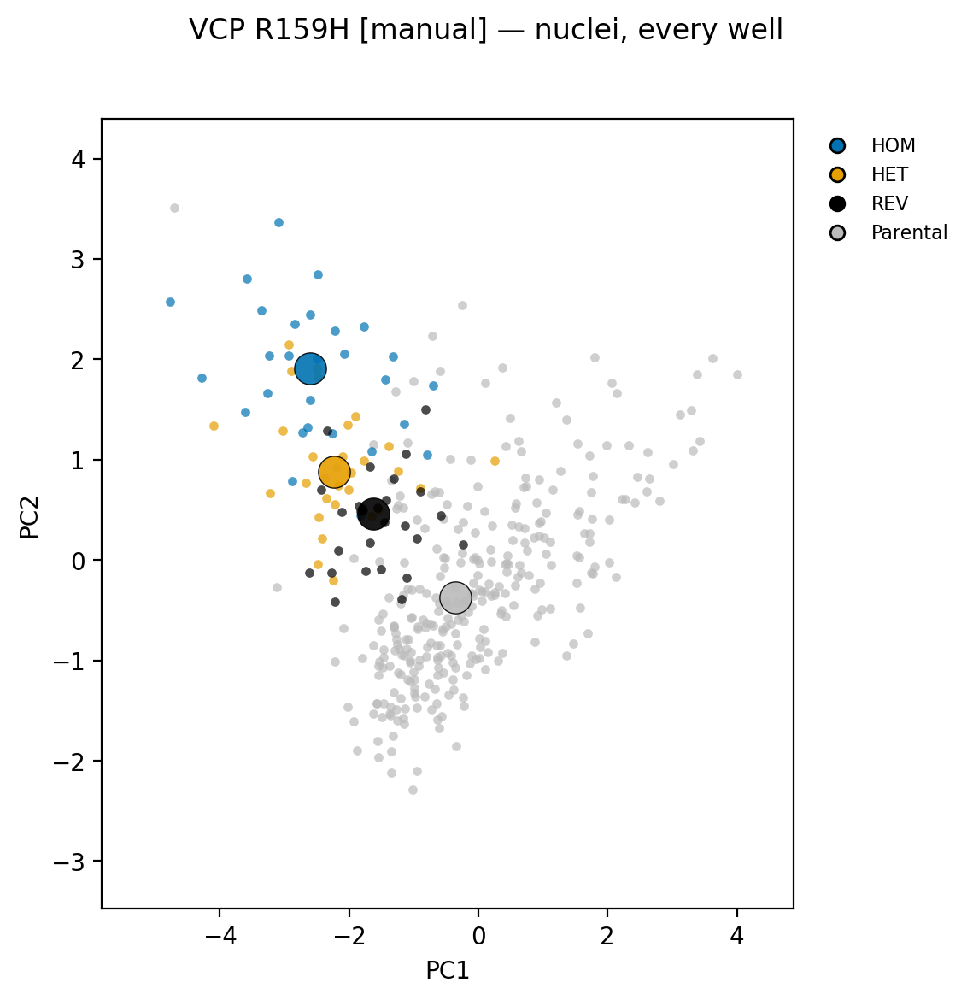


AUTOMATED (4154 wells)


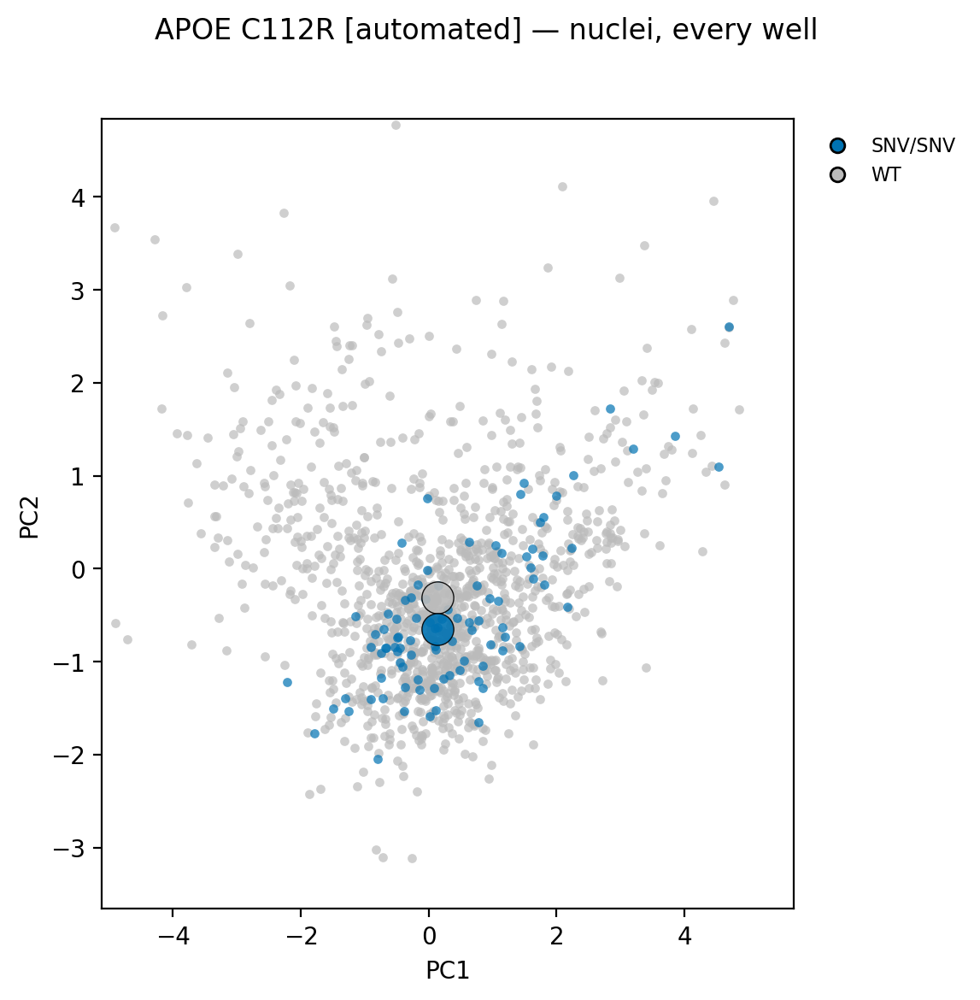

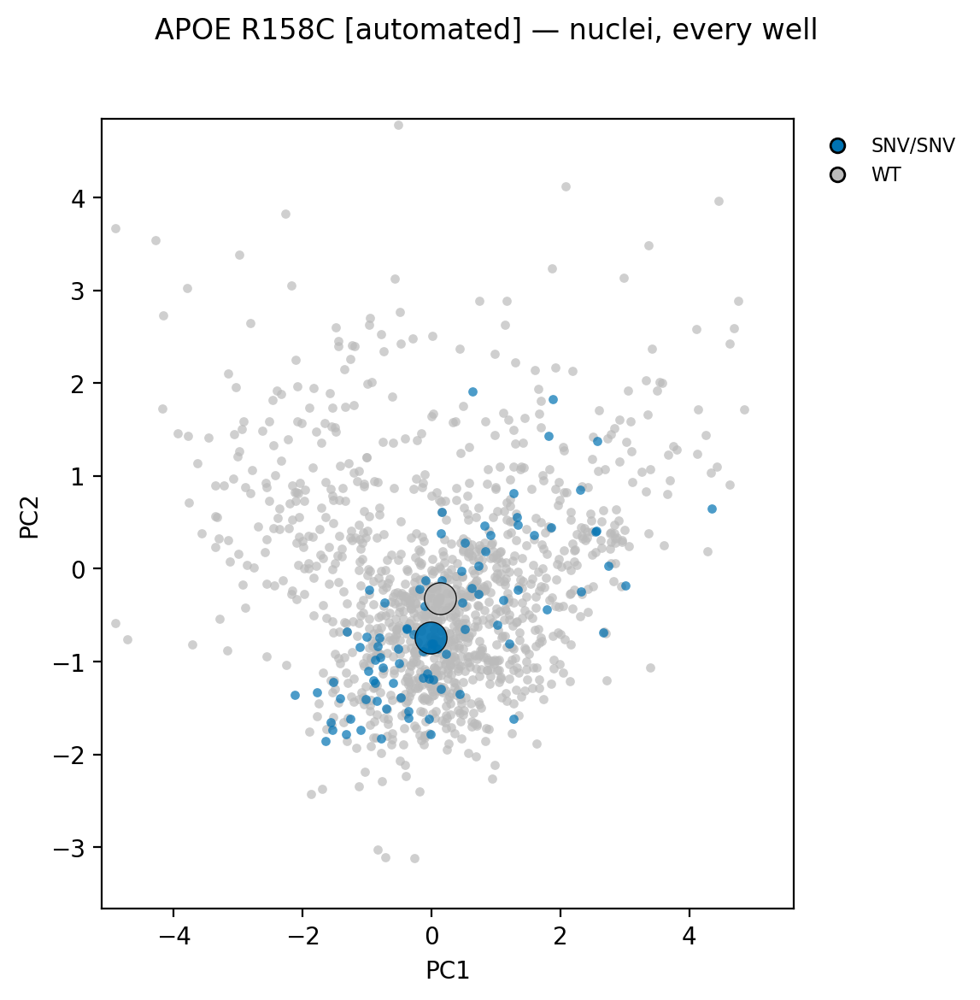

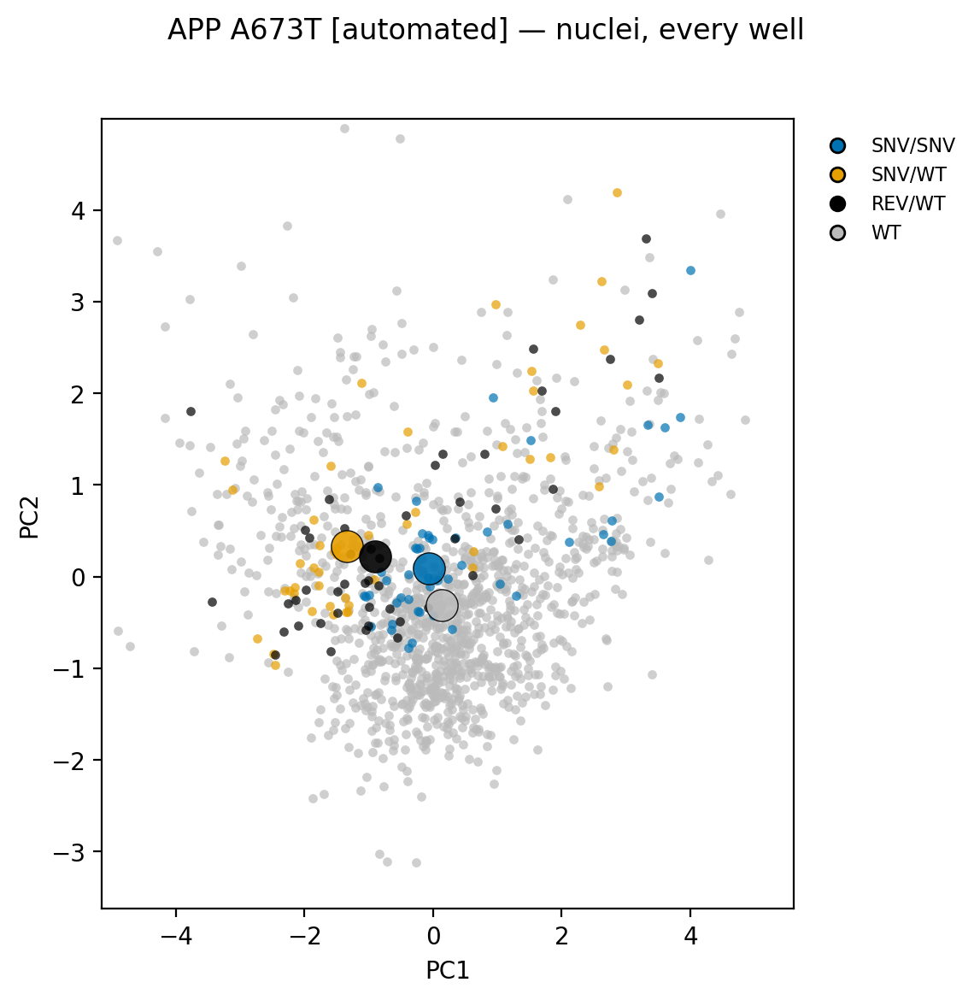

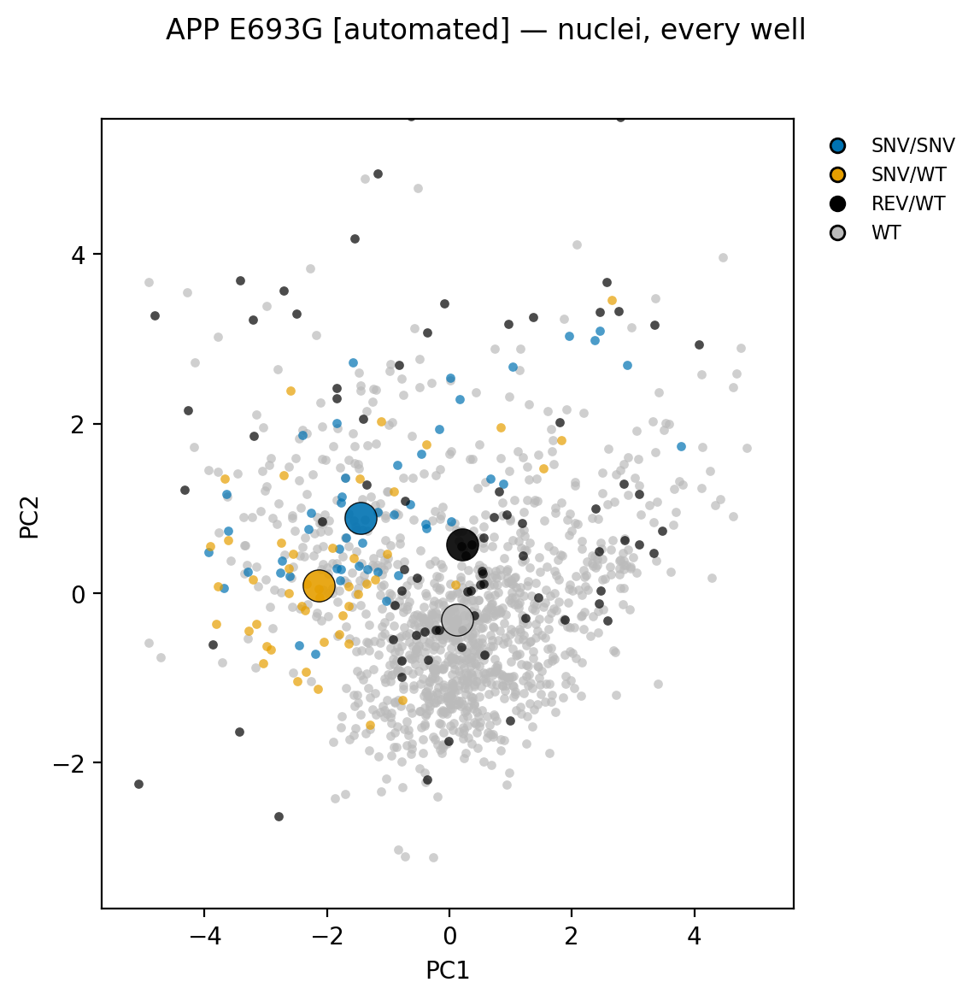

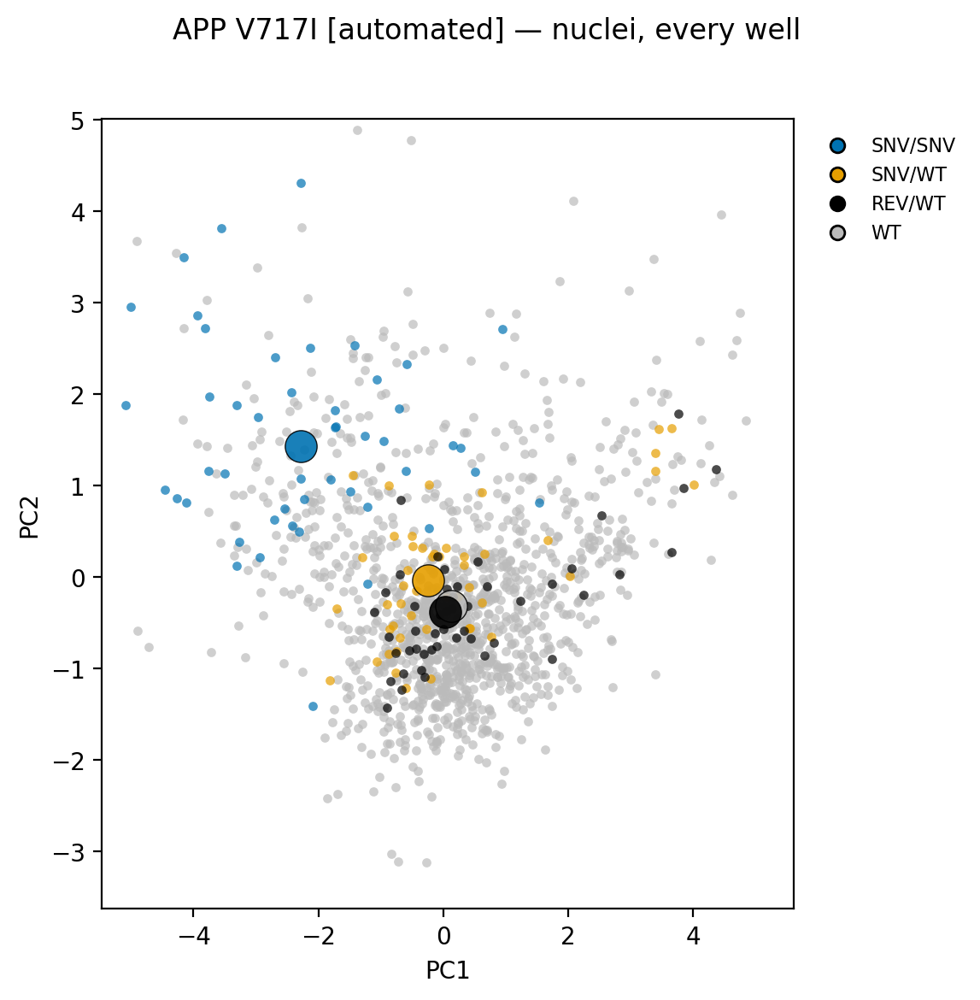

...

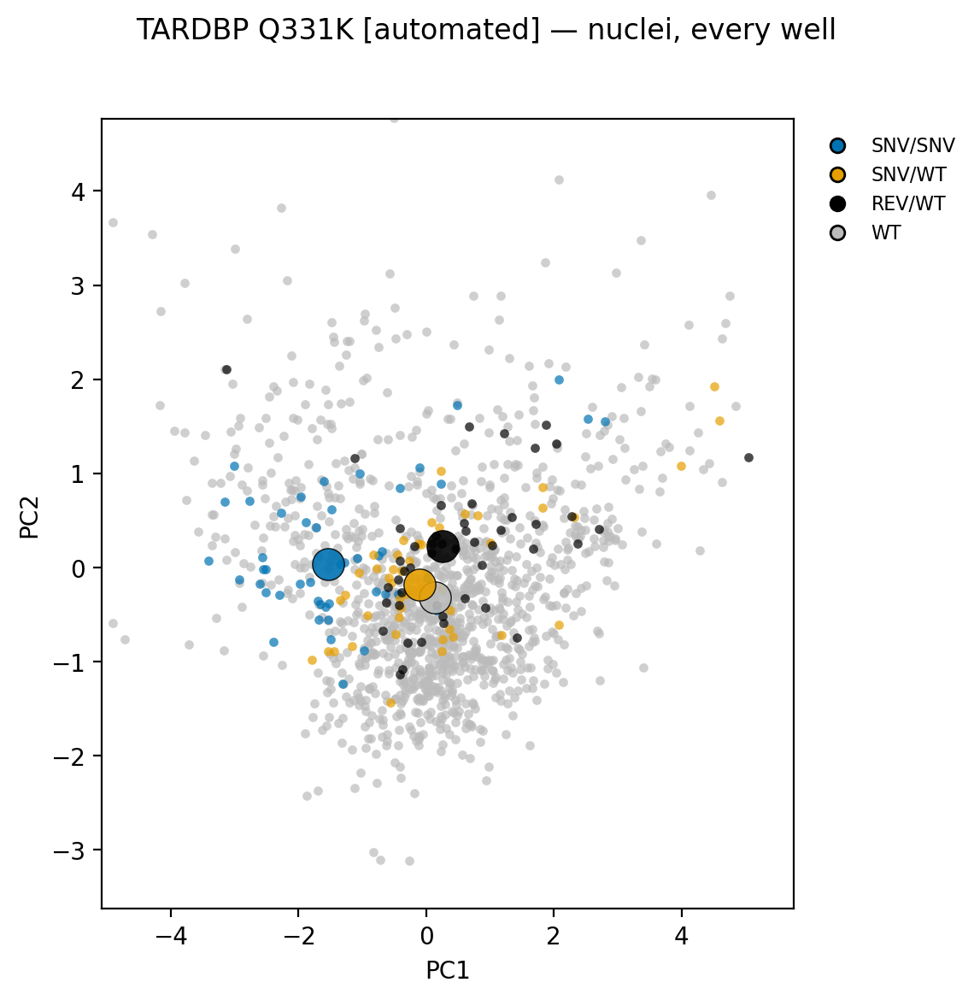

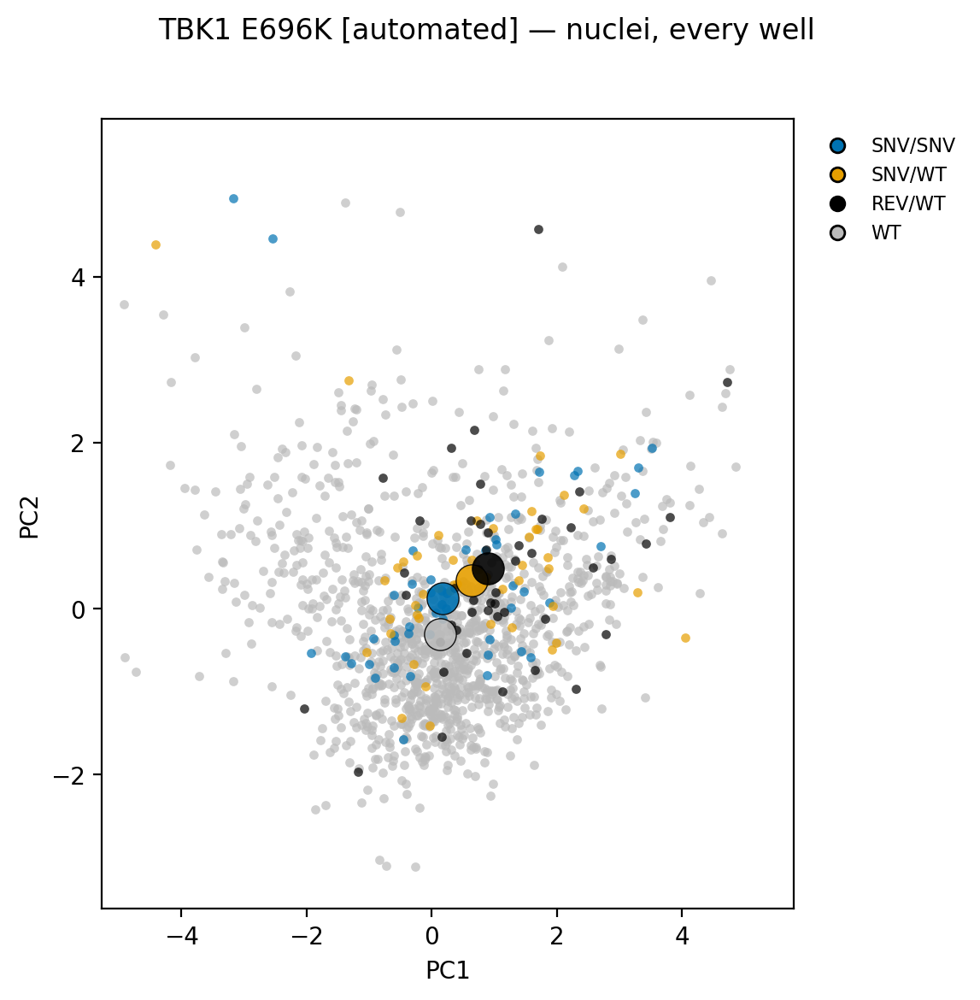

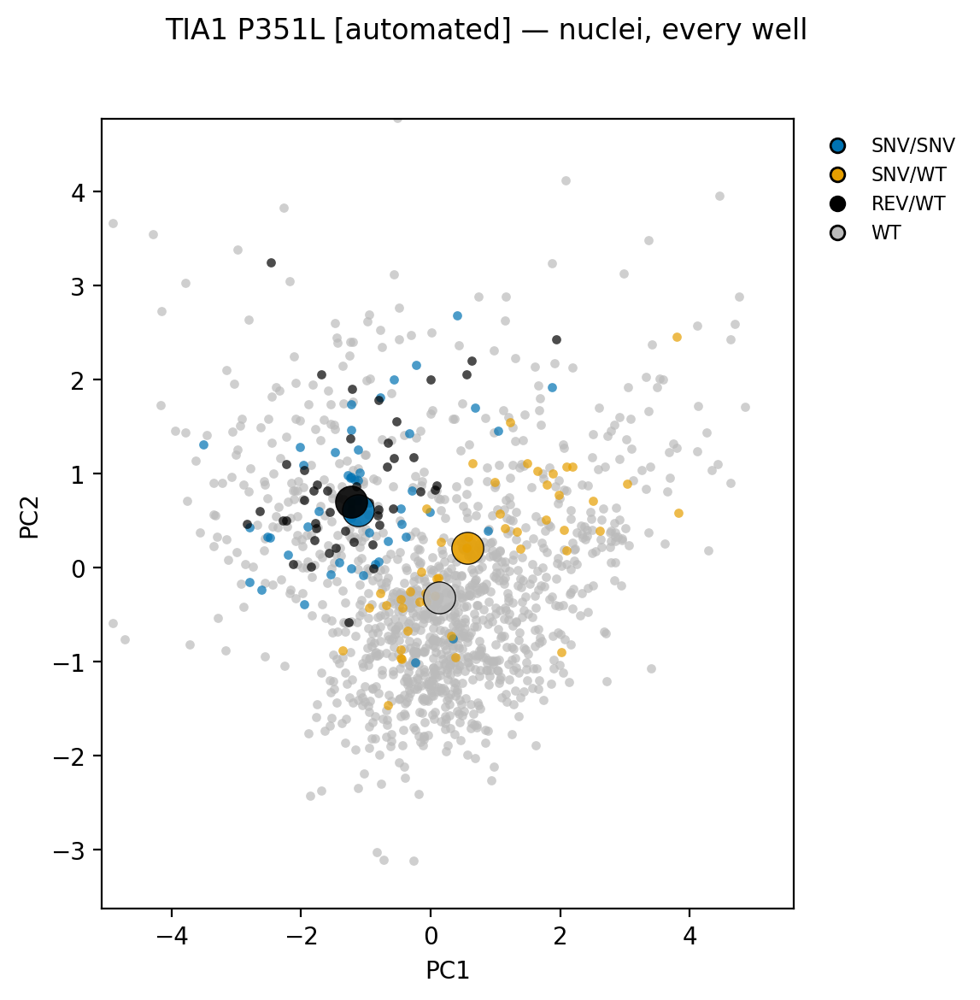

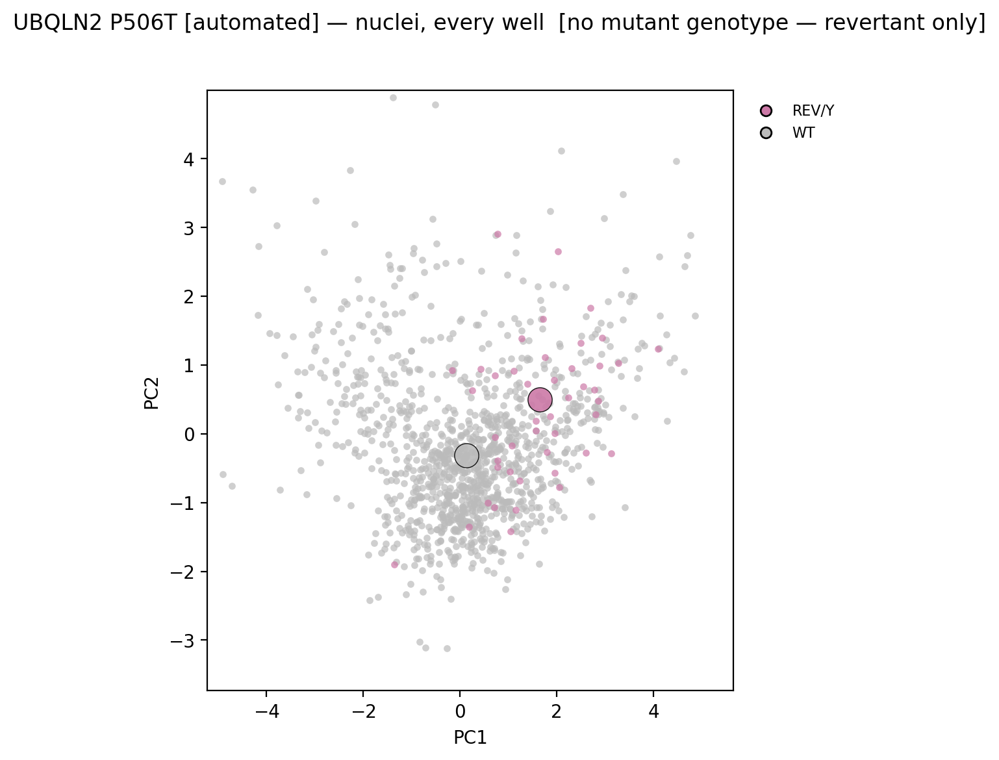

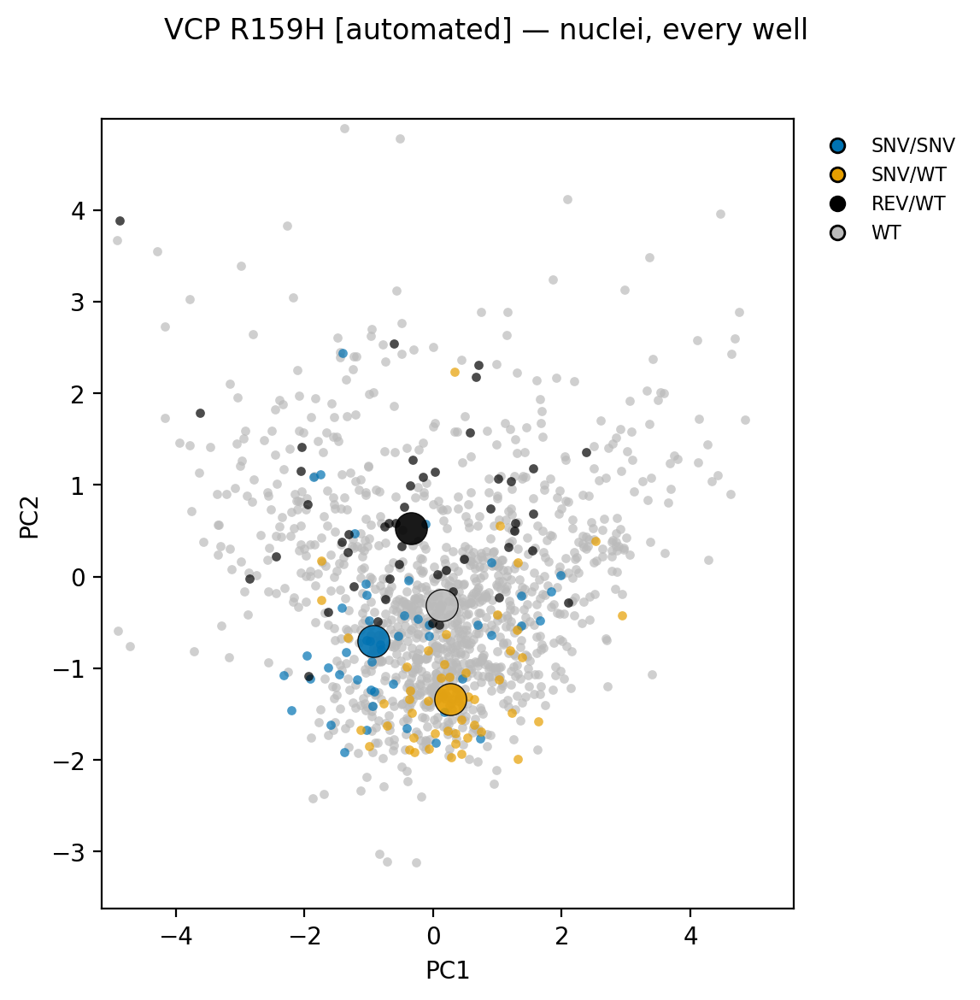

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ==========================================================================
# Prep split
# ==========================================================================
PREP_COL = "Source"          # column tagging each well's prep
AUTOMATED_VAL = "automated"
MANUAL_VAL = "manual"

# ==========================================================================
# Group-specific schemes
# ==========================================================================
# --- Manual: parental by Genotype_Name == "Parental"; genotype is the trailing
#     token of Genotype_Name (HOM / HET / REV). -----------------------------
MANUAL_PARENTAL_NAME = "Parental"
MANUAL_COLORS = {
    "Parental": "#BBBBBB", "HET": "#E69F00", "HOM": "#0072B2",
    "REV": "#000000", "OTHER": "#F0E442",
}
MANUAL_ORDER = ["HOM", "HET", "REV", "Parental"]
MANUAL_PARENTAL_KEY = "Parental"

def _manual_is_parental(df):
    return (df["Genotype_Name"].astype(str).str.strip().str.upper()
            == MANUAL_PARENTAL_NAME.upper())

def _manual_color_key(df):
    name = df["Genotype_Name"].astype(str).str.strip()
    zyg = name.str.split().str[-1].str.upper()        # HOM / HET / REV
    return np.where(_manual_is_parental(df), MANUAL_PARENTAL_KEY, zyg)

def _manual_has_mutant(nonpar_keys):
    return nonpar_keys.isin(["HOM", "HET"]).any()

# --- Automated: parental by Gene == "KOLF2.1J"; genotype from the Genotype
#     column (SNV/SNV, SNV/WT, SNV/Y, ...). ---------------------------------
AUTO_WT_GENE = "KOLF2.1J"
AUTO_COLORS = {
    "WT": "#BBBBBB", "SNV/WT": "#E69F00", "SNV/SNV": "#0072B2",
    "REV/WT": "#000000", "SNV/Y": "#009E73", "REV/Y": "#CC79A7",
    "OTHER": "#F0E442",
}
AUTO_ORDER = ["SNV/SNV", "SNV/WT", "SNV/Y", "REV/WT", "REV/Y", "WT"]
AUTO_PARENTAL_KEY = "WT"

def _auto_is_parental(df):
    return (df["Gene"].astype(str).str.strip().str.upper()
            == AUTO_WT_GENE.upper())

def _auto_color_key(df):
    return np.where(_auto_is_parental(df), AUTO_PARENTAL_KEY,
                    df["Genotype"].astype(str).str.strip())

def _auto_has_mutant(nonwt_keys):
    return nonwt_keys.str.startswith("SNV").any()

SCHEMES = {
    "manual": {
        "label": "manual", "is_parental": _manual_is_parental,
        "color_key": _manual_color_key, "colors": MANUAL_COLORS,
        "order": MANUAL_ORDER, "parental_key": MANUAL_PARENTAL_KEY,
        "has_mutant": _manual_has_mutant,
    },
    "automated": {
        "label": "automated", "is_parental": _auto_is_parental,
        "color_key": _auto_color_key, "colors": AUTO_COLORS,
        "order": AUTO_ORDER, "parental_key": AUTO_PARENTAL_KEY,
        "has_mutant": _auto_has_mutant,
    },
}


# ==========================================================================
# Figure: single-panel PCA for one allele (nucleus-level, no faceting)
# ==========================================================================
def variant_pca(
    df, gene, variant, scheme, pcx="PC1", pcy="PC2", title=None, pad=1.5,
    parental=None, s=15, alpha=0.7, s_centroid=180, figsize=(6, 6),
):
    """Single PCA panel for one (gene, variant), using `scheme` for color keys,
    palette, and ordering. `parental` is the pooled parental reference."""
    colors = scheme["colors"]
    order = scheme["order"]
    par_key = scheme["parental_key"]

    src = df[(df["Gene"] == gene) & (df["Variant"] == variant)].copy()
    if parental is not None and not parental.empty:
        src = pd.concat([src, parental], ignore_index=True)
    if src.empty:
        print(f"[skip] ({scheme['label']}) no rows for {gene} {variant}")
        return None

    src["_ckey"] = scheme["color_key"](src)

    nonpar = src.loc[src["_ckey"] != par_key, "_ckey"]
    has_mutant = scheme["has_mutant"](nonpar)
    mutant_note = "" if has_mutant else "  [no mutant genotype — revertant only]"

    px, py = src[pcx].dropna(), src[pcy].dropna()
    if px.empty or py.empty:
        print(f"[skip] ({scheme['label']}) no finite PC values for {gene} {variant}")
        return None
    x_lo, x_hi = px.quantile(.01) - pad, px.quantile(.99) + pad
    y_lo, y_hi = py.quantile(.01) - pad, py.quantile(.99) + pad

    all_keys = list(pd.unique(src["_ckey"]))
    unknown = [k for k in all_keys if k not in colors]
    if unknown:
        print(f"[warning] ({scheme['label']}) {gene} {variant}: genotype(s) "
              f"not in palette, drawn as OTHER: {unknown}")
    keys_present = ([k for k in order if k in all_keys]
                    + [k for k in all_keys if k not in order])
    draw_order = ([k for k in keys_present if k == par_key]
                  + [k for k in keys_present if k != par_key])

    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.80)

    for k in draw_order:                        # clouds: parental bottom
        gg = src[src["_ckey"] == k]
        ax.scatter(gg[pcx], gg[pcy], s=s, alpha=alpha,
                   color=colors.get(k, colors["OTHER"]),
                   linewidths=0, rasterized=True)
    for k in draw_order:                         # centroids
        gg = src[src["_ckey"] == k]
        if gg.empty:
            continue
        ax.scatter(gg[pcx].median(), gg[pcy].median(), s=s_centroid,
                   color=colors.get(k, colors["OTHER"]),
                   edgecolor="k", linewidths=0.5, alpha=0.9, zorder=5)

    ax.set_xlim(x_lo, x_hi); ax.set_ylim(y_lo, y_hi)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)

    handles = [
        Line2D([0], [0], marker="o", linestyle="", markersize=6,
               markerfacecolor=colors.get(k, colors["OTHER"]),
               markeredgecolor="k", label=k)
        for k in keys_present
    ]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
              frameon=False, fontsize=8)

    fig.suptitle((title or f"{gene} {variant} [{scheme['label']}] — nuclei, "
                  f"every well") + mutant_note, y=0.98)
    plt.show()
    return fig


# ==========================================================================
# Driver: run each prep group independently with its own scheme.
# ==========================================================================
def run_group(well_df, scheme):
    print(f"\n{'=' * 60}\n{scheme['label'].upper()} ({len(well_df)} wells)\n{'=' * 60}")

    is_par = scheme["is_parental"](well_df)
    parental_all = well_df[is_par].copy()

    variants = (well_df.loc[~is_par, ["Gene", "Variant"]]
                .dropna().drop_duplicates().sort_values(["Gene", "Variant"]))

    for gene, variant in variants.itertuples(index=False):
        variant_pca(well_df, gene, variant, scheme, parental=parental_all)


well_df = well_level

# Manual-only fixup from the previous manual driver.
well_df.loc[
    well_df["Genotype_Name"].astype(str).str.strip() == "TBK1 E696K HOM",
    "Variant",
] = "E696K"

prep = well_df[PREP_COL].astype(str).str.strip().str.lower()

run_group(well_df[prep == MANUAL_VAL.lower()].copy(),    SCHEMES["manual"])
run_group(well_df[prep == AUTOMATED_VAL.lower()].copy(), SCHEMES["automated"])

## Automated analysis
### Feature assessment and loadings

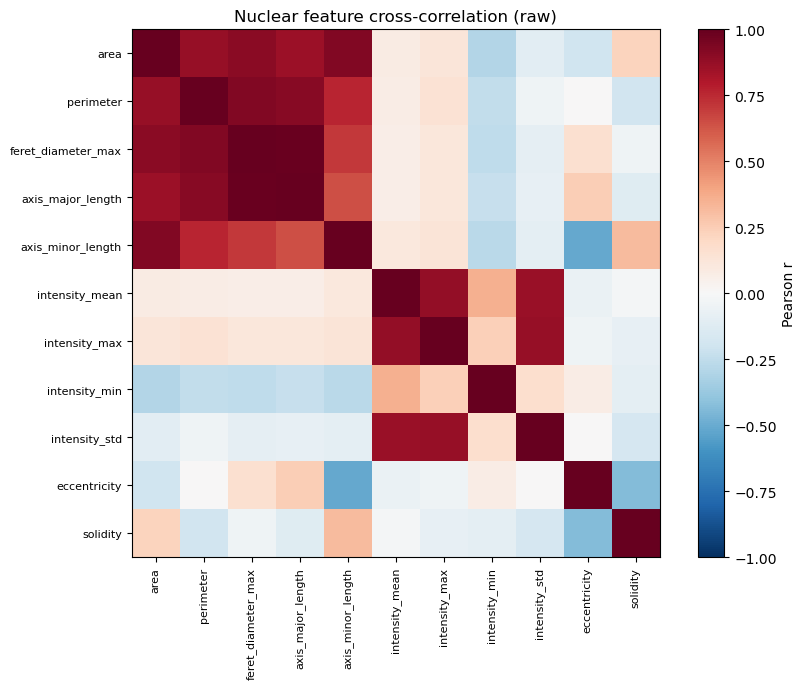

Highly correlated pairs (|r| > 0.9):
  +0.987  feret_diameter_max     axis_major_length
  +0.925  area                   axis_minor_length
  +0.924  perimeter              feret_diameter_max
  +0.907  perimeter              axis_major_length
  +0.900  area                   feret_diameter_max
[full] using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']
[full] dropped 0 rows with NaN/inf; 589864 remain
[full] EVR: [0.399 0.313 0.158 0.107 0.018 0.005]
[full] cumulative: [0.399 0.712 0.87  0.976 0.995 1.   ]


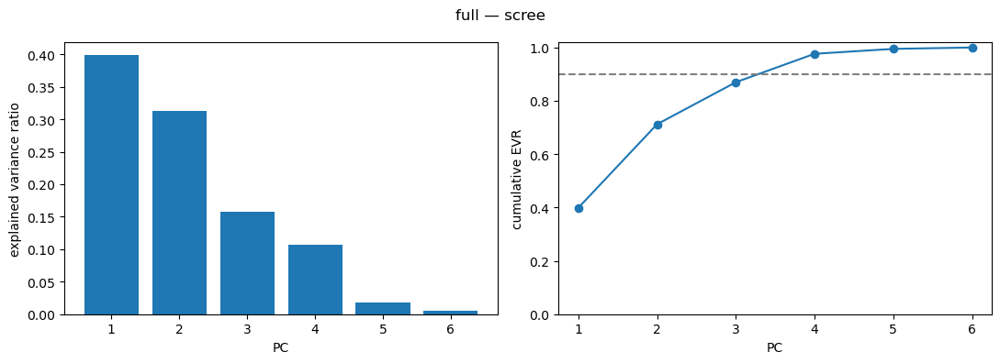

                  PC1    PC2    PC3    PC4    PC5    PC6
area            0.247 -0.014  0.926 -0.254  0.129  0.013
intensity_mean  0.023  0.699  0.135  0.124 -0.691 -0.011
intensity_std  -0.066  0.703 -0.060  0.037  0.704  0.012
eccentricity   -0.600 -0.067  0.235  0.315  0.003  0.694
solidity        0.449 -0.093  0.106  0.875  0.099 -0.054
aspect_ratio    0.611  0.058 -0.233 -0.232 -0.020  0.718


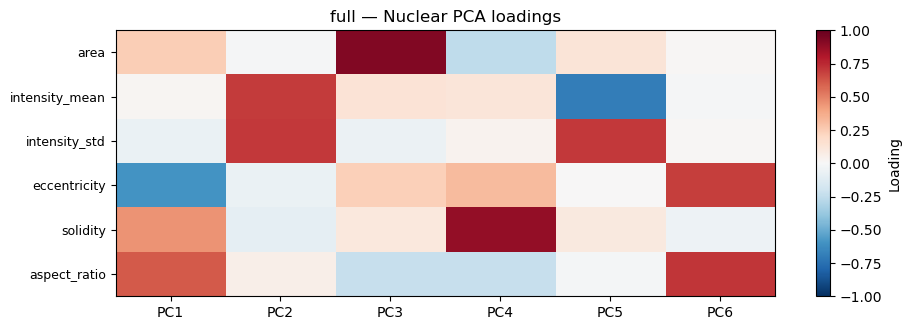

In [16]:
df_auto = df[df["Source"] == "automated"]
feature_correlation(df_auto)
df_auto, pca, FEATURES = fit_pca(df_auto, label="full")

### PCA plots - ROI-level

All 13 iNDI_Plate_ID values have a color.


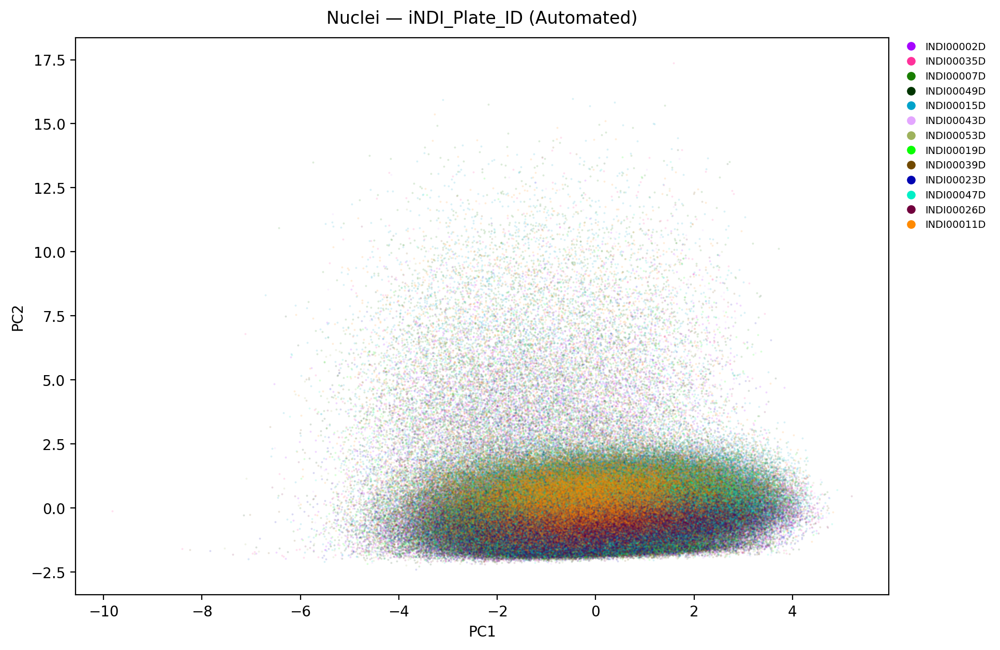

All 4 Batch values have a color.


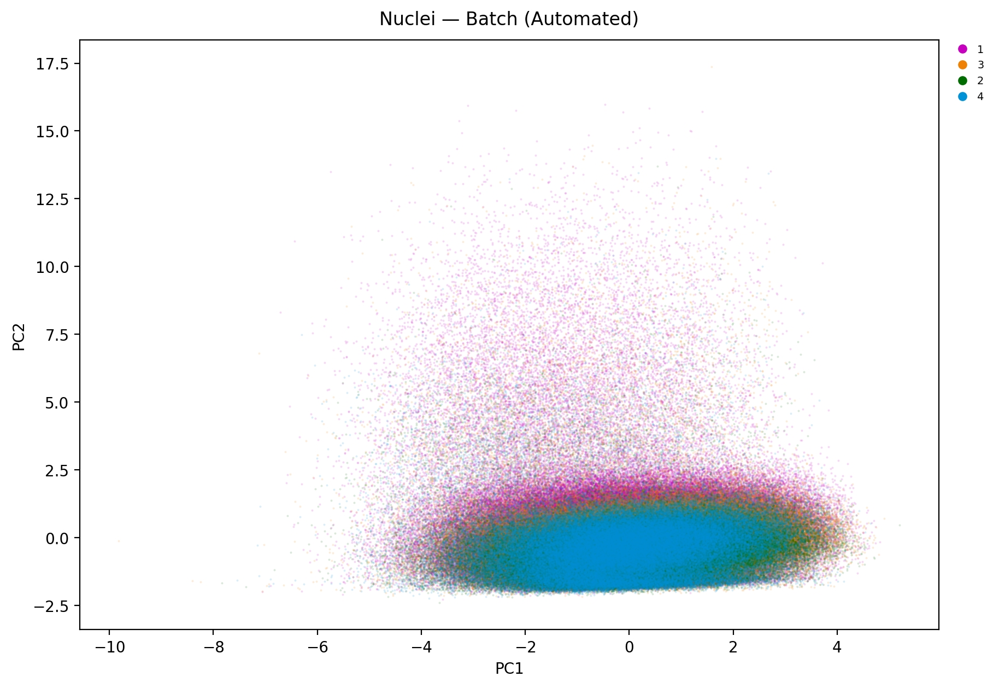

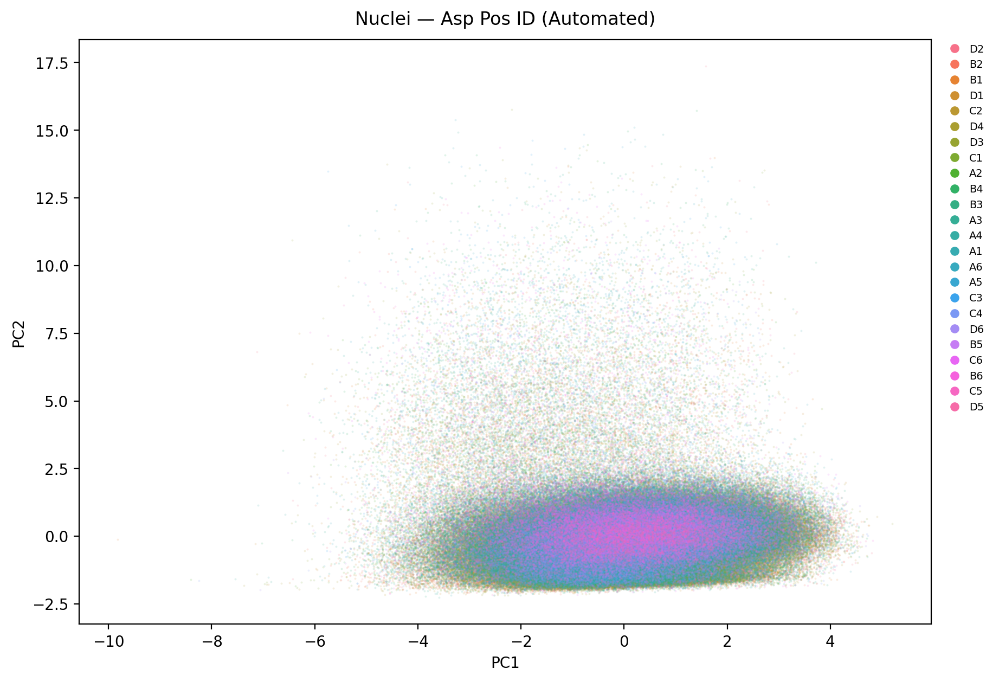

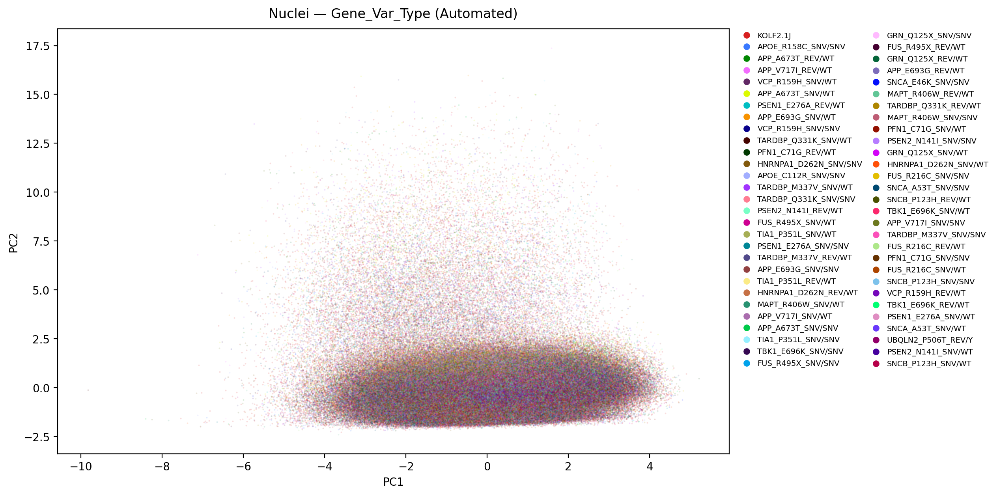

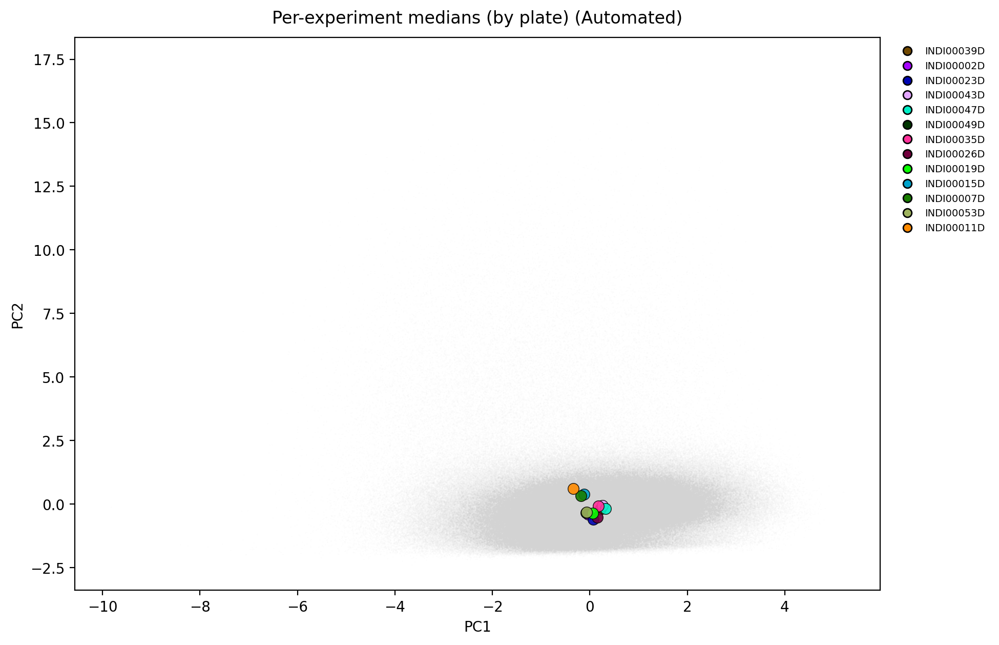

Std of per-experiment centroids (batch magnitude):
PC1    0.192
PC2    0.368
PC3    0.148
dtype: float64


In [17]:
plate_pal = make_palette(df_auto["iNDI_Plate_ID"])
check_palette_coverage(df_auto, "iNDI_Plate_ID", plate_pal)
pca_scatter(df_auto, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Nuclei — iNDI_Plate_ID (Automated)")

batch_palette = make_palette(df_auto["Batch"])
check_palette_coverage(df_auto, "Batch", batch_palette)
pca_scatter(df_auto, "Batch", palette=batch_palette, figsize=(12, 7),title="Nuclei — Batch (Automated)")

pca_scatter(df_auto, "Asp PosID", figsize=(12, 7),title="Nuclei — Asp Pos ID (Automated)")

pca_scatter(df_auto, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2, title="Nuclei — Gene_Var_Type (Automated)")

centroid_overlay(df_auto, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate) (Automated)")
cent = df_auto.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

### PCA plots - well-level

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 125124 rows (13440 images)
[full] well-level: 4154 rows
[full well] using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']
[full well] dropped 0 rows with NaN/inf; 4154 remain
[full well] EVR: [0.419 0.303 0.169 0.077 0.029 0.004]
[full well] cumulative: [0.419 0.722 0.891 0.967 0.996 1.   ]


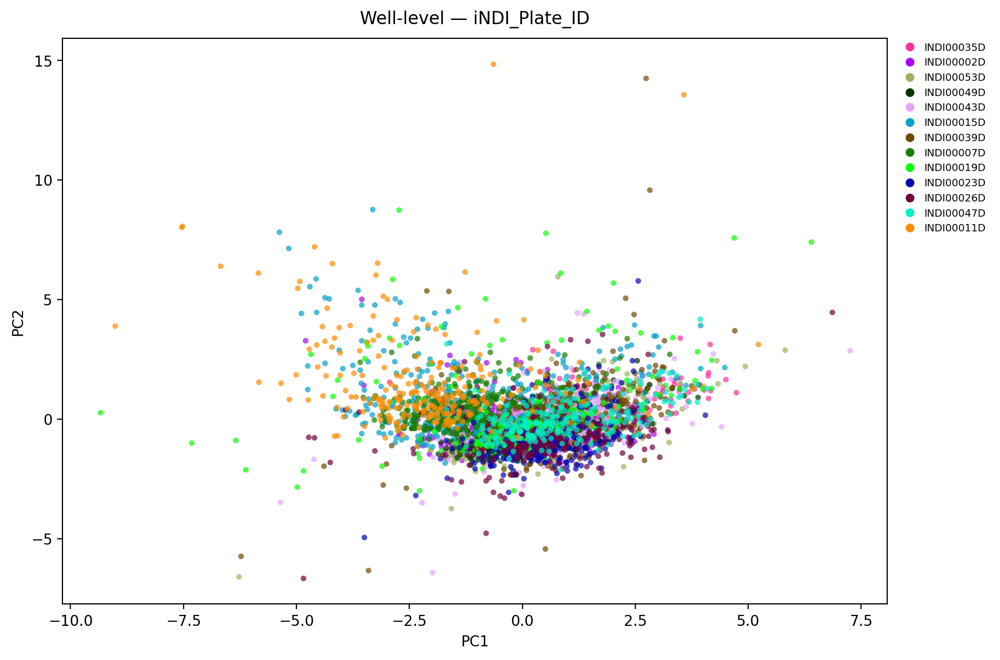

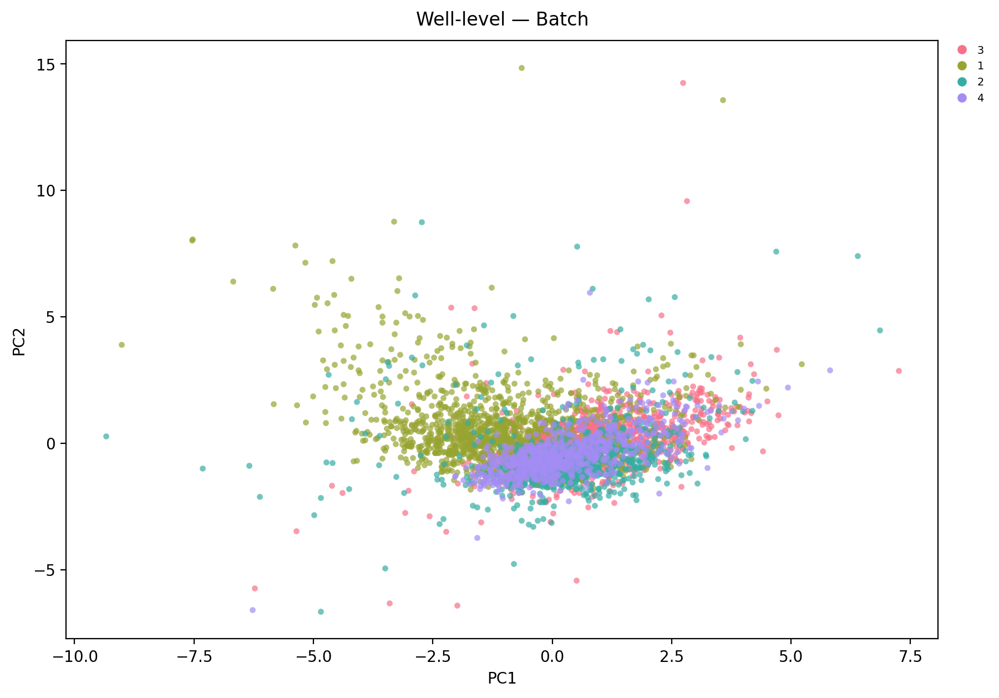

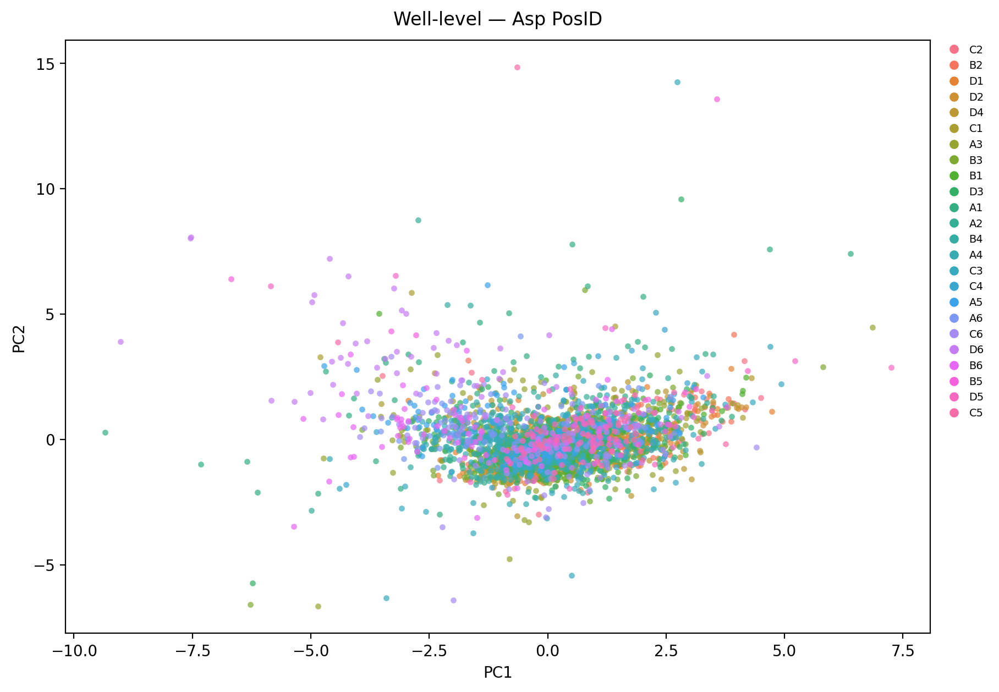

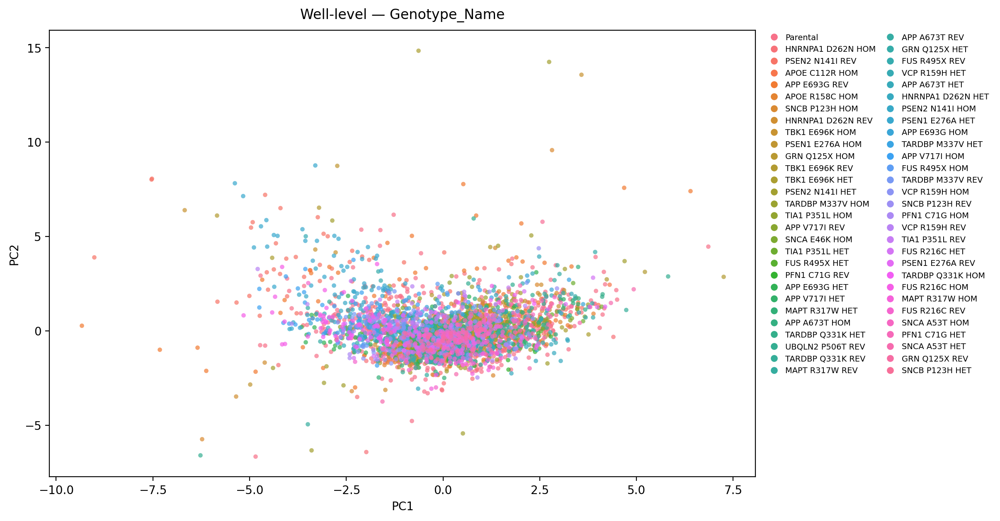

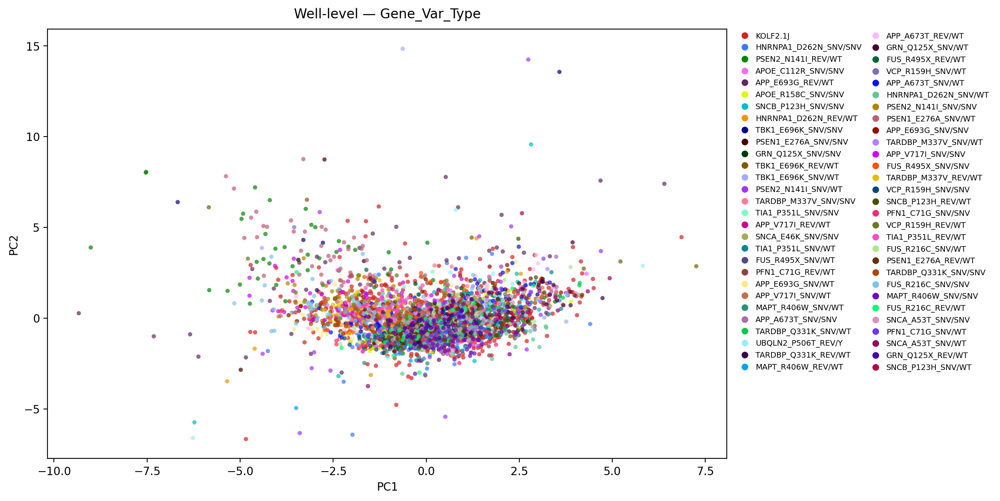

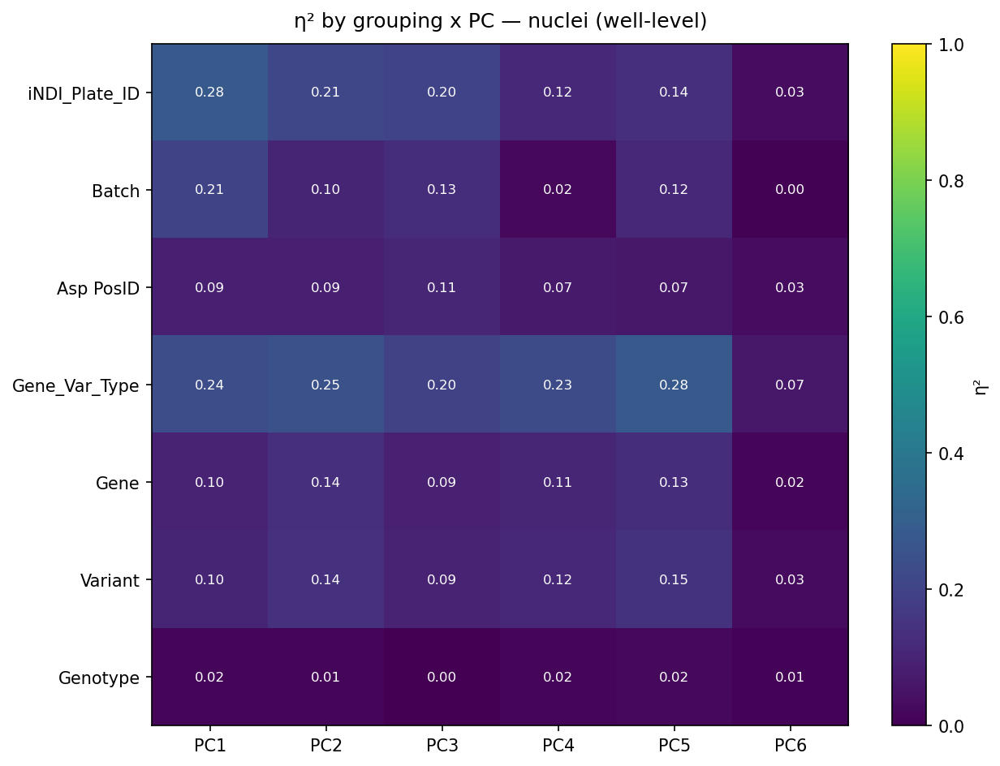

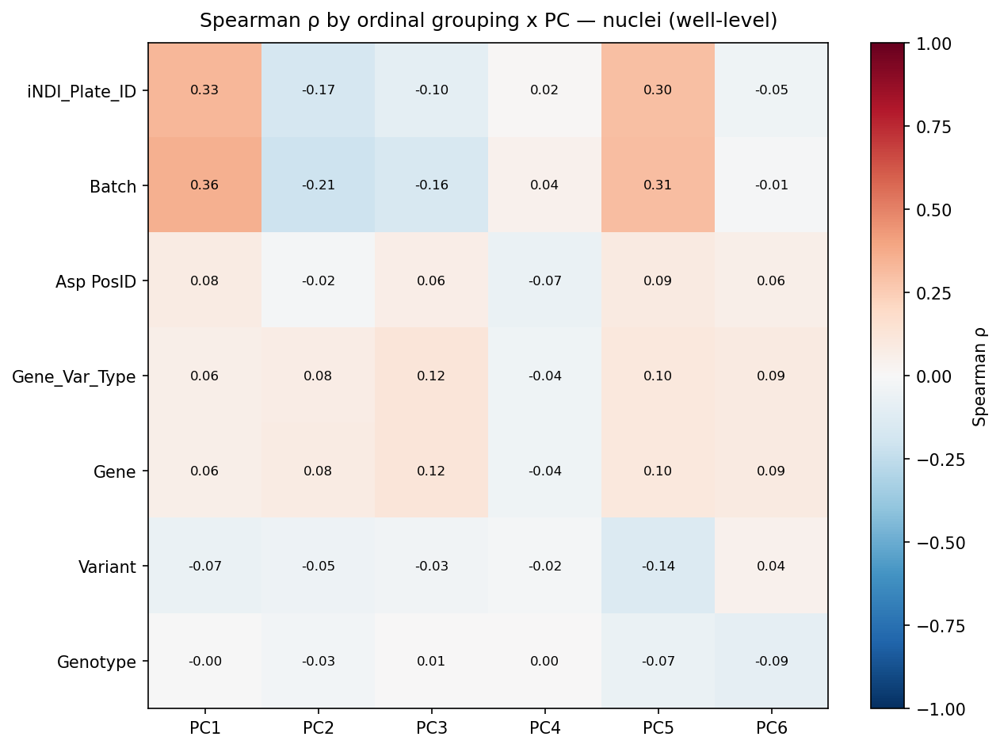

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,0.331660,-0.165171,-0.100937,0.015127,0.303769,-0.045807
Batch,0.358222,-0.209128,-0.159505,0.041349,0.309445,-0.008503
Asp PosID,0.083346,-0.017299,0.064619,-0.065926,0.086494,0.061944
Gene_Var_Type,0.060369,0.077803,0.117765,-0.044797,0.102392,0.087626
Gene,0.060725,0.080500,0.119249,-0.042219,0.104484,0.087492
Variant,-0.067306,-0.051222,-0.033685,-0.018892,-0.136157,0.043614
Genotype,-0.000823,-0.030584,0.007595,0.000466,-0.065270,-0.086745


In [18]:
well_level = aggregate_wells(df_auto, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_shuf["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Batch", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Batch")
pca_scatter(well_shuf, "Asp PosID", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Asp PosID")
pca_scatter(well_shuf, "Genotype_Name", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Genotype_Name")
pca_scatter(well_shuf, "Gene_Var_Type", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Gene_Var_Type")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"],
            n_pcs=6, title="η² by grouping x PC — nuclei (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — nuclei (well-level)")

## Manual analysis
### Feature assessment and loadings

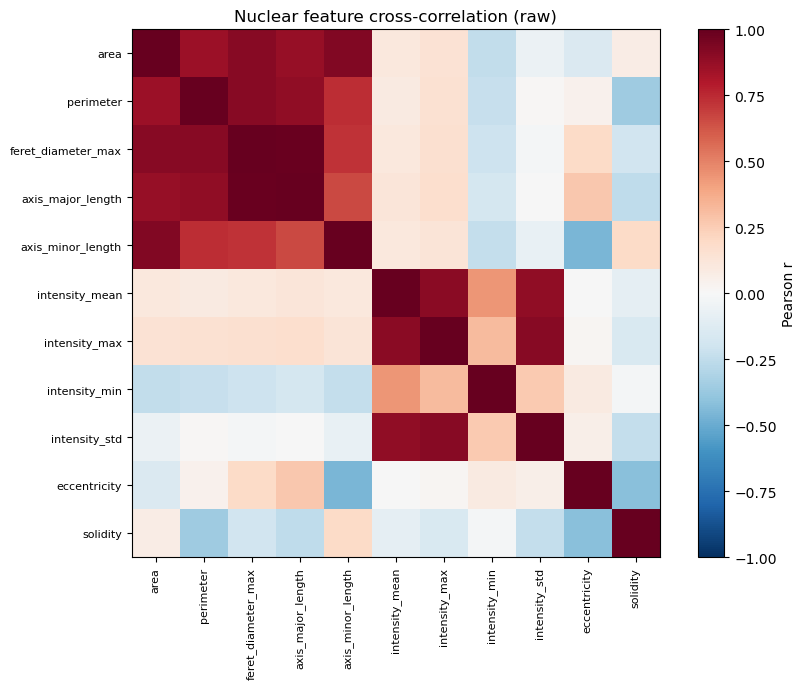

Highly correlated pairs (|r| > 0.9):
  +0.988  feret_diameter_max     axis_major_length
  +0.926  area                   axis_minor_length
  +0.911  perimeter              feret_diameter_max
  +0.909  area                   feret_diameter_max
  +0.907  intensity_max          intensity_std
  +0.901  intensity_mean         intensity_max
[full] using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']
[full] dropped 0 rows with NaN/inf; 456248 remain
[full] EVR: [0.398 0.309 0.163 0.111 0.014 0.005]
[full] cumulative: [0.398 0.707 0.87  0.981 0.995 1.   ]


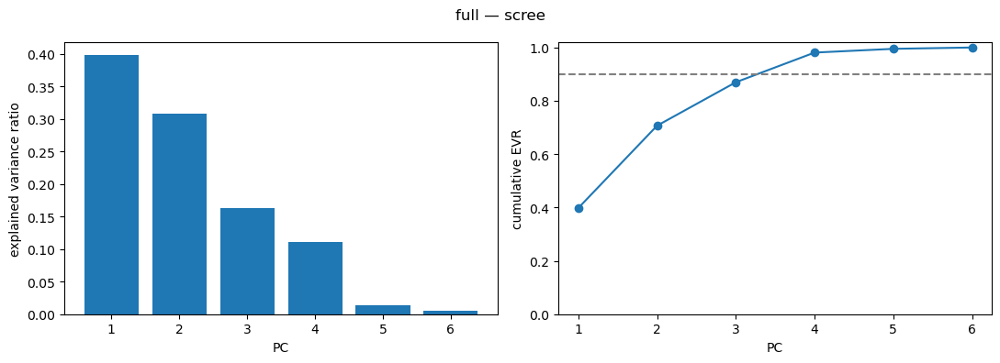

                  PC1    PC2    PC3    PC4    PC5    PC6
area            0.129  0.116  0.977  0.006  0.119  0.016
intensity_mean -0.206  0.672  0.031  0.177 -0.688 -0.013
intensity_std  -0.280  0.639 -0.125  0.013  0.705  0.023
eccentricity   -0.567 -0.260  0.092  0.356 -0.002  0.690
solidity        0.445  0.030 -0.082  0.881  0.121 -0.067
aspect_ratio    0.586  0.241 -0.113 -0.257 -0.025  0.721


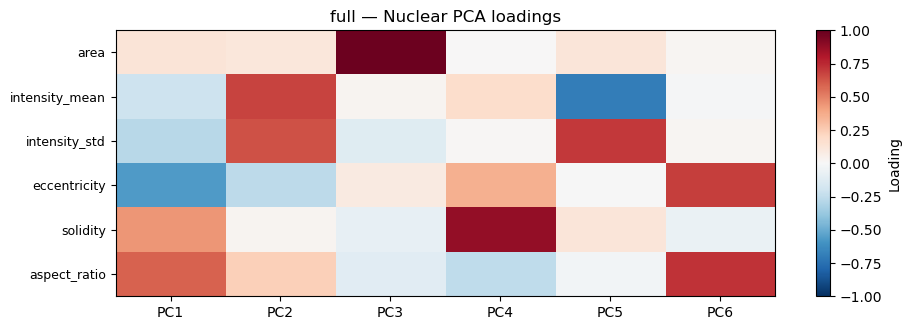

In [19]:
df_manual = df[df["Source"] == "manual"]
feature_correlation(df_manual)
df_manual, pca, FEATURES = fit_pca(df_manual, label="full")

### PCA plots - ROI-level

All 8 iNDI_Plate_ID values have a color.


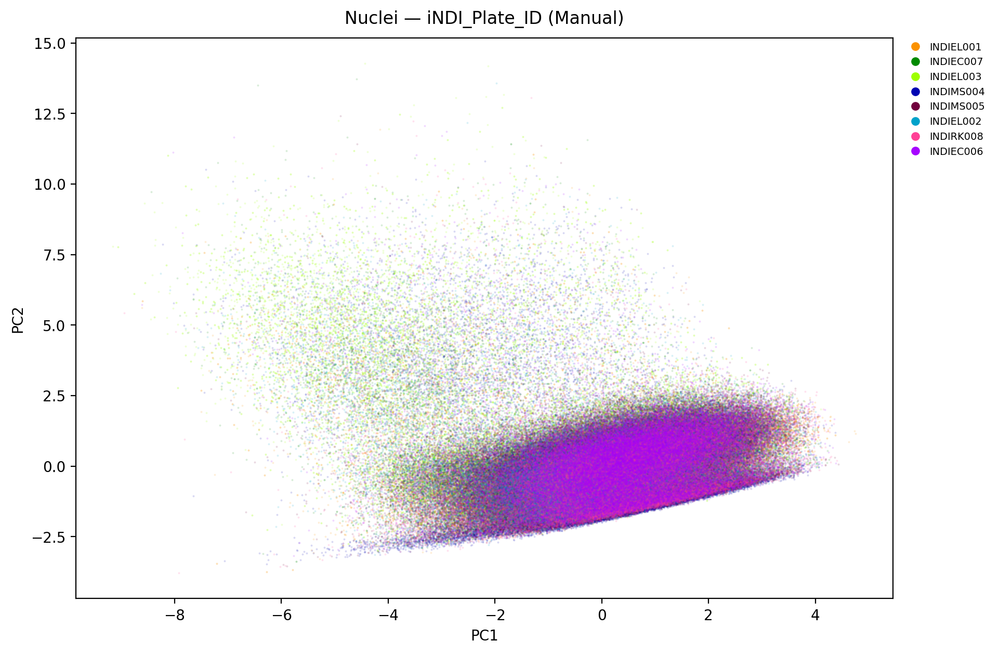

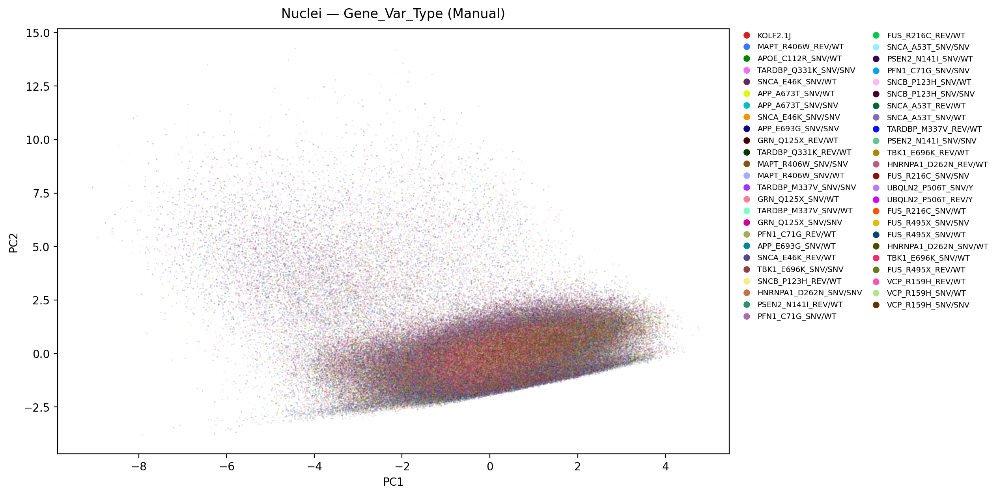

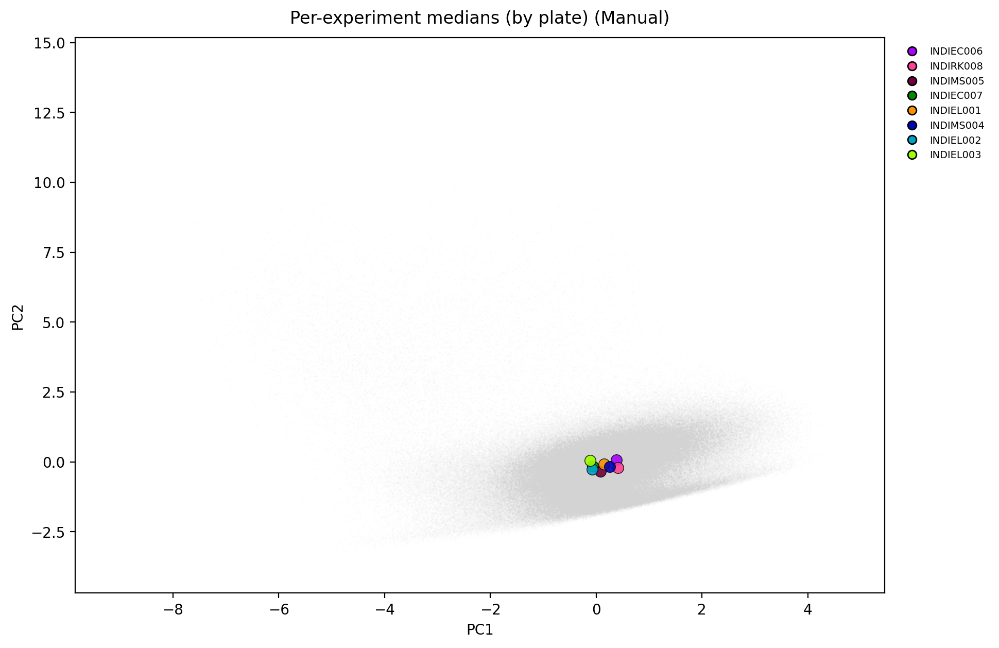

Std of per-experiment centroids (batch magnitude):
PC1    0.205
PC2    0.141
PC3    0.178
dtype: float64


In [20]:
plate_pal = make_palette(df_manual["iNDI_Plate_ID"])
check_palette_coverage(df_manual, "iNDI_Plate_ID", plate_pal)
pca_scatter(df_manual, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Nuclei — iNDI_Plate_ID (Manual)")

pca_scatter(df_manual, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2, title="Nuclei — Gene_Var_Type (Manual)")

centroid_overlay(df_manual, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate) (Manual)")
cent = df_manual.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

### PCA plots - well-level

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 74704 rows (11755 images)
[full] well-level: 2198 rows
[full well] using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']
[full well] dropped 0 rows with NaN/inf; 2198 remain
[full well] EVR: [0.455 0.269 0.126 0.116 0.032 0.002]
[full well] cumulative: [0.455 0.724 0.85  0.966 0.998 1.   ]


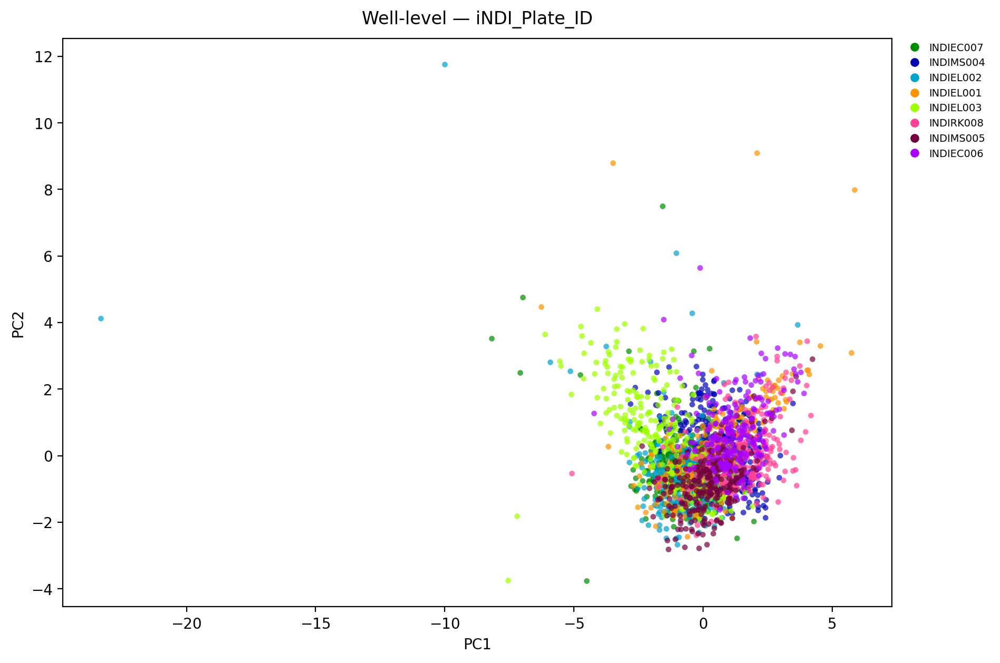

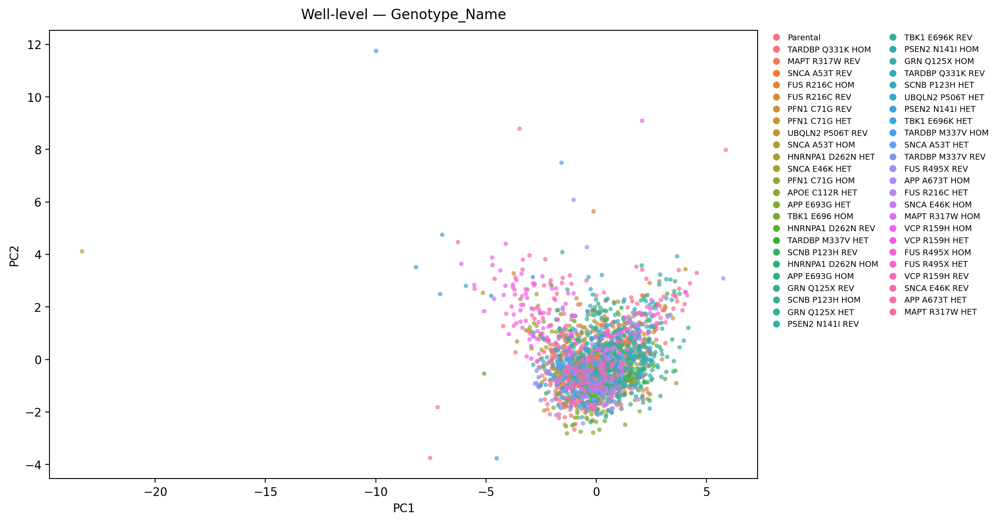

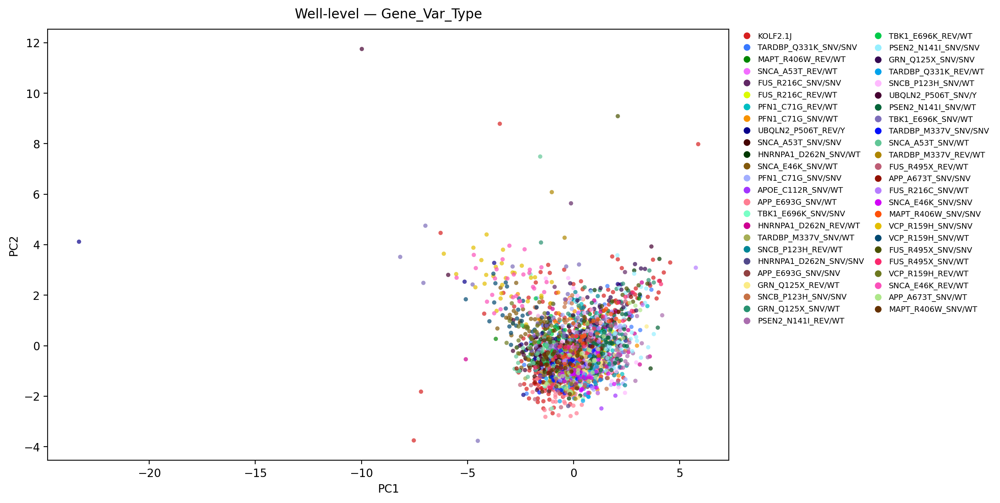

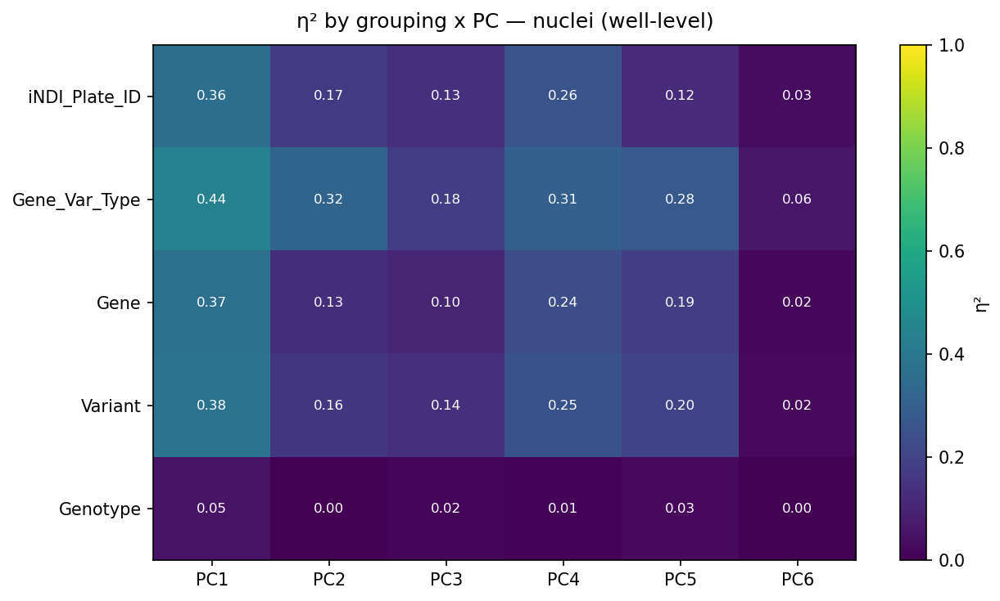

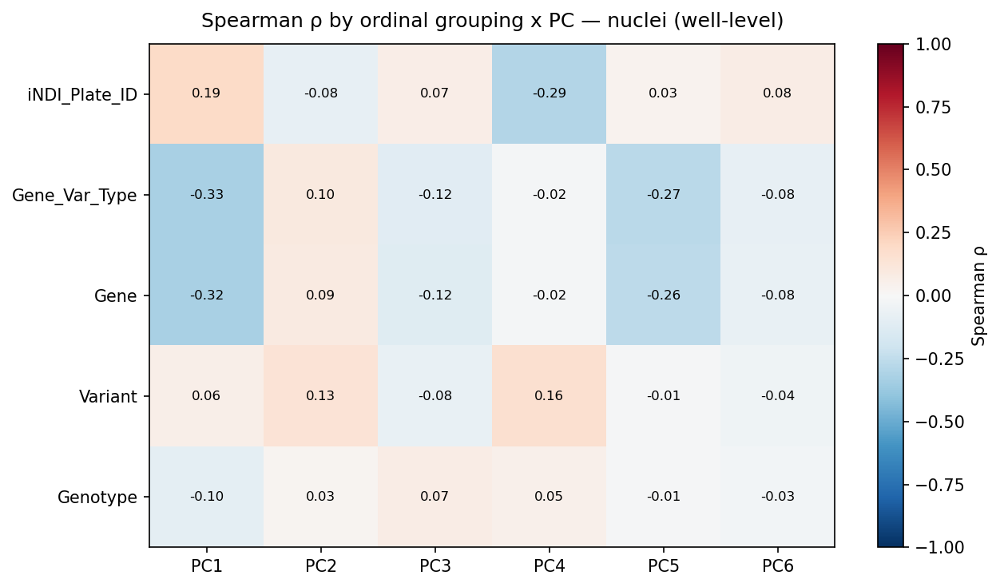

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,0.194932,-0.082538,0.069955,-0.291239,0.033804,0.075289
Gene_Var_Type,-0.325092,0.100536,-0.115670,-0.023102,-0.267605,-0.079039
Gene,-0.322551,0.090771,-0.119222,-0.021989,-0.262195,-0.077146
Variant,0.056824,0.133146,-0.077169,0.157372,-0.014015,-0.041150
Genotype,-0.100487,0.025777,0.074176,0.053235,-0.013406,-0.028139


In [21]:
well_level = aggregate_wells(df_manual, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_level["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Genotype_Name", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Genotype_Name")
pca_scatter(well_shuf, "Gene_Var_Type", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Gene_Var_Type")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Gene_Var_Type", "Gene", "Variant", "Genotype"],
            n_pcs=6, title="η² by grouping x PC — nuclei (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Gene_Var_Type", "Gene", "Variant", "Genotype"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — nuclei (well-level)")

# Parental-only analysis

In [22]:
# filter for parentals
parental        = df[df["Gene_Var_Type"] == "KOLF2.1J"]
parental_auto   = df[(df["Gene_Var_Type"] == "KOLF2.1J") & (df["Source"] == "automated")]
parental_manual = df[(df["Gene_Var_Type"] == "KOLF2.1J") & (df["Source"] == "manual")]

## ROI level analysis
### Feature assessment and PCA loadings


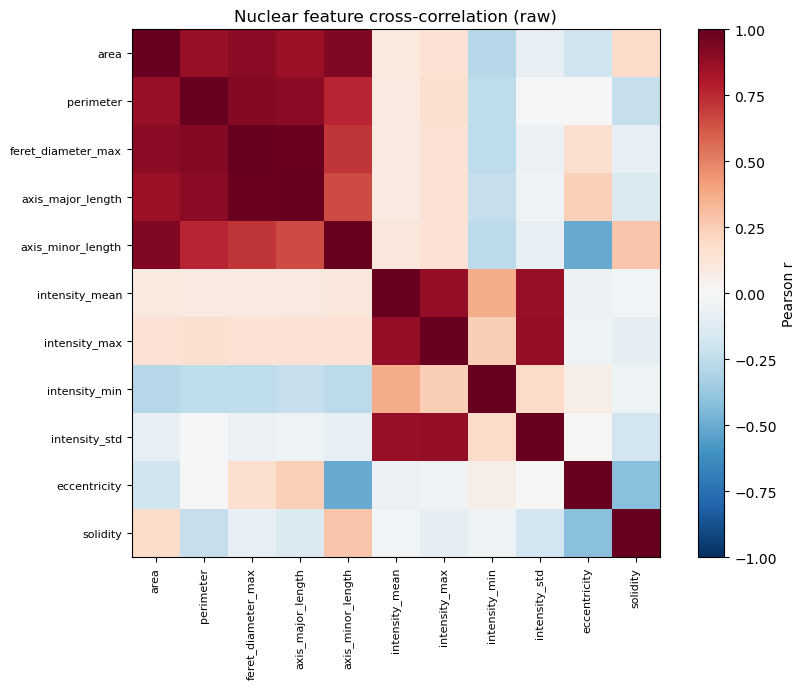

Highly correlated pairs (|r| > 0.9):
  +0.988  feret_diameter_max     axis_major_length
  +0.928  area                   axis_minor_length
  +0.918  perimeter              feret_diameter_max
  +0.902  area                   feret_diameter_max
[full] using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']
[full] dropped 0 rows with NaN/inf; 236718 remain
[full] EVR: [0.396 0.315 0.157 0.11  0.017 0.005]
[full] cumulative: [0.396 0.71  0.867 0.978 0.995 1.   ]


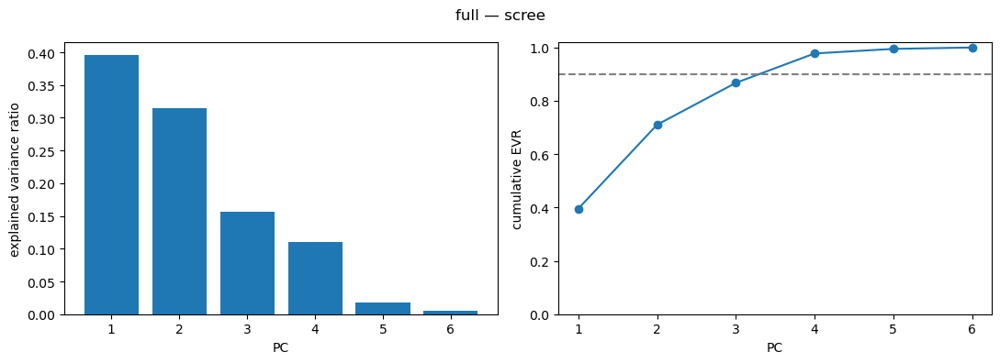

                  PC1    PC2    PC3    PC4    PC5    PC6
area            0.236  0.028  0.944 -0.190  0.124  0.013
intensity_mean -0.000  0.701  0.100  0.149 -0.690 -0.006
intensity_std  -0.092  0.699 -0.084  0.031  0.704  0.008
eccentricity   -0.602 -0.085  0.208  0.326  0.009  0.693
solidity        0.444 -0.085  0.055  0.881  0.111 -0.057
aspect_ratio    0.613  0.073 -0.212 -0.240 -0.015  0.718


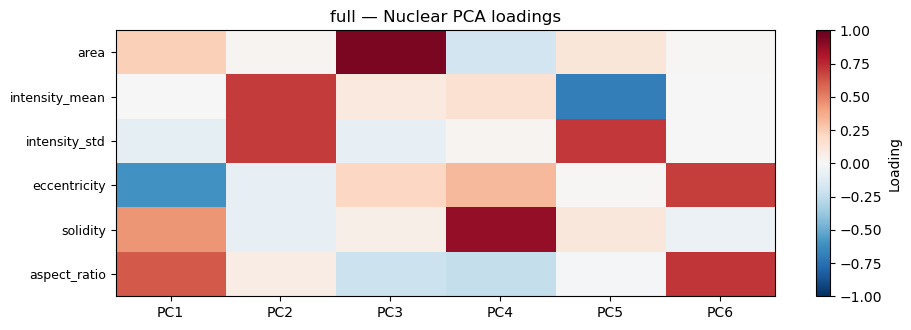

In [23]:
feature_correlation(parental)
parental, pca, FEATURES = fit_pca(parental, label="full")

### PCA plots
#### All parentals


All 21 iNDI_Plate_ID values have a color.


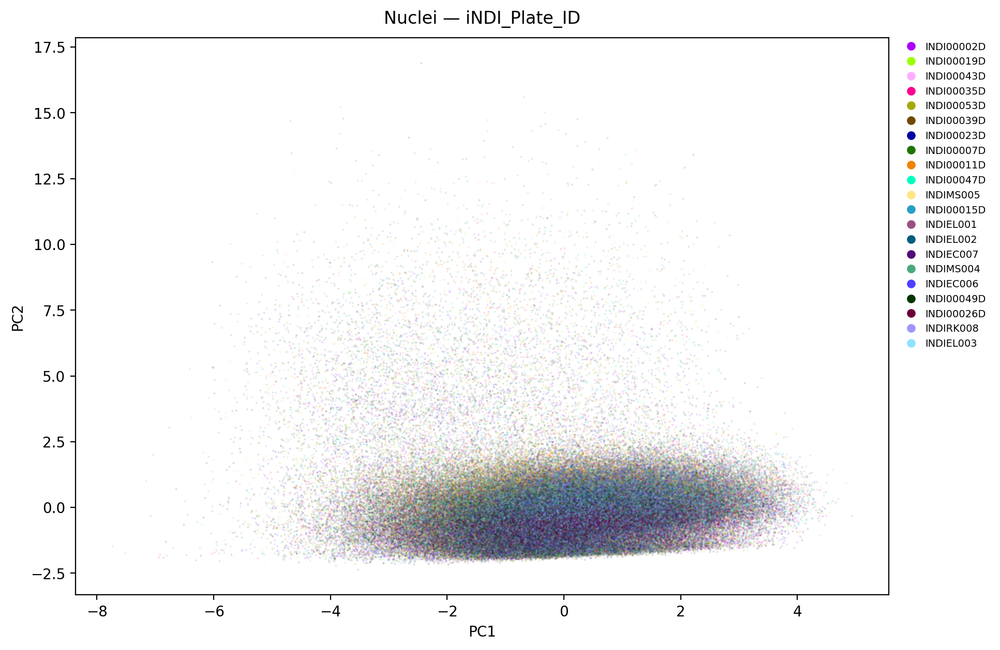

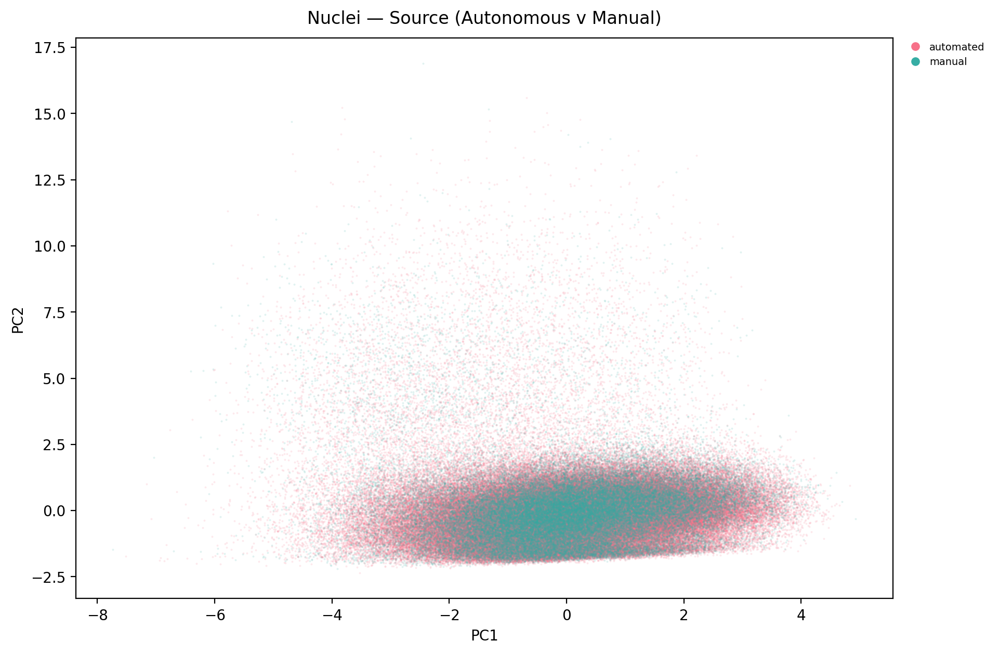

All 5 Batch values have a color.


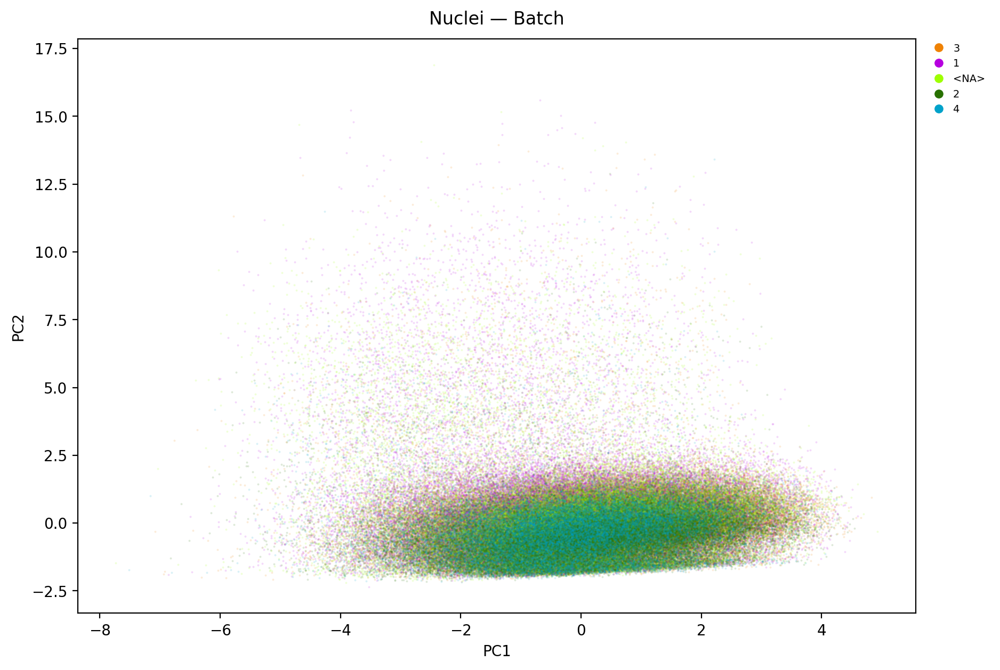

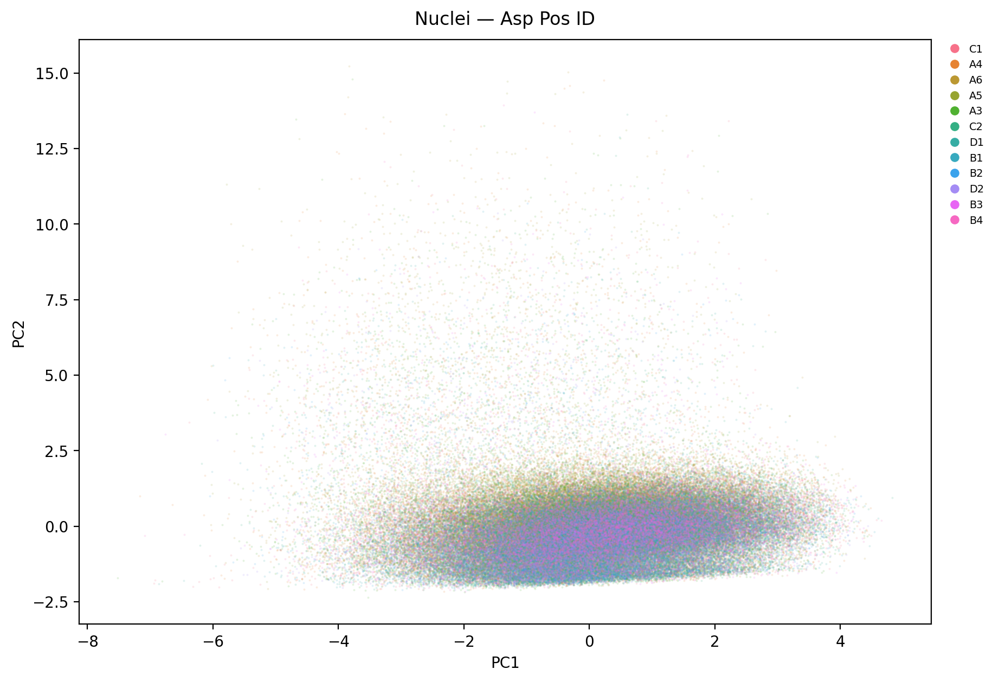

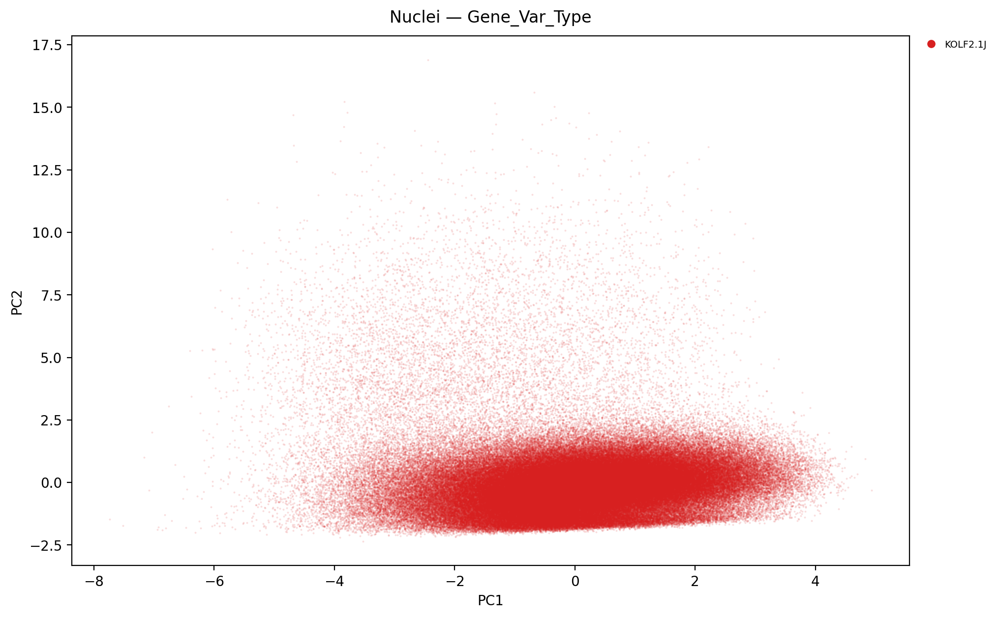

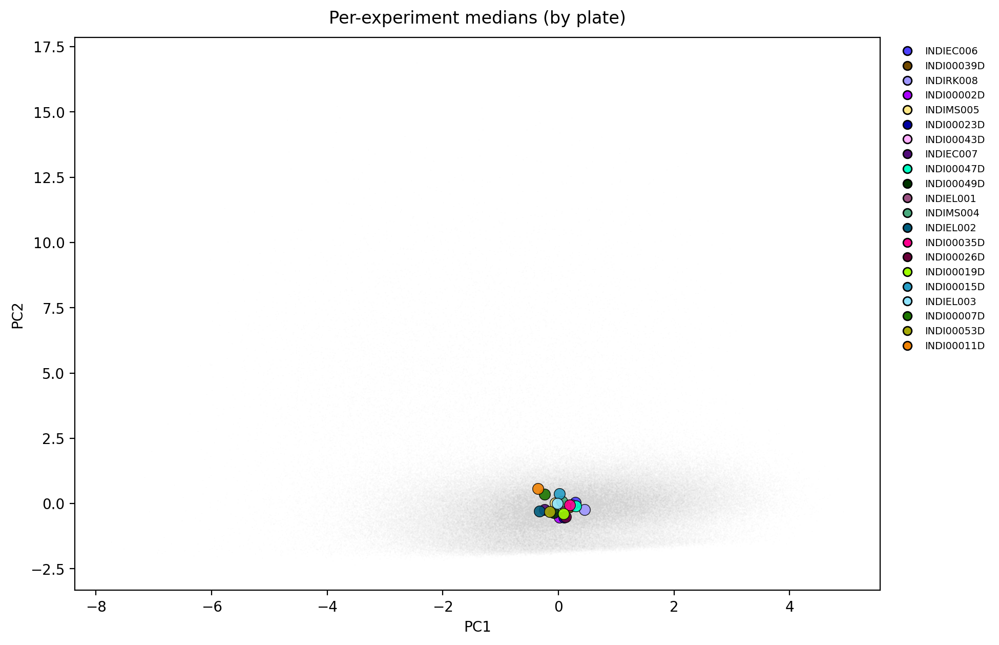

Std of per-experiment centroids (batch magnitude):
PC1    0.213
PC2    0.299
PC3    0.217
dtype: float64


In [24]:
plate_pal = make_palette(parental["iNDI_Plate_ID"])
check_palette_coverage(parental, "iNDI_Plate_ID", plate_pal)
pca_scatter(parental, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Nuclei — iNDI_Plate_ID")

pca_scatter(parental, "Source", figsize=(12, 7),title="Nuclei — Source (Autonomous v Manual)")

batch_palette = make_palette(parental["Batch"])
check_palette_coverage(parental, "Batch", batch_palette)
pca_scatter(parental, "Batch", palette=batch_palette, figsize=(12, 7),title="Nuclei — Batch")

pca_scatter(parental, "Asp PosID", figsize=(12, 7),title="Nuclei — Asp Pos ID")

pca_scatter(parental, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2, title="Nuclei — Gene_Var_Type")

centroid_overlay(parental, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate)")
cent = parental.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

#### Automated parentals

All 13 iNDI_Plate_ID values have a color.


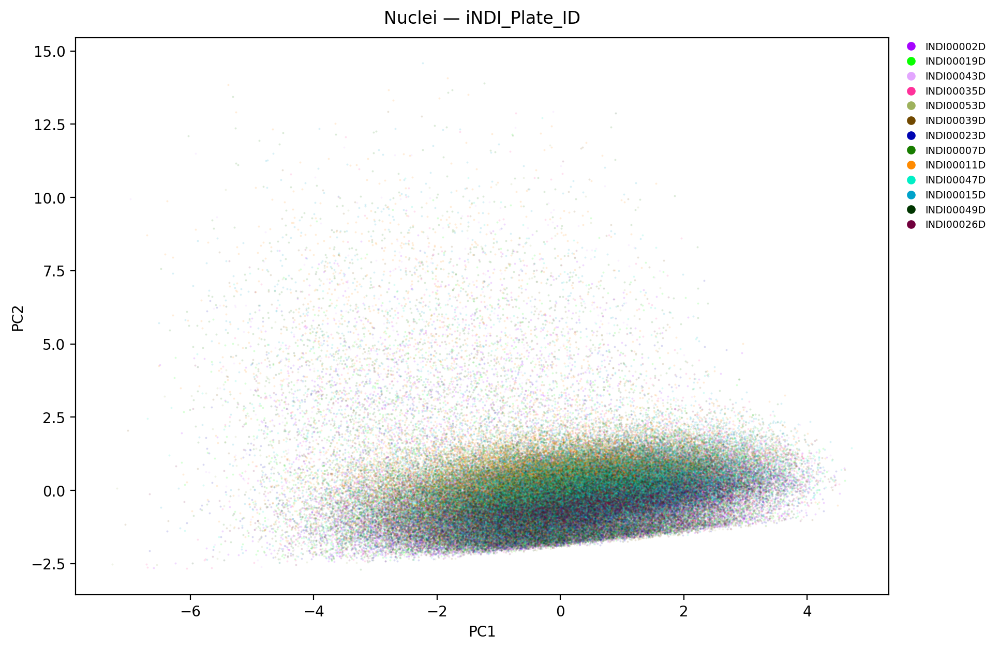

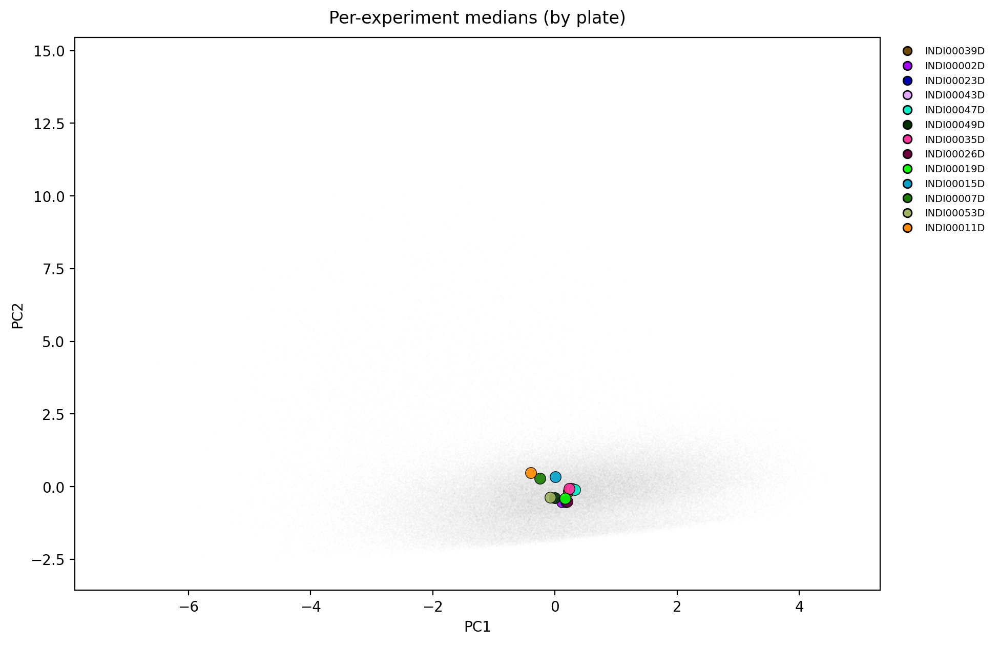

Std of per-experiment centroids (batch magnitude):
PC1    0.214
PC2    0.344
PC3    0.185
dtype: float64
All 4 Batch values have a color.


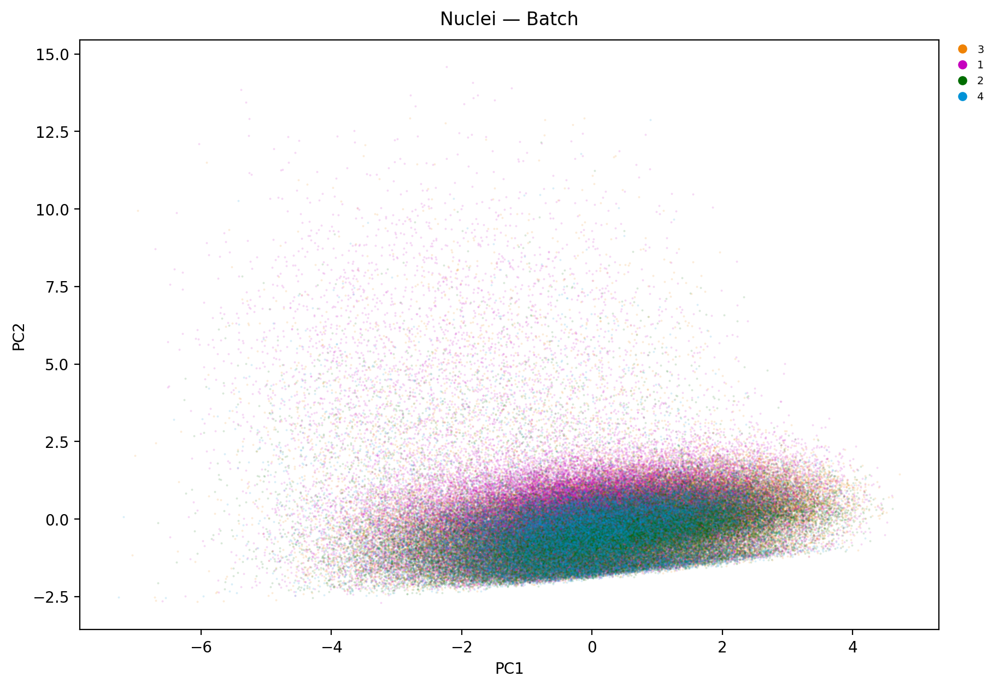

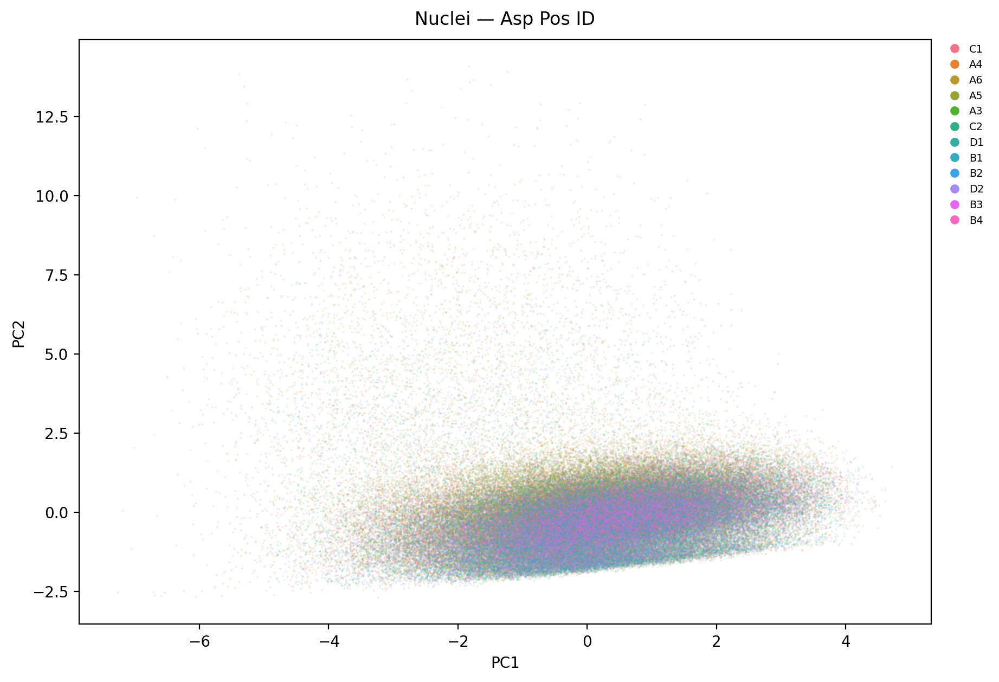

<Axes: title={'center': 'Nuclei — Asp Pos ID'}, xlabel='PC1', ylabel='PC2'>

In [25]:
plate_pal = make_palette(parental_auto["iNDI_Plate_ID"])
check_palette_coverage(parental_auto, "iNDI_Plate_ID", plate_pal)
pca_scatter(parental_auto, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Nuclei — iNDI_Plate_ID")
centroid_overlay(parental_auto, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate)")
cent = parental_auto.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

batch_palette = make_palette(parental_auto["Batch"])
check_palette_coverage(parental_auto, "Batch", batch_palette)
pca_scatter(parental_auto, "Batch", palette=batch_palette, figsize=(12, 7),title="Nuclei — Batch")

pca_scatter(parental_auto, "Asp PosID", figsize=(12, 7),title="Nuclei — Asp Pos ID")

#### Manual parentals

All 8 iNDI_Plate_ID values have a color.


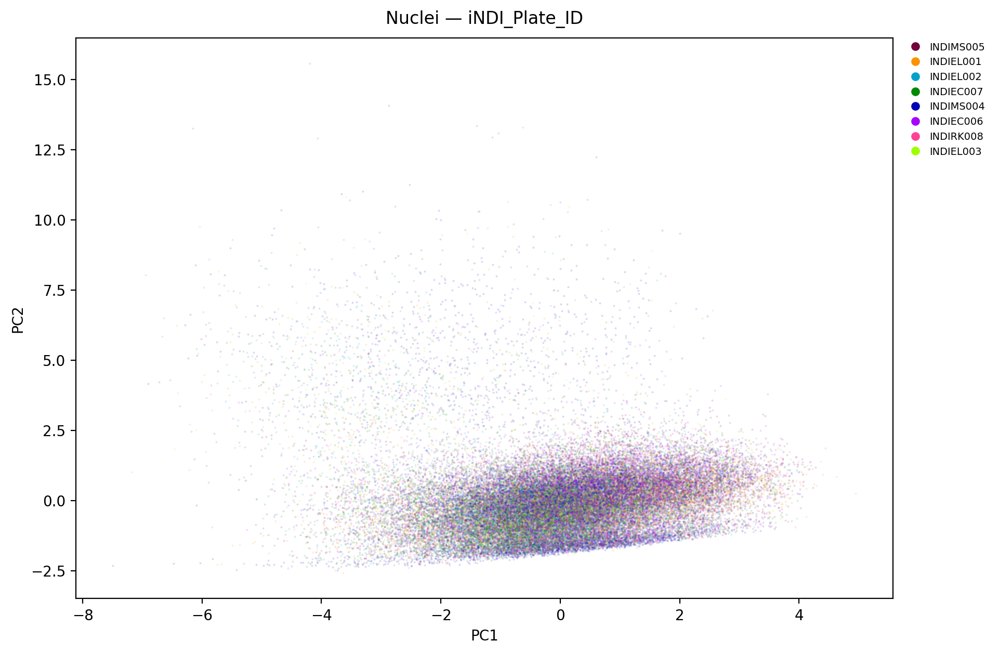

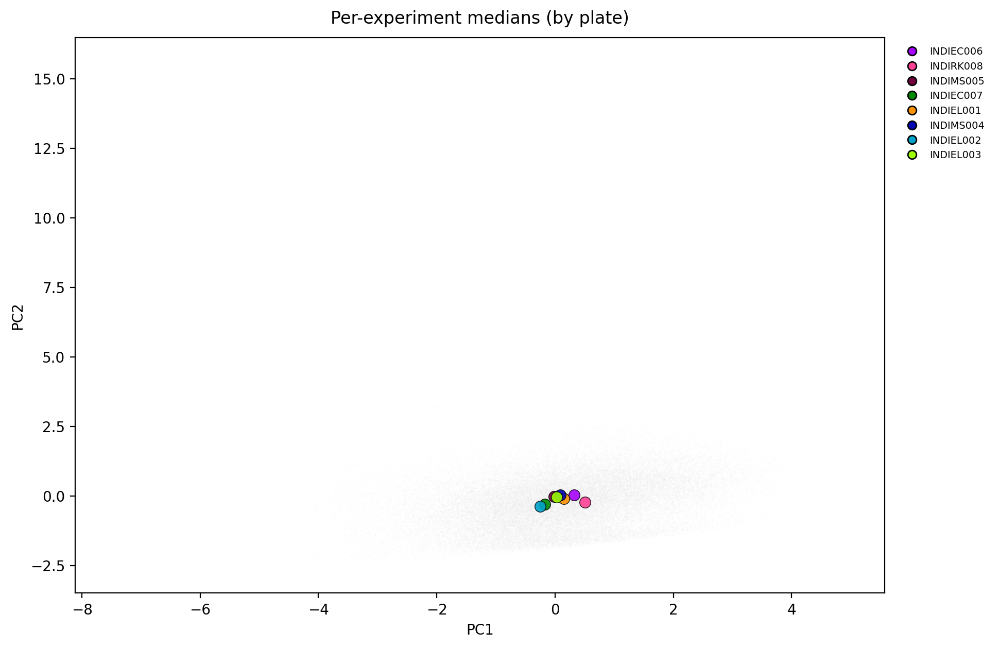

Std of per-experiment centroids (batch magnitude):
PC1    0.248
PC2    0.157
PC3    0.284
dtype: float64
All 1 Batch values have a color.


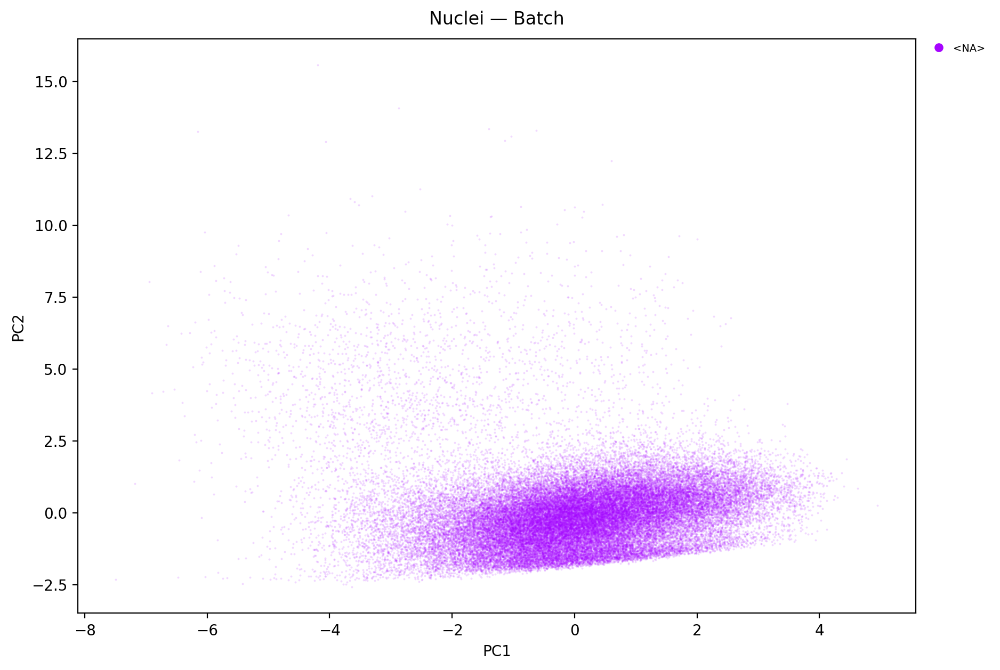

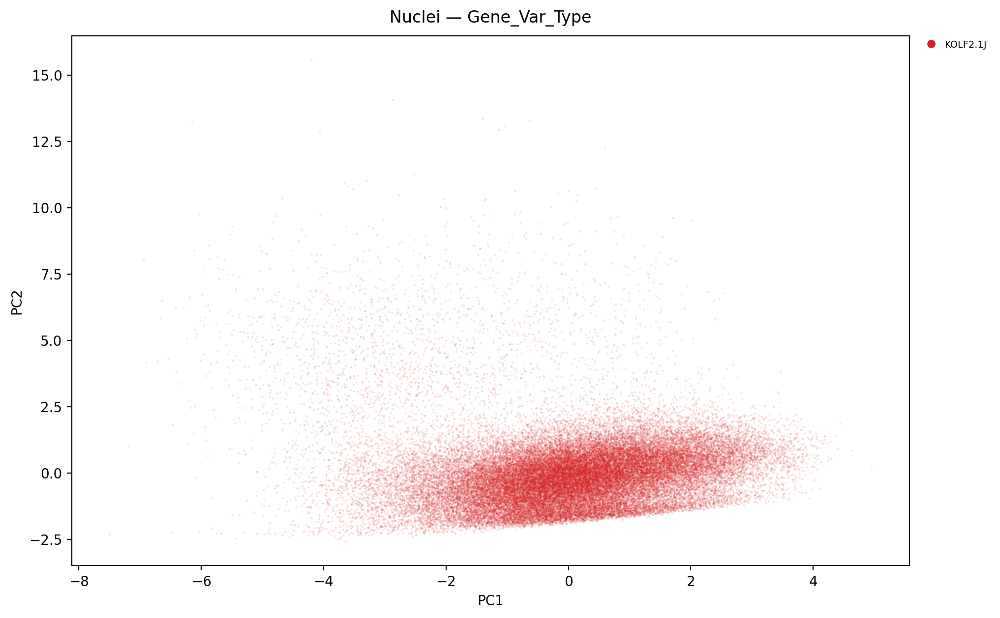

<Axes: title={'center': 'Nuclei — Gene_Var_Type'}, xlabel='PC1', ylabel='PC2'>

In [26]:
plate_pal = make_palette(parental_manual["iNDI_Plate_ID"])
check_palette_coverage(parental_manual, "iNDI_Plate_ID", plate_pal)
pca_scatter(parental_manual, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Nuclei — iNDI_Plate_ID")
centroid_overlay(parental_manual, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate)")
cent = parental_manual.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

batch_palette = make_palette(parental_manual["Batch"])
check_palette_coverage(parental_manual, "Batch", batch_palette)
pca_scatter(parental_manual, "Batch", palette=batch_palette, figsize=(12, 7),title="Nuclei — Batch")

pca_scatter(parental_manual, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2, title="Nuclei — Gene_Var_Type")

## Well-level aggregation
### PCA plots

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 47230 rows (13045 images)
[full] well-level: 1450 rows
[full well] using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']
[full well] dropped 0 rows with NaN/inf; 1450 remain
[full well] EVR: [0.439 0.294 0.144 0.09  0.031 0.003]
[full well] cumulative: [0.439 0.732 0.876 0.966 0.997 1.   ]


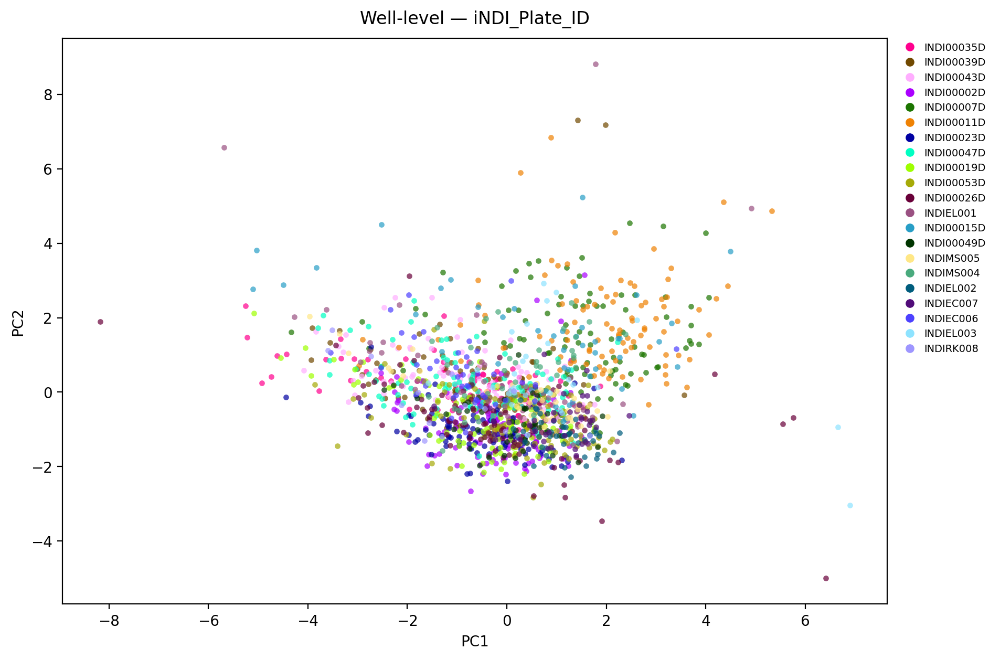

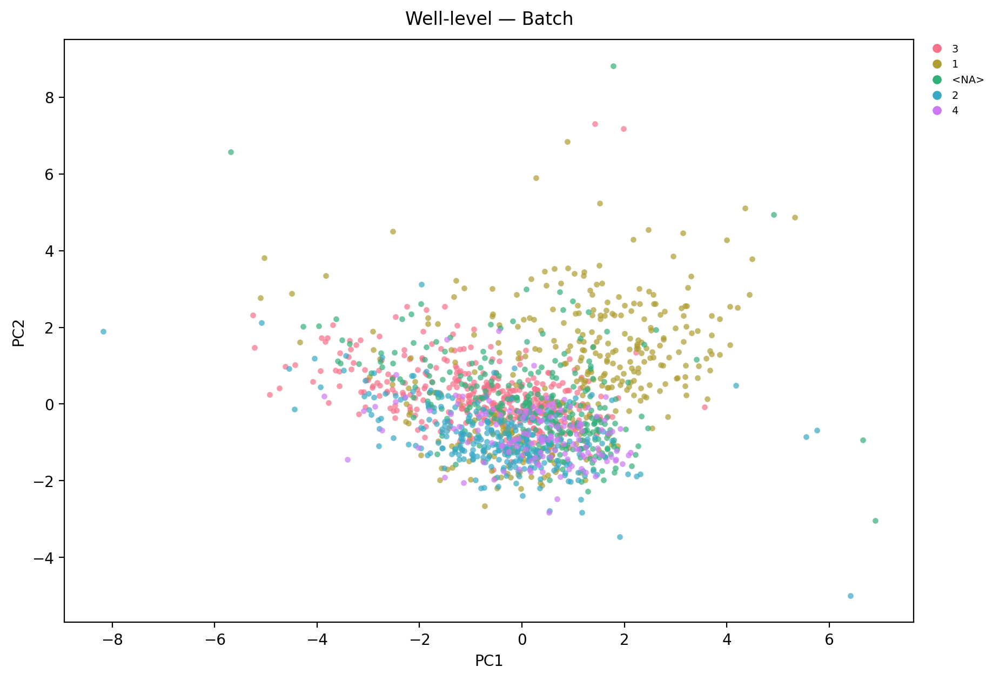

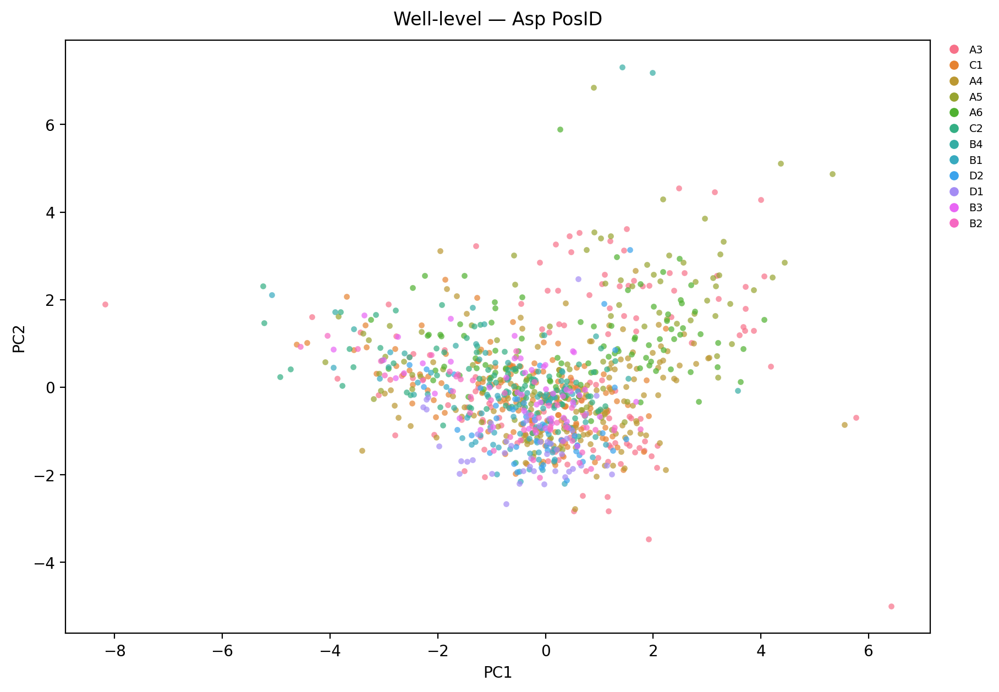

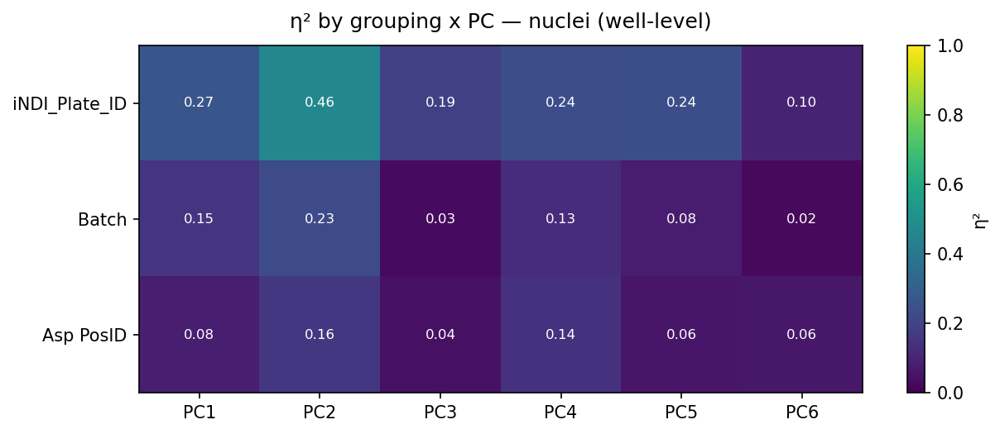

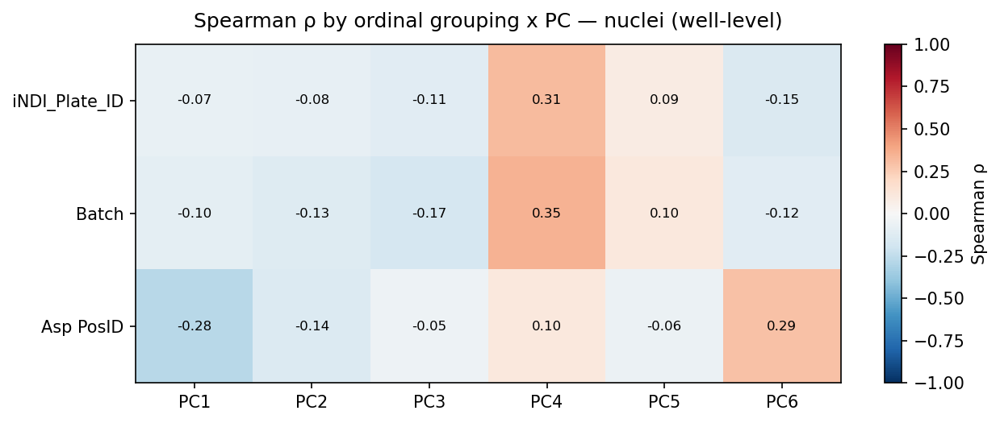

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,-0.073396,-0.083378,-0.114858,0.314528,0.085437,-0.146895
Batch,-0.100580,-0.126062,-0.166315,0.345731,0.101594,-0.116073
Asp PosID,-0.277174,-0.140463,-0.053715,0.102636,-0.055301,0.291943


In [27]:
well_level = aggregate_wells(parental, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_shuf["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Batch", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Batch")
pca_scatter(well_shuf, "Asp PosID", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Asp PosID")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID"],
            n_pcs=6, title="η² by grouping x PC — nuclei (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — nuclei (well-level)")

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 37040 rows (12894 images)
[full] well-level: 1142 rows
[full well] using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']
[full well] dropped 0 rows with NaN/inf; 1142 remain
[full well] EVR: [0.453 0.288 0.158 0.074 0.024 0.003]
[full well] cumulative: [0.453 0.74  0.898 0.972 0.997 1.   ]


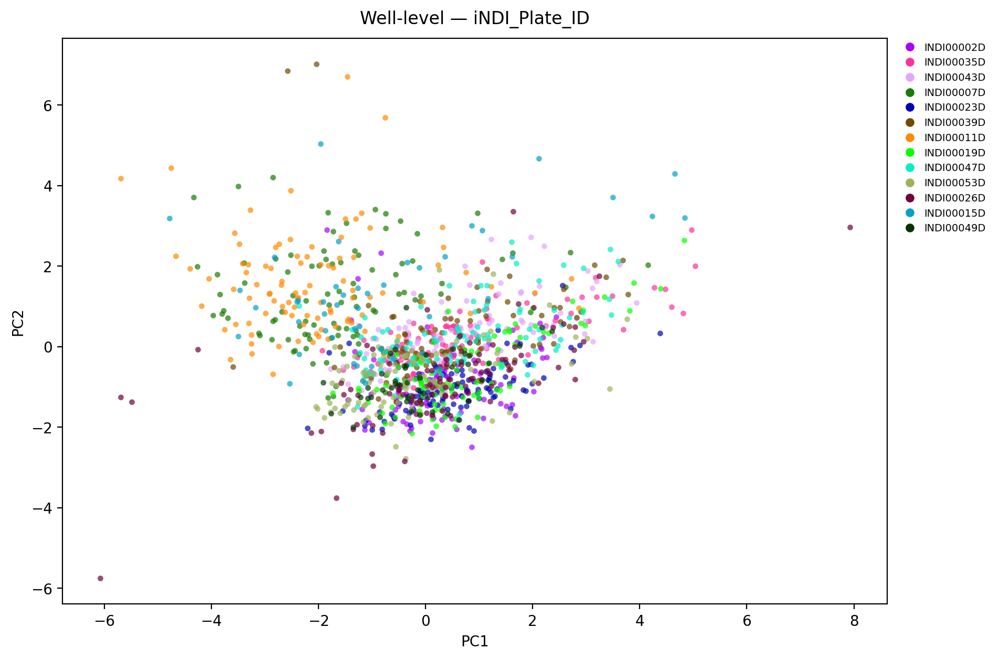

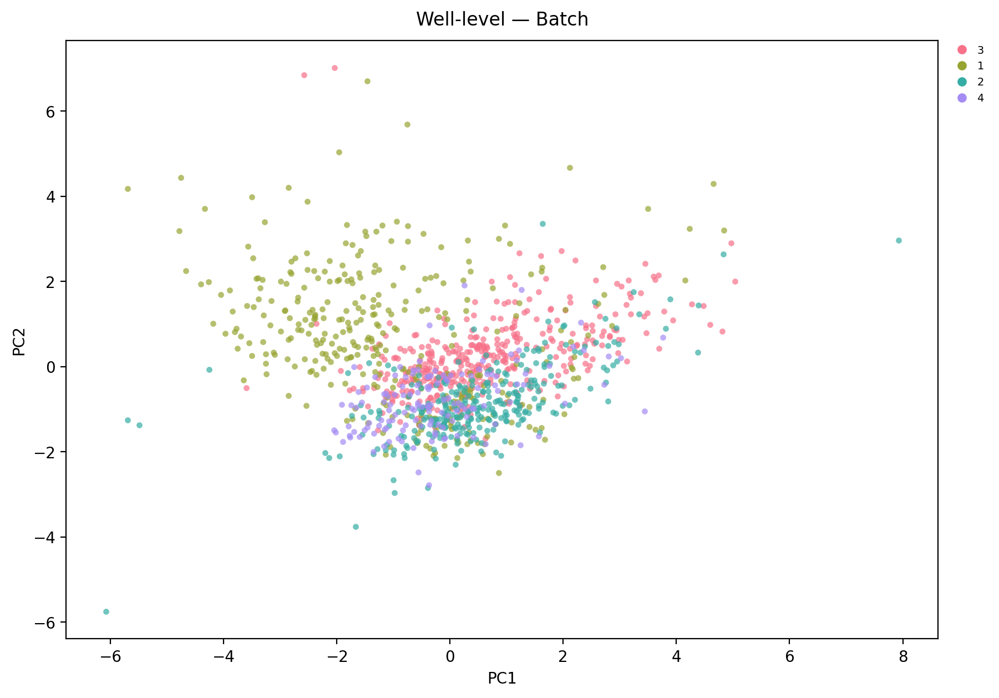

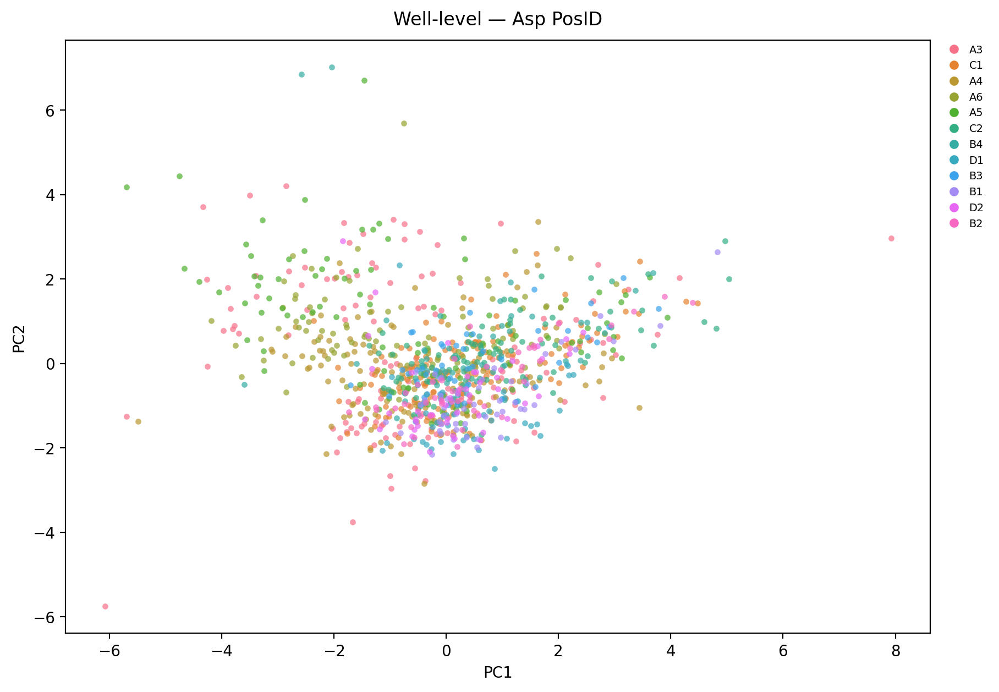

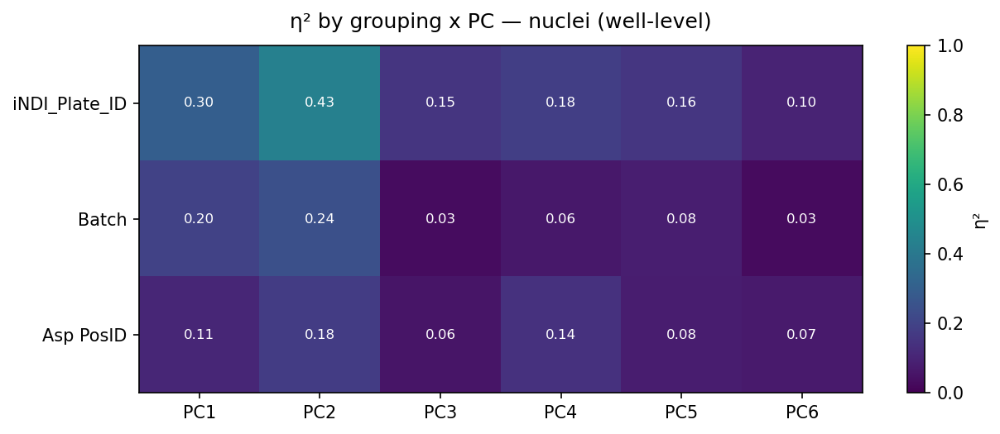

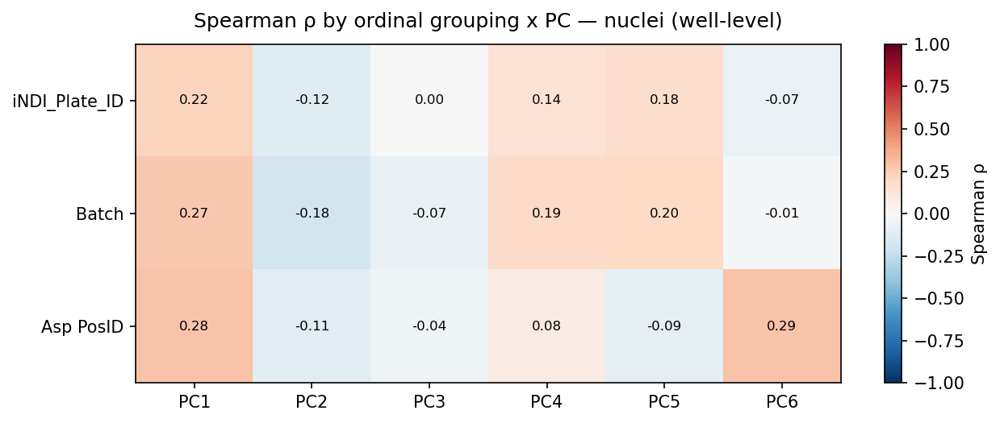

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,0.223395,-0.118264,0.000051,0.143391,0.176242,-0.067401
Batch,0.267605,-0.180711,-0.073530,0.189058,0.195973,-0.012265
Asp PosID,0.281296,-0.114467,-0.044930,0.079915,-0.088235,0.288234


In [28]:
well_level = aggregate_wells(parental_auto, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_shuf["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Batch", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Batch")
pca_scatter(well_shuf, "Asp PosID", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Asp PosID")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID"],
            n_pcs=6, title="η² by grouping x PC — nuclei (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — nuclei (well-level)")

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 10190 rows (3750 images)
[full] well-level: 308 rows
[full well] using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']
[full well] dropped 0 rows with NaN/inf; 308 remain
[full well] EVR: [0.435 0.267 0.137 0.109 0.049 0.002]
[full well] cumulative: [0.435 0.703 0.839 0.949 0.998 1.   ]


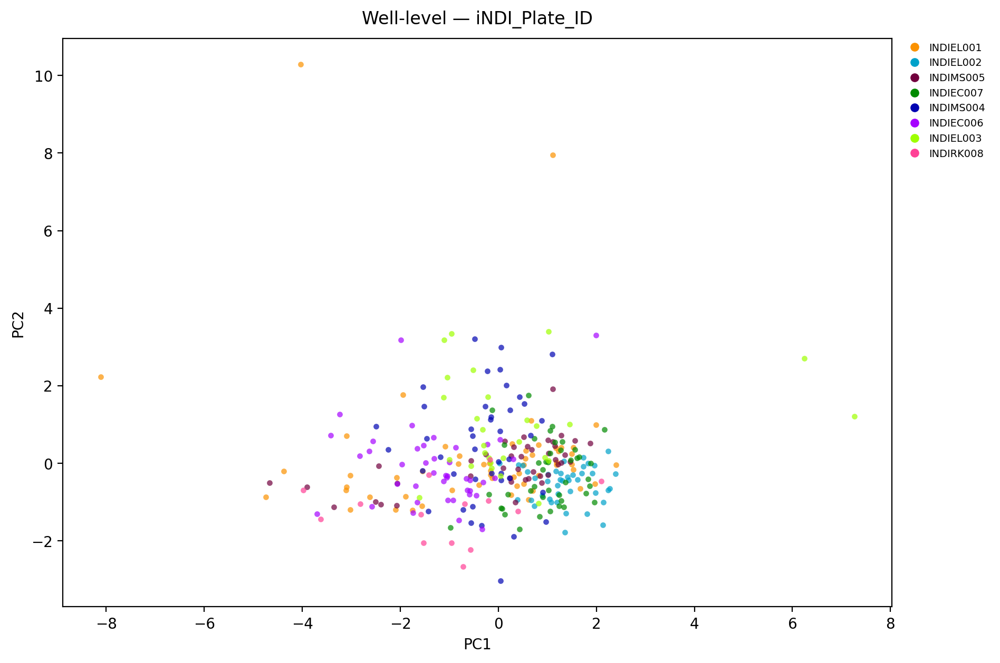

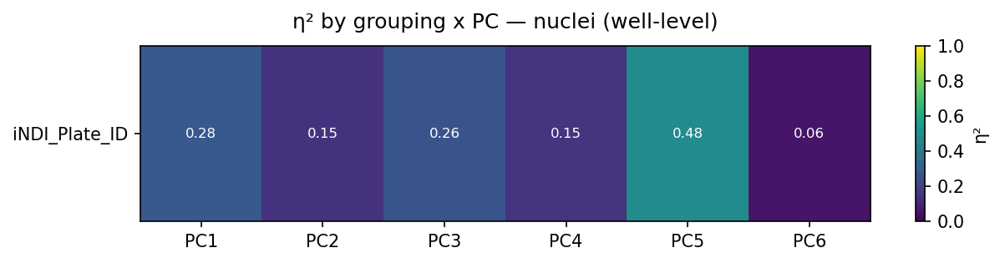

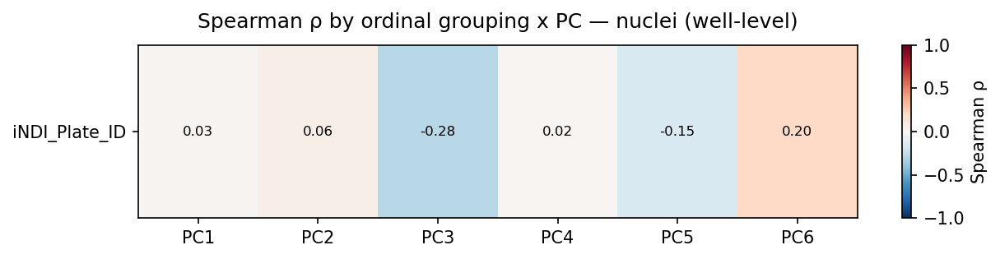

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,0.029453,0.057941,-0.276053,0.021529,-0.1514,0.20109


In [29]:
well_level = aggregate_wells(parental_manual, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_shuf["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID"],
            n_pcs=6, title="η² by grouping x PC — nuclei (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — nuclei (well-level)")

In [30]:
build_pptx("/data/kelpschdj/iNDI/Production/notebooks/analysis_uoe5/uoe5_nucleus_analysis.pptx")

wrote 162 slides -> /data/kelpschdj/iNDI/Production/notebooks/analysis_uoe5/uoe5_nucleus_analysis.pptx
